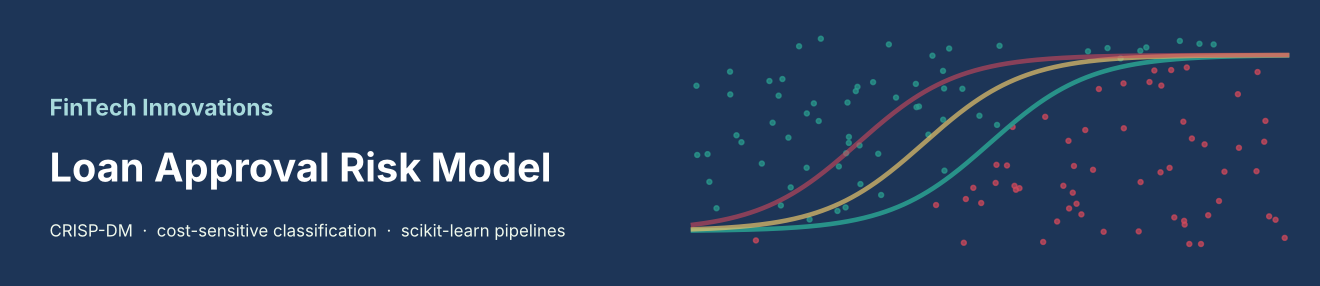

# Predicting Loan Approval at FinTech Innovations
### A cost-sensitive, interpretable machine-learning pipeline for standardising loan decisions

**Framework:** CRISP-DM &nbsp;|&nbsp; **Problem type:** Binary classification (with probability-based risk scores) &nbsp;|&nbsp; **Data:** 20,000 historical loan applications

## Overview

**Bottom line up front:** A tuned **HistGradientBoosting classifier**, wrapped in a single scikit-learn pipeline and operated at a **cost-optimised approval threshold of 0.865** (instead of the default 0.5), cuts the expected error cost of loan decisions by **68%**: from **\$1,912 to \$617 per application** on a held-out test set of 4,000 applications. That is roughly **\$25.9M saved per 20,000 applications** compared with the safest naive policy (deny everyone). The model ranks applicants almost perfectly (**ROC-AUC 0.994**), and **98.6% of the loans it approves are genuinely good**: only 10 bad approvals out of 4,000 decisions. Setting the threshold from business costs instead of accepting 0.5 is worth a lot on its own: it cuts cost by a further 36% (\$964 → \$617 per application). Used as a **three-tier triage tool**, the model auto-decides **87% of applications** (18% auto-approve, 69% auto-decline) and sends the uncertain **13%** to loan officers. The main drivers are affordability and pricing (total debt-to-income, income, interest rate), then credit score and credit history. Marital status adds **no** predictive value and can be removed. Two caveats matter. First, the labels are **historical approval decisions**, not observed repayment, so the model reproduces past policy. Second, two leakage sources had to be neutralised: `RiskScore`, and the pattern of missing education values.

### Notebook roadmap (CRISP-DM)

| # | CRISP-DM phase | What happens here |
|---|---|---|
| 1 | **Business Understanding** | Process, stakeholders, cost of errors (\$8k vs \$50k), classification vs regression, metrics & targets |
| 2 | **Data Understanding** | Data quality audit, univariate/bivariate/multivariate EDA, statistical tests, missingness, outliers, leakage check |
| 3 | **Data Preparation** | Custom transformers, `ColumnTransformer` + `Pipeline` + `FeatureUnion`, imputation comparison, feature selection |
| 4 | **Modeling** | 7 algorithms + 2 ensembles, classification vs regression comparison, multi-stage hyperparameter tuning, threshold optimisation |
| 5 | **Evaluation** | Test-set performance, dollar impact, segment & fairness analysis, feature importance, limitations |
| 6 | **Deployment / Conclusion** | Executive summary, implementation plan, improvements |

## 1. Business Understanding

### 1.1 The current process and its limitations
FinTech Innovations partners with traditional banks to modernise their loan approval processes. Today every application is **reviewed manually by a loan officer**, who reads the applicant's credit file, income and balance-sheet information and makes an approve/deny call. That creates four problems:

| Limitation | Business consequence |
|---|---|
| **Inconsistency** – two officers can reach different decisions on near-identical files | Unfair treatment of applicants, regulatory exposure, unpredictable portfolio quality |
| **Slow turnaround** – every file waits in a human queue | Applicants abandon or go to faster competitors; officers' time is spent on easy cases |
| **Hidden bias** – judgment can be swayed by factors unrelated to creditworthiness (e.g. marital status, age) | Fair-lending risk; creditworthy applicants overlooked |
| **No explicit cost trade-off** – officers don't see the \$8k / \$50k asymmetry quantified | Decisions are not optimised for profitability |

### 1.2 Stakeholders and their needs

| Stakeholder | What they need from the model | How this project addresses it |
|---|---|---|
| **Loan officers** | A trustworthy score and *reasons* for each recommendation; fewer easy files in their queue | Calibrated approval probability, per-feature drivers, three-tier triage (auto-approve / review / auto-decline) |
| **Risk & credit management** | Fewer defaults, controlled loss rate, predictable portfolio | Custom **business-cost metric** that weights a bad approval at \$50k; precision of approvals tracked explicitly |
| **Executive management / partner banks** | Profitability, speed, scalability | Dollar savings vs current policy, % of applications that can be automated |
| **Applicants (customers)** | Fast, fair, explainable decisions | Faster decisions for clear-cut cases; segment-level fairness audit; reason codes |
| **Compliance / regulators** | Explainability, non-discrimination (e.g. fair-lending rules on age & marital status), auditability | Interpretable models compared, permutation importance, fairness checks, documented pipeline |
| **Data science / IT** | Reproducible, maintainable pipeline | Single scikit-learn `Pipeline` object from raw data to prediction, saved with `joblib` |

### 1.3 Implications of model errors (positive class = **1 = Approved / creditworthy**)

| Outcome | Meaning | Business cost |
|---|---|---|
| True Positive (TP) | Good applicant approved | Profit earned (baseline) |
| True Negative (TN) | Bad applicant denied | Loss avoided |
| **False Positive (FP)** | **Bad applicant approved → loan defaults** | **\$50,000** (principal + collection costs) |
| **False Negative (FN)** | **Good applicant denied** | **\$8,000** (lost profit) |

A false approval is **6.25× more expensive** than a false denial. This has a direct, quantitative consequence for how we must use any model:

If the model outputs a calibrated probability $p$ that an applicant is creditworthy, the expected cost of each decision is

$$E[\text{cost} \mid \text{approve}] = (1-p)\times 50{,}000 \qquad E[\text{cost} \mid \text{deny}] = p \times 8{,}000$$

Approving is cheaper only when $(1-p)\,50{,}000 < p\,8{,}000$, i.e. when

$$p > \frac{50{,}000}{50{,}000 + 8{,}000} \approx 0.862$$

So the default 0.5 threshold is **wrong for this business** – we should only approve when the model is ~86% confident (we verify and refine this empirically later).

### 1.4 Classification vs regression – which approach?

The brief allows either (a) **regression** on `RiskScore` or (b) **classification** on `LoanApproved`. We choose **classification**, for four reasons:

1. **The business costs are defined on decisions.** The \$8k / \$50k figures attach to *approve/deny errors*, which map directly onto a confusion matrix. A regression on RiskScore would still need an arbitrary cut-off to become a decision.
2. **Target leakage in `RiskScore`.** In the data-generation logic documented with the Kaggle source, `RiskScore` is computed *after* the decision and multiplied by 0.8 for approved loans. It therefore contains the answer and cannot be used as a feature – and as a target it partly encodes the past decision rather than independent risk (demonstrated in EDA §2.4 and in the regression experiment in §4.3).
3. **We still get a risk score.** A probabilistic classifier outputs $P(\text{approve})$; $1-P$ *is* a risk score loan officers can use. Classification gives us the decision *and* the score.
4. **Evaluation is clearer.** Precision, recall, ROC-AUC and dollar cost are all interpretable to stakeholders.

We nonetheless **build and compare a regression model** in §4.3 to justify this decision empirically.

### 1.5 Modeling goals, metrics and success criteria

| Metric | Type | Why we use it |
|---|---|---|
| **Business cost per application (custom)** – $\dfrac{50{,}000\cdot FP + 8{,}000\cdot FN}{n}$ | **Primary**, threshold-dependent | Directly measures what the business loses; used as the `refit` criterion in tuning and to choose the decision threshold |
| **ROC-AUC** | Secondary, threshold-free | How well the model *ranks* applicants by creditworthiness, independent of the threshold – needed because we tune the threshold separately |
| **Average Precision (PR-AUC)** | Secondary, imbalance-aware | Only ~24% of applications are approved; PR-AUC focuses on the minority (approved) class and is not inflated by the many easy denials |
| **Precision on approvals** | Diagnostic | Of loans we approve, what share are truly good? Each miss costs \$50k – risk management's key number |
| **Recall on approvals** | Diagnostic | Of good applicants, what share do we approve? Each miss costs \$8k – sales/customer view |

Accuracy is reported for completeness but **not used for decisions**: a model that denies everyone is already 76% accurate.

**Baselines and targets** (computed below on the full dataset):
* *Deny everyone* (the safest naive policy) and *approve everyone* define the floor.
* A `DummyClassifier` defines the "no-skill" ML baseline.
* **Success criteria:** (1) ROC-AUC ≥ 0.95; (2) precision on approvals ≥ 0.90 at the operating threshold; (3) **≥ 50% reduction in business cost per application versus the best naive policy**; (4) a model whose drivers can be explained to compliance.

In [1]:
# ============================================================
# Imports & global configuration
# ============================================================
import warnings, time, sys
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

import sklearn
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV,
                                     TunedThresholdClassifierCV)
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder,
                                   FunctionTransformer, KBinsDiscretizer)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, VotingClassifier, StackingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, make_scorer, roc_curve,
                             precision_recall_curve, r2_score, mean_absolute_error, mean_squared_error)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import loguniform, randint, uniform
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)
set_config(display='diagram')

# Consistent visual identity: red = denied, teal = approved
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95)
PALETTE = {0: '#d1495b', 1: '#2a9d8f'}
LABELS = {0: 'Denied', 1: 'Approved'}
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.13.18 | pandas 3.0.5 | scikit-learn 1.9.1


In [2]:
# ============================================================
# Business cost definitions -> custom metric & scorers
# ============================================================
COST_FP = 50_000   # approving a loan that should have been denied (default: principal + collections)
COST_FN = 8_000    # denying a creditworthy applicant (lost profit)
BAYES_THRESHOLD = COST_FP / (COST_FP + COST_FN)   # cost-optimal threshold for a calibrated model

def business_cost(y_true, y_pred):
    '''Total dollar cost of a set of approve(1)/deny(0) decisions.'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fp * COST_FP + fn * COST_FN

def cost_per_application(y_true, y_pred):
    '''Average dollar cost per application - comparable across data sets of different size.'''
    return business_cost(y_true, y_pred) / len(y_true)

# Scorers that work on probabilities, applying the cost-optimal threshold.
# Using probabilities (not .predict at 0.5) makes model comparison reflect how the model will really be used.
def _cost_at_t(y_true, proba):      return cost_per_application(y_true, (proba >= BAYES_THRESHOLD).astype(int))
def _precision_at_t(y_true, proba): return precision_score(y_true, (proba >= BAYES_THRESHOLD).astype(int), zero_division=0)
def _recall_at_t(y_true, proba):    return recall_score(y_true, (proba >= BAYES_THRESHOLD).astype(int), zero_division=0)

cost_scorer      = make_scorer(_cost_at_t, greater_is_better=False, response_method='predict_proba')
precision_scorer = make_scorer(_precision_at_t, response_method='predict_proba')
recall_scorer    = make_scorer(_recall_at_t, response_method='predict_proba')
cost_label_scorer = make_scorer(cost_per_application, greater_is_better=False)   # for threshold tuning on labels

SCORING = {'cost': cost_scorer, 'roc_auc': 'roc_auc', 'avg_precision': 'average_precision',
           'precision': precision_scorer, 'recall': recall_scorer}

print(f'Cost ratio FP:FN = {COST_FP/COST_FN:.2f} : 1')
print(f'Cost-optimal probability threshold = {BAYES_THRESHOLD:.3f}')

Cost ratio FP:FN = 6.25 : 1
Cost-optimal probability threshold = 0.862


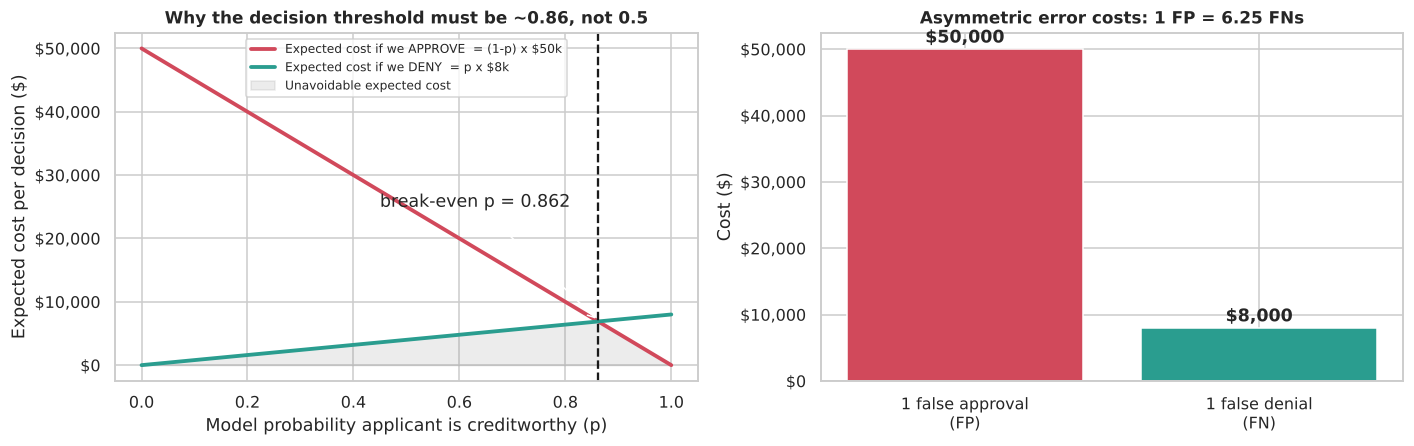

In [3]:
# ============================================================
# Visualising the cost trade-off: expected cost of each decision vs model confidence
# ============================================================
p = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(p, (1 - p) * COST_FP, color=PALETTE[0], lw=2.5, label='Expected cost if we APPROVE  = (1-p) x $50k')
axes[0].plot(p, p * COST_FN, color=PALETTE[1], lw=2.5, label='Expected cost if we DENY  = p x $8k')
axes[0].axvline(BAYES_THRESHOLD, ls='--', color='k')
axes[0].annotate(f'break-even p = {BAYES_THRESHOLD:.3f}', xy=(BAYES_THRESHOLD, 7000),
                 xytext=(0.45, 25000), arrowprops=dict(arrowstyle='->'))
axes[0].fill_between(p, 0, np.minimum((1 - p) * COST_FP, p * COST_FN), color='grey', alpha=.15,
                     label='Unavoidable expected cost')
axes[0].set(xlabel='Model probability applicant is creditworthy (p)', ylabel='Expected cost per decision ($)',
            title='Why the decision threshold must be ~0.86, not 0.5')
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
axes[0].legend(fontsize=8)

# Iso-cost view: how many false denials equal one false approval
fp_range = np.arange(0, 11)
axes[1].bar(['1 false approval\n(FP)', '1 false denial\n(FN)'], [COST_FP, COST_FN], color=[PALETTE[0], PALETTE[1]])
for i, v in enumerate([COST_FP, COST_FN]):
    axes[1].text(i, v + 1000, f'${v:,.0f}', ha='center', fontweight='bold')
axes[1].set(title=f'Asymmetric error costs: 1 FP = {COST_FP/COST_FN:.2f} FNs', ylabel='Cost ($)')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout(); plt.show()

**Reading the chart:** the two expected-cost lines cross at *p* ≈ 0.862. Left of the line, denying is cheaper; right of it, approving is cheaper. Because a bad approval costs 6.25× more than a missed good loan, the model must be strongly confident before recommending approval. This drives three design decisions: (1) our custom metric scores models at this threshold, (2) we check probability **calibration**, and (3) we fine-tune the threshold empirically on cross-validated predictions.

## 2. Data Understanding

### 2.1 Basic data characteristics

In [4]:
DATA_PATH = 'financial_loan_data.csv'
raw = pd.read_csv(DATA_PATH)
print(f'Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
raw.head()

Shape: 20,000 rows x 35 columns


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.3544,1,2,0.3583,No,Home,0,29,9,"7,632.0000",1202,146111,19183,"3,329.0000",0.7250,11,126928,0.1997,0.2276,419.8060,0.1811,0,49.0000
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.0878,5,3,0.3303,No,Debt Consolidation,0,21,9,"4,627.0000",3460,53204,9595,"3,309.0833",0.9351,3,43609,0.2070,0.2011,794.0542,0.3899,0,52.0000
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.1374,2,0,0.2447,No,Education,0,20,22,886.0000,895,25176,128874,"3,393.6667",0.8722,6,5205,0.2176,0.2125,666.4067,0.4622,0,52.0000
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.2676,2,1,0.4362,No,Home,0,27,10,"1,675.0000",1217,104822,5370,"5,757.0000",0.8962,5,99452,0.3004,0.3009,"1,047.5070",0.3131,0,54.0000
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.3205,0,0,0.0789,No,Debt Consolidation,0,26,27,"1,555.0000",4981,244305,17286,"8,605.3333",0.9414,5,227019,0.1972,0.1760,330.1791,0.0702,1,36.0000


In [5]:
# Column-level profile: dtype, missing values, cardinality and an example value
profile = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'n_missing': raw.isna().sum(),
    'pct_missing': (raw.isna().mean() * 100).round(2),
    'n_unique': raw.nunique(),
    'example': raw.iloc[0],
})
profile

,dtype,n_missing,pct_missing,n_unique,example
Age,int64,0,0.0000,63,45
AnnualIncome,str,0,0.0000,17516,"$39,948.00"
CreditScore,int64,0,0.0000,322,617
EmploymentStatus,str,0,0.0000,3,Employed
EducationLevel,str,901,4.5000,5,Master
Experience,int64,0,0.0000,62,22
LoanAmount,int64,0,0.0000,15578,13152
LoanDuration,int64,0,0.0000,10,48
MaritalStatus,str,1331,6.6500,4,Married
NumberOfDependents,int64,0,0.0000,6,2


### 2.2 Data quality audit
The brief warns that messy data was deliberately introduced. We audit the raw file systematically *before* any modelling.

In [6]:
issues = {}

# 1. Numeric data stored as text
issues['AnnualIncome stored as currency text'] = raw['AnnualIncome'].astype(str).str.contains(r'[\$,]').sum()
print('AnnualIncome sample values:', raw['AnnualIncome'].head(3).tolist())

# 2. Binary flag stored as Yes/No text (other binary flags are 0/1 integers)
print('BankruptcyHistory values :', raw['BankruptcyHistory'].value_counts().to_dict())
print('PreviousLoanDefaults vals:', raw['PreviousLoanDefaults'].value_counts().to_dict())
issues['BankruptcyHistory encoded as Yes/No'] = raw['BankruptcyHistory'].isin(['Yes', 'No']).sum()

# 3. Missing values
for c in raw.columns[raw.isna().any()]:
    issues[f'Missing {c}'] = raw[c].isna().sum()

# 4. Duplicates
issues['Duplicate rows'] = raw.duplicated().sum()

# 5. Whitespace / casing inconsistencies in categoricals
cat_cols_raw = ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']
for c in cat_cols_raw:
    s = raw[c].dropna()
    issues[f'{c}: untrimmed / mixed-case labels'] = (s != s.str.strip().str.title()).sum() if c != 'EducationLevel' else (s != s.str.strip()).sum()

pd.Series(issues, name='count').to_frame()

AnnualIncome sample values: ['$39,948.00', '$39,709.00', '$40,724.00']
BankruptcyHistory values : {'No': 18952, 'Yes': 1048}
PreviousLoanDefaults vals: {0: 17999, 1: 2001}


,count
AnnualIncome stored as currency text,20000
BankruptcyHistory encoded as Yes/No,20000
Missing EducationLevel,901
Missing MaritalStatus,1331
Missing SavingsAccountBalance,572
Duplicate rows,0
EmploymentStatus: untrimmed / mixed-case labels,0
EducationLevel: untrimmed / mixed-case labels,0
MaritalStatus: untrimmed / mixed-case labels,0
HomeOwnershipStatus: untrimmed / mixed-case labels,0


In [7]:
# ------------------------------------------------------------
# Deterministic, row-wise cleaning (no statistics learned from data -> safe to apply before the split)
# ------------------------------------------------------------
def clean_raw(df):
    df = df.copy()
    # Currency text -> float
    df['AnnualIncome'] = pd.to_numeric(
        df['AnnualIncome'].astype(str).str.replace(r'[\$,\s]', '', regex=True), errors='coerce')
    # Yes/No -> 1/0 to match PreviousLoanDefaults
    df['BankruptcyHistory'] = (df['BankruptcyHistory'].astype(str).str.strip().str.title()
                               .map({'Yes': 1, 'No': 0}).astype(float))
    # Normalise categorical text but keep NaN as NaN (imputed later inside the pipeline)
    for c in cat_cols_raw:
        df[c] = df[c].where(df[c].isna(), df[c].astype(str).str.strip())
    return df

df = clean_raw(raw)
print(df[['AnnualIncome', 'BankruptcyHistory']].dtypes)
print('Parse failures in AnnualIncome:', df['AnnualIncome'].isna().sum())
df[['AnnualIncome', 'BankruptcyHistory']].describe()

AnnualIncome         float64
BankruptcyHistory    float64
dtype: object
Parse failures in AnnualIncome: 0


,AnnualIncome,BankruptcyHistory
count,"20,000.0000","20,000.0000"
mean,"59,161.4736",0.0524
std,"40,350.8452",0.2228
min,"15,000.0000",0.0000
25%,"31,679.0000",0.0000
50%,"48,566.0000",0.0000
75%,"74,391.0000",0.0000
max,"485,341.0000",1.0000


In [8]:
# ------------------------------------------------------------
# Logical consistency checks (semantic data quality)
# ------------------------------------------------------------
checks = pd.Series({
    'AnnualIncome at the $15,000 floor (censored)': (df.AnnualIncome == 15_000).sum(),
    'AnnualIncome at exactly $300,000 (cap)':       (df.AnnualIncome == 300_000).sum(),
    'AnnualIncome > $300,000 (outliers above cap)': (df.AnnualIncome > 300_000).sum(),
    'MonthlyIncome x 12 != AnnualIncome (>1% off)': (abs(df.MonthlyIncome * 12 - df.AnnualIncome) / df.AnnualIncome > 0.01).sum(),
    'Experience > Age - 16 (implausible)':          (df.Experience > df.Age - 16).sum(),
    'NetWorth != Assets - Liabilities':             (df.NetWorth != (df.TotalAssets - df.TotalLiabilities)).sum(),
    'NetWorth floored (Assets < Liabilities)':      (df.TotalAssets < df.TotalLiabilities).sum(),
    'TotalAssets < Savings + Checking':             (df.TotalAssets < df.SavingsAccountBalance + df.CheckingAccountBalance).sum(),
    'Negative values in any numeric column':        (df.select_dtypes('number') < 0).any(axis=1).sum(),
}, name='rows affected')
checks.to_frame().assign(pct=lambda d: (d['rows affected'] / len(df) * 100).round(2))

,rows affected,pct
"AnnualIncome at the $15,000 floor (censored)",584,2.9200
"AnnualIncome at exactly $300,000 (cap)",26,0.1300
"AnnualIncome > $300,000 (outliers above cap)",7,0.0300
MonthlyIncome x 12 != AnnualIncome (>1% off),195,0.9800
Experience > Age - 16 (implausible),0,0.0000
NetWorth != Assets - Liabilities,4801,24.0100
NetWorth floored (Assets < Liabilities),4629,23.1400
TotalAssets < Savings + Checking,0,0.0000
Negative values in any numeric column,0,0.0000


**Data-quality findings and their implications**

| Issue | Rows | Implication / treatment |
|---|---|---|
| `AnnualIncome` stored as `"$39,948.00"` text | all | Unusable numerically → parsed to float in `clean_raw` |
| `BankruptcyHistory` stored as Yes/No while `PreviousLoanDefaults` is 0/1 | all | Inconsistent encodings → mapped to 1/0 |
| Missing `MaritalStatus` (6.7%), `EducationLevel` (4.5%), `SavingsAccountBalance` (2.9%) | 2,804 cells | Imputed **inside** the pipeline (fit on training folds only) – see §2.6 for pattern analysis |
| Income floored at \$15,000 (≈2.9%) | 584 | Income is **censored** – true incomes may be lower. We add an `IncomeAtFloor` flag so models can treat this group separately |
| `MonthlyIncome × 12 ≠ AnnualIncome` | ~1% | Annual income has been inflated for a small subset (noise) – the two "income" columns disagree. Keep both; tree models / regularisation can arbitrate |
| `NetWorth ≠ Assets − Liabilities` | many | NetWorth is floored (minimum ≈ \$1,000 + noise) when liabilities exceed assets – a derived, partially censored feature |
| Heavy right skew in money columns (see §2.3) | – | Log transform for linear / distance-based models |
| No duplicates, no negative values, no implausible ages | – | No row removal needed |

### 2.3 Target variable and the `RiskScore` leakage check

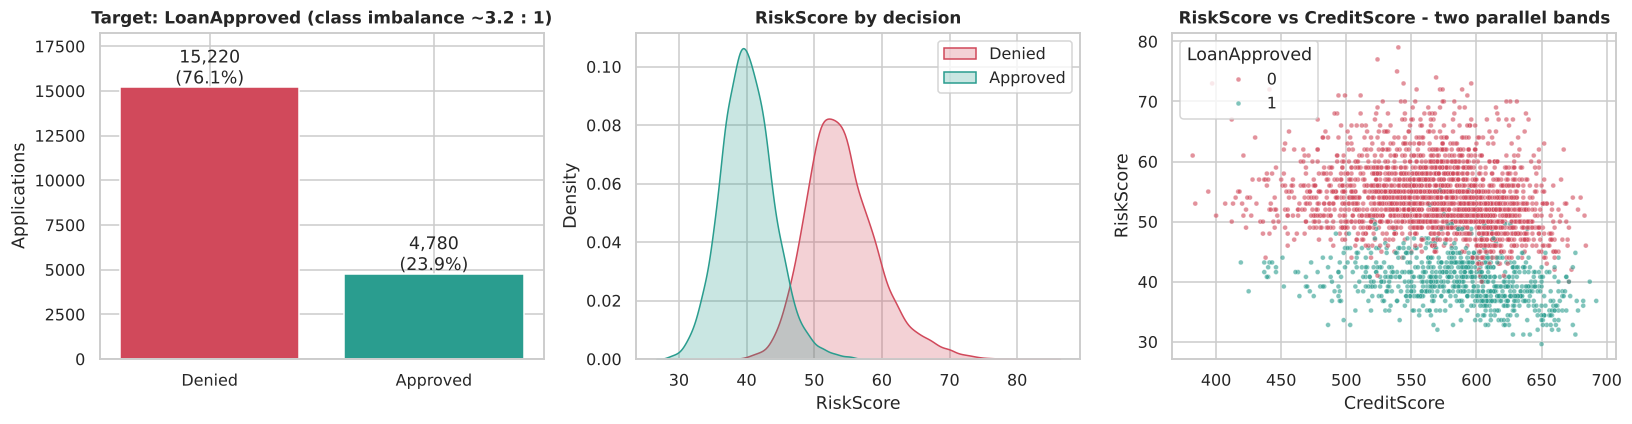

Approval rate: 23.9%
ROC-AUC of RiskScore alone for predicting the decision: 0.987


In [9]:
TARGET = 'LoanApproved'
vc = df[TARGET].value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bars = axes[0].bar([LABELS[i] for i in vc.index], vc.values, color=[PALETTE[i] for i in vc.index])
for b, v in zip(bars, vc.values):
    axes[0].text(b.get_x() + b.get_width()/2, v + 200, f'{v:,}\n({v/len(df):.1%})', ha='center')
axes[0].set(title='Target: LoanApproved (class imbalance ~3.2 : 1)', ylabel='Applications', ylim=(0, vc.max()*1.2))

for k in [0, 1]:
    sns.kdeplot(df.loc[df[TARGET] == k, 'RiskScore'], ax=axes[1], fill=True, color=PALETTE[k], label=LABELS[k])
axes[1].set(title='RiskScore by decision', xlabel='RiskScore'); axes[1].legend()

sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x='CreditScore', y='RiskScore', hue=TARGET,
                palette=PALETTE, s=10, alpha=.6, ax=axes[2])
axes[2].set_title('RiskScore vs CreditScore - two parallel bands')
plt.tight_layout(); plt.show()

print(f"Approval rate: {df[TARGET].mean():.1%}")
print(f"ROC-AUC of RiskScore alone for predicting the decision: {roc_auc_score(df[TARGET], -df['RiskScore']):.3f}")

**Findings**
* **Class imbalance:** only 23.9% of applications are approved (≈3.2 negatives per positive). Accuracy would be misleading; we stratify every split and fold and use PR-AUC and the cost metric.
* **`RiskScore` is leaky.** It separates the classes almost perfectly on its own, and the scatter plot shows two parallel bands – approved loans sit systematically lower *at the same credit score*. This is exactly what the source data-generation logic does (risk score × 0.8 when approved): the score is computed *using the decision*. In production, the risk score would not exist before the decision is made, so **`RiskScore` is excluded from all classification features**.

In [10]:
# ------------------------------------------------------------
# Baseline costs of naive policies (full data, per application)
# ------------------------------------------------------------
n, n_pos, n_neg = len(df), df[TARGET].sum(), (1 - df[TARGET]).sum()
baselines = pd.DataFrame({
    'policy': ['Deny everyone', 'Approve everyone', 'Approve at random (23.9%)'],
    'false approvals (FP)': [0, n_neg, n_neg * n_pos / n],
    'false denials (FN)':   [n_pos, 0, n_pos * (1 - n_pos / n)],
})
baselines['total cost ($)'] = baselines['false approvals (FP)'] * COST_FP + baselines['false denials (FN)'] * COST_FN
baselines['cost / application ($)'] = baselines['total cost ($)'] / n
display(baselines.style.format({'total cost ($)': '${:,.0f}', 'cost / application ($)': '${:,.0f}',
                                'false approvals (FP)': '{:,.0f}', 'false denials (FN)': '{:,.0f}'}))
BEST_NAIVE_COST = baselines['cost / application ($)'].min()
print(f'Best naive policy = deny everyone -> ${BEST_NAIVE_COST:,.0f} per application. '
      f'Target: <= ${BEST_NAIVE_COST*0.5:,.0f} (50% reduction).')

,policy,false approvals (FP),false denials (FN),total cost ($),cost / application ($)
0,Deny everyone,0,"4,780","$38,240,000","$1,912"
1,Approve everyone,"15,220",0,"$761,000,000","$38,050"
2,Approve at random (23.9%),"3,638","3,638","$210,979,640","$10,549"


Best naive policy = deny everyone -> $1,912 per application. Target: <= $956 (50% reduction).


Even "deny everyone" costs ~\$1,912 per application in foregone profit, while "approve everyone" would cost ~\$38,000 per application. These anchor our success criterion: **the model must cut cost to ≤ ~\$956 per application**.

### 2.4 Feature categorisation

In [11]:
NUMERIC_CONT = ['Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount', 'MonthlyDebtPayments',
                'CreditCardUtilizationRate', 'DebtToIncomeRatio', 'SavingsAccountBalance', 'CheckingAccountBalance',
                'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'NetWorth',
                'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio']
NUMERIC_DISC = ['LoanDuration', 'NumberOfDependents', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries',
                'PaymentHistory', 'LengthOfCreditHistory', 'JobTenure']
BINARY       = ['BankruptcyHistory', 'PreviousLoanDefaults']
ORDINAL      = ['EducationLevel']
NOMINAL      = ['EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose']
EDU_ORDER    = ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']
EXCLUDED     = ['RiskScore']   # target leakage

feature_types = pd.DataFrame(
    [(c, 'Numeric - continuous') for c in NUMERIC_CONT] + [(c, 'Numeric - discrete/count') for c in NUMERIC_DISC] +
    [(c, 'Binary') for c in BINARY] + [(c, 'Categorical - ordinal') for c in ORDINAL] +
    [(c, 'Categorical - nominal') for c in NOMINAL] + [(c, 'EXCLUDED (leakage)') for c in EXCLUDED],
    columns=['feature', 'type'])
feature_types['skew'] = feature_types['feature'].map(lambda c: df[c].skew() if pd.api.types.is_numeric_dtype(df[c]) else np.nan)
feature_types['missing %'] = feature_types['feature'].map(lambda c: df[c].isna().mean() * 100)
assert set(feature_types.feature) | {TARGET} == set(df.columns)
feature_types.groupby('type')['feature'].apply(list).to_frame()

,feature
type,
Binary,"[BankruptcyHistory, PreviousLoanDefaults]"
Categorical - nominal,"[EmploymentStatus, MaritalStatus, HomeOwnershi..."
Categorical - ordinal,[EducationLevel]
EXCLUDED (leakage),[RiskScore]
Numeric - continuous,"[Age, AnnualIncome, CreditScore, Experience, L..."
Numeric - discrete/count,"[LoanDuration, NumberOfDependents, NumberOfOpe..."


| Group | Features | Special preprocessing needed |
|---|---|---|
| Continuous money / ratio features | Income, balances, assets, liabilities, payments, DTI ratios | **Right-skewed** (skew > 1) → `log1p` + scaling for linear/KNN models |
| Bounded continuous | CreditScore, utilisation, interest rates, utility payment history | Scaling only |
| Age | Age | **Non-linear** (rise-then-plateau) relationship with approval (§2.6) → binned *and* scaled via `FeatureUnion` |
| Counts | Duration, dependents, credit lines, inquiries, payment history, tenure | Scaling |
| Binary | Bankruptcy, previous defaults | Pass-through (already 0/1) |
| Ordinal | EducationLevel (HS < Assoc < Bach < Master < PhD) | `OrdinalEncoder` with explicit order + mode imputation |
| Nominal | Employment, marital, home ownership, purpose | Constant "Missing" category + `OneHotEncoder` |

### 2.5 Univariate analysis – distributions of every feature

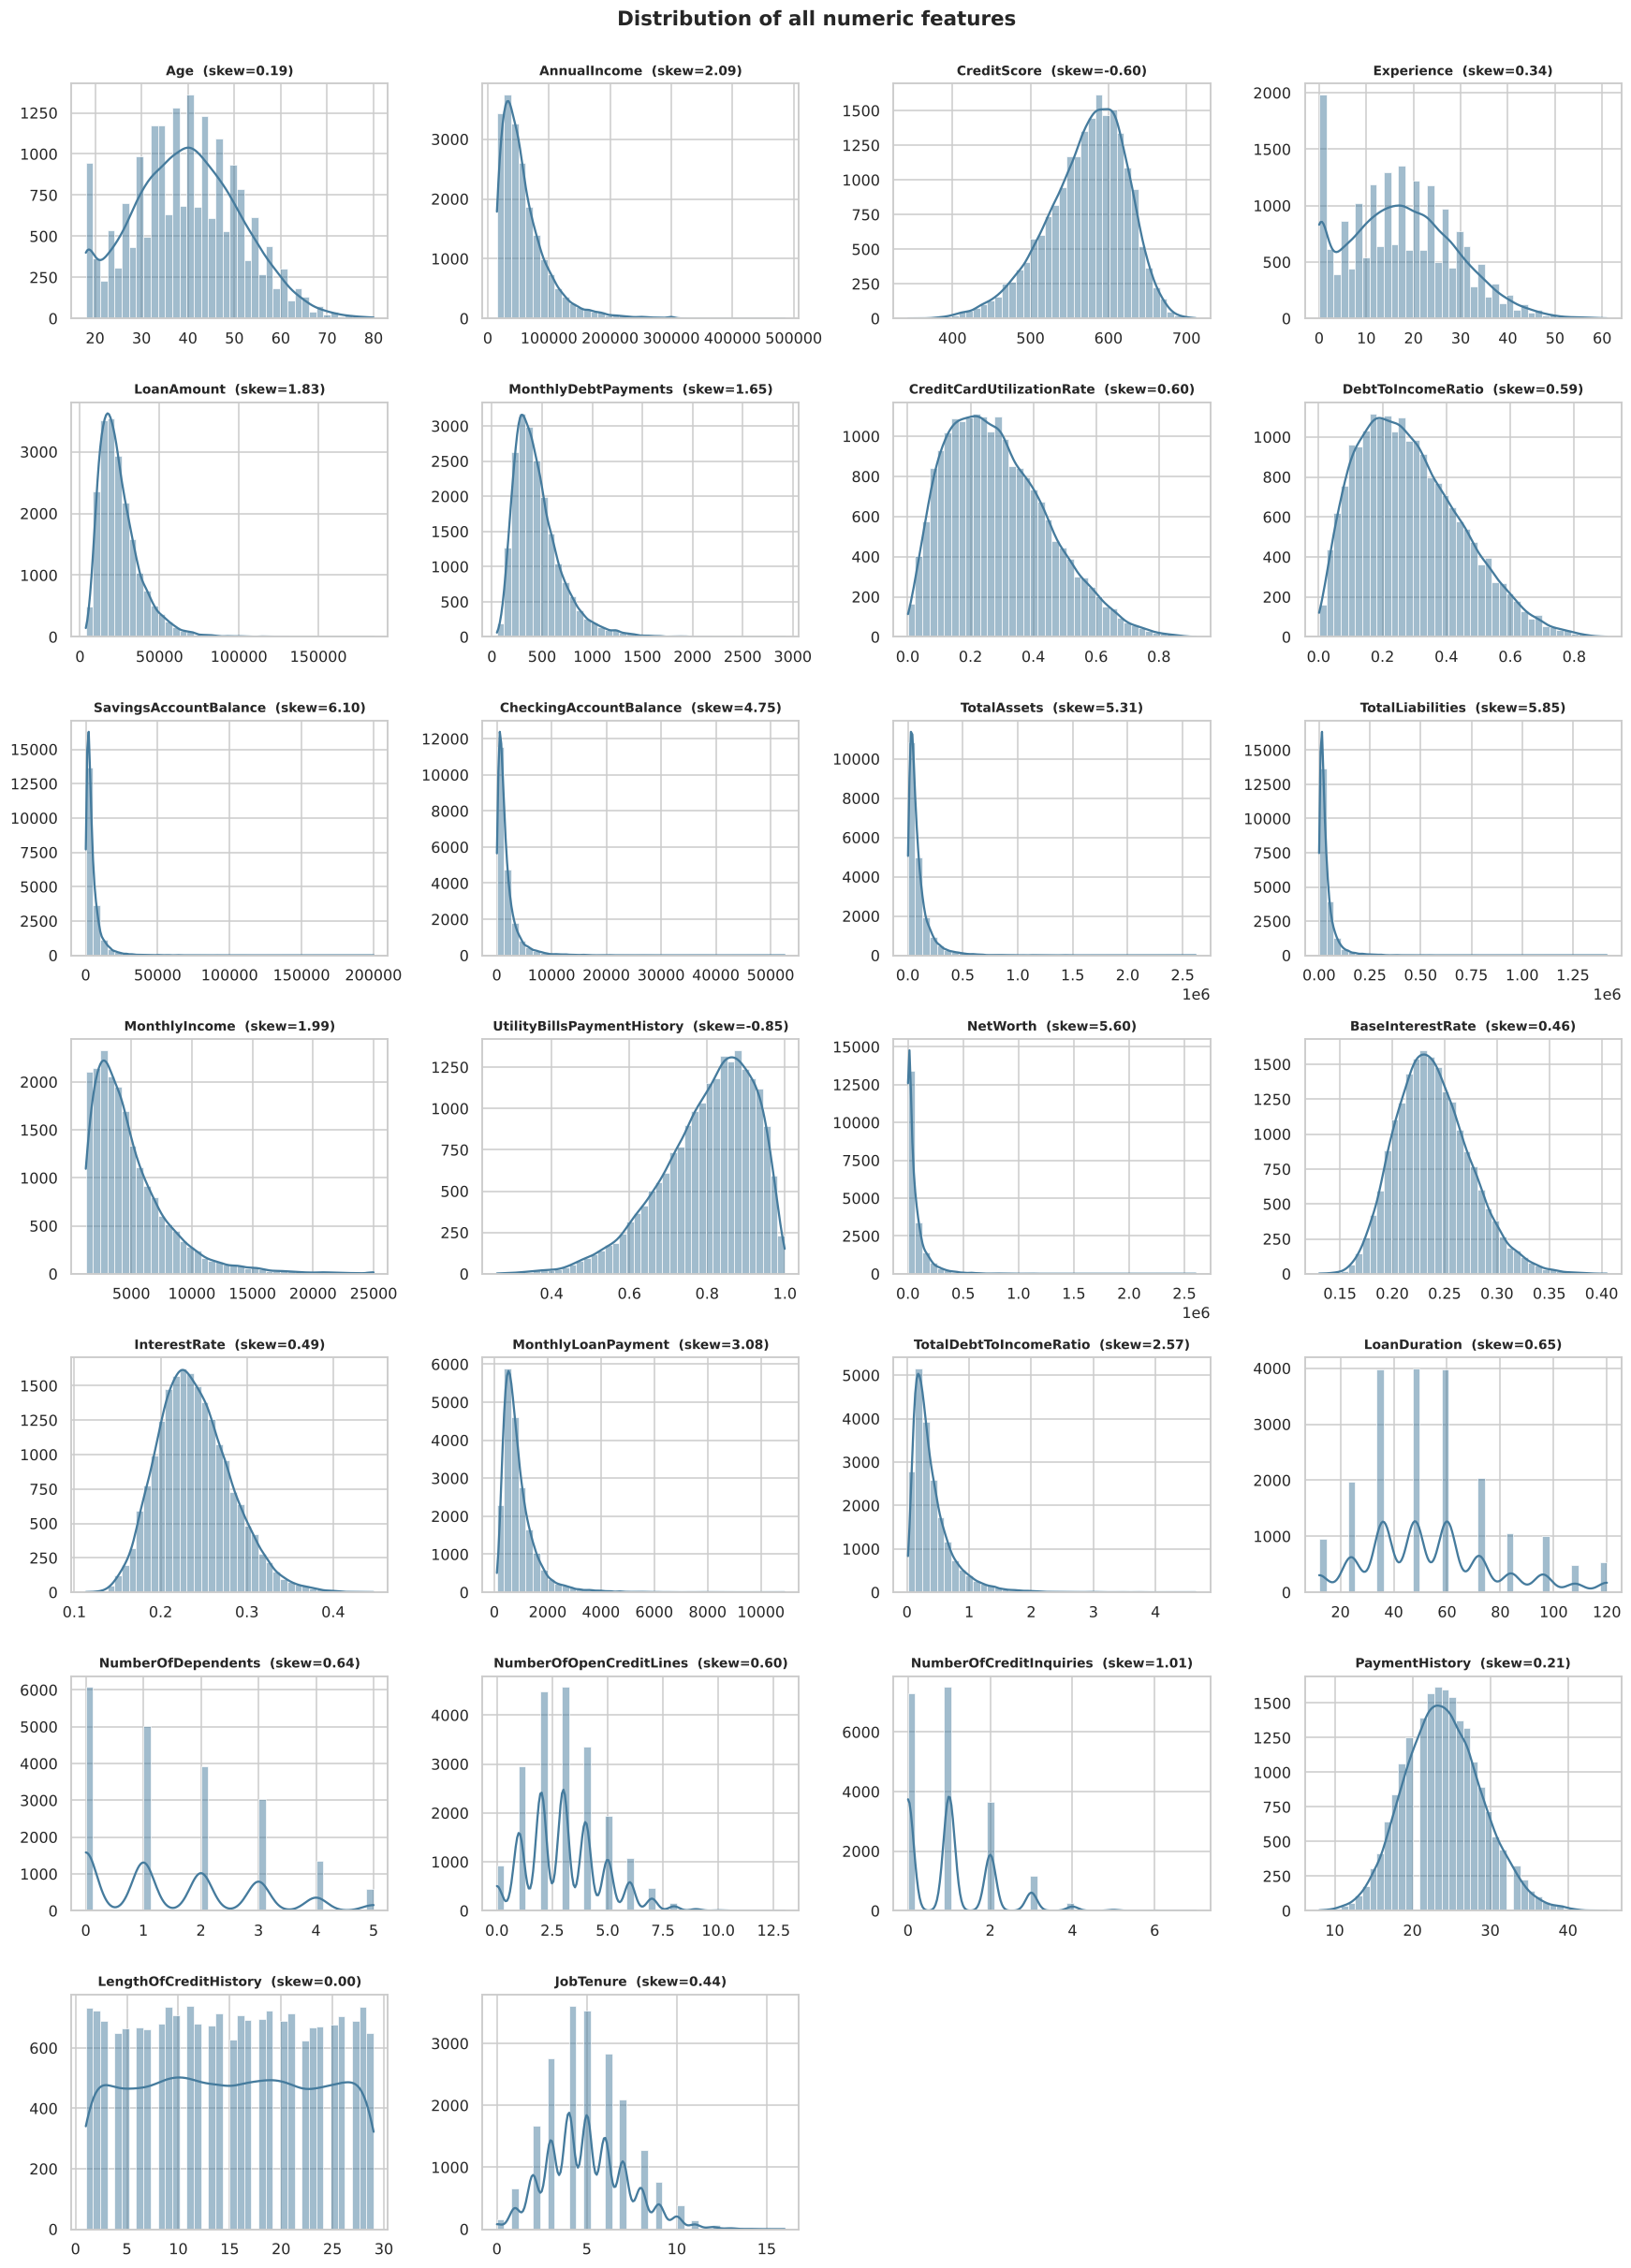

In [12]:
num_features = NUMERIC_CONT + NUMERIC_DISC
fig, axes = plt.subplots(7, 4, figsize=(16, 22))
for ax, c in zip(axes.flat, num_features):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, color='#457b9d', kde=True)
    ax.set_title(f'{c}  (skew={df[c].skew():.2f})', fontsize=9); ax.set_xlabel(''); ax.set_ylabel('')
for ax in axes.flat[len(num_features):]:
    ax.axis('off')
plt.suptitle('Distribution of all numeric features', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

In [13]:
skew_tbl = df[num_features].skew().sort_values(ascending=False).to_frame('skew')
skew_tbl['log1p skew'] = np.log1p(df[skew_tbl.index].clip(lower=0)).skew()
SKEWED = skew_tbl.index[skew_tbl['skew'] > 1].tolist()
print('Highly skewed (skew > 1):', SKEWED)
skew_tbl.head(12)

Highly skewed (skew > 1): ['SavingsAccountBalance', 'TotalLiabilities', 'NetWorth', 'TotalAssets', 'CheckingAccountBalance', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'AnnualIncome', 'MonthlyIncome', 'LoanAmount', 'MonthlyDebtPayments', 'NumberOfCreditInquiries']


,skew,log1p skew
SavingsAccountBalance,6.0961,-0.0083
TotalLiabilities,5.8489,-0.0138
NetWorth,5.5998,-0.0932
TotalAssets,5.3113,0.0442
CheckingAccountBalance,4.7461,-0.0370
MonthlyLoanPayment,3.0818,0.2514
TotalDebtToIncomeRatio,2.5745,1.4119
AnnualIncome,2.0889,0.1587
MonthlyIncome,1.9929,0.1489
LoanAmount,1.8337,0.0164


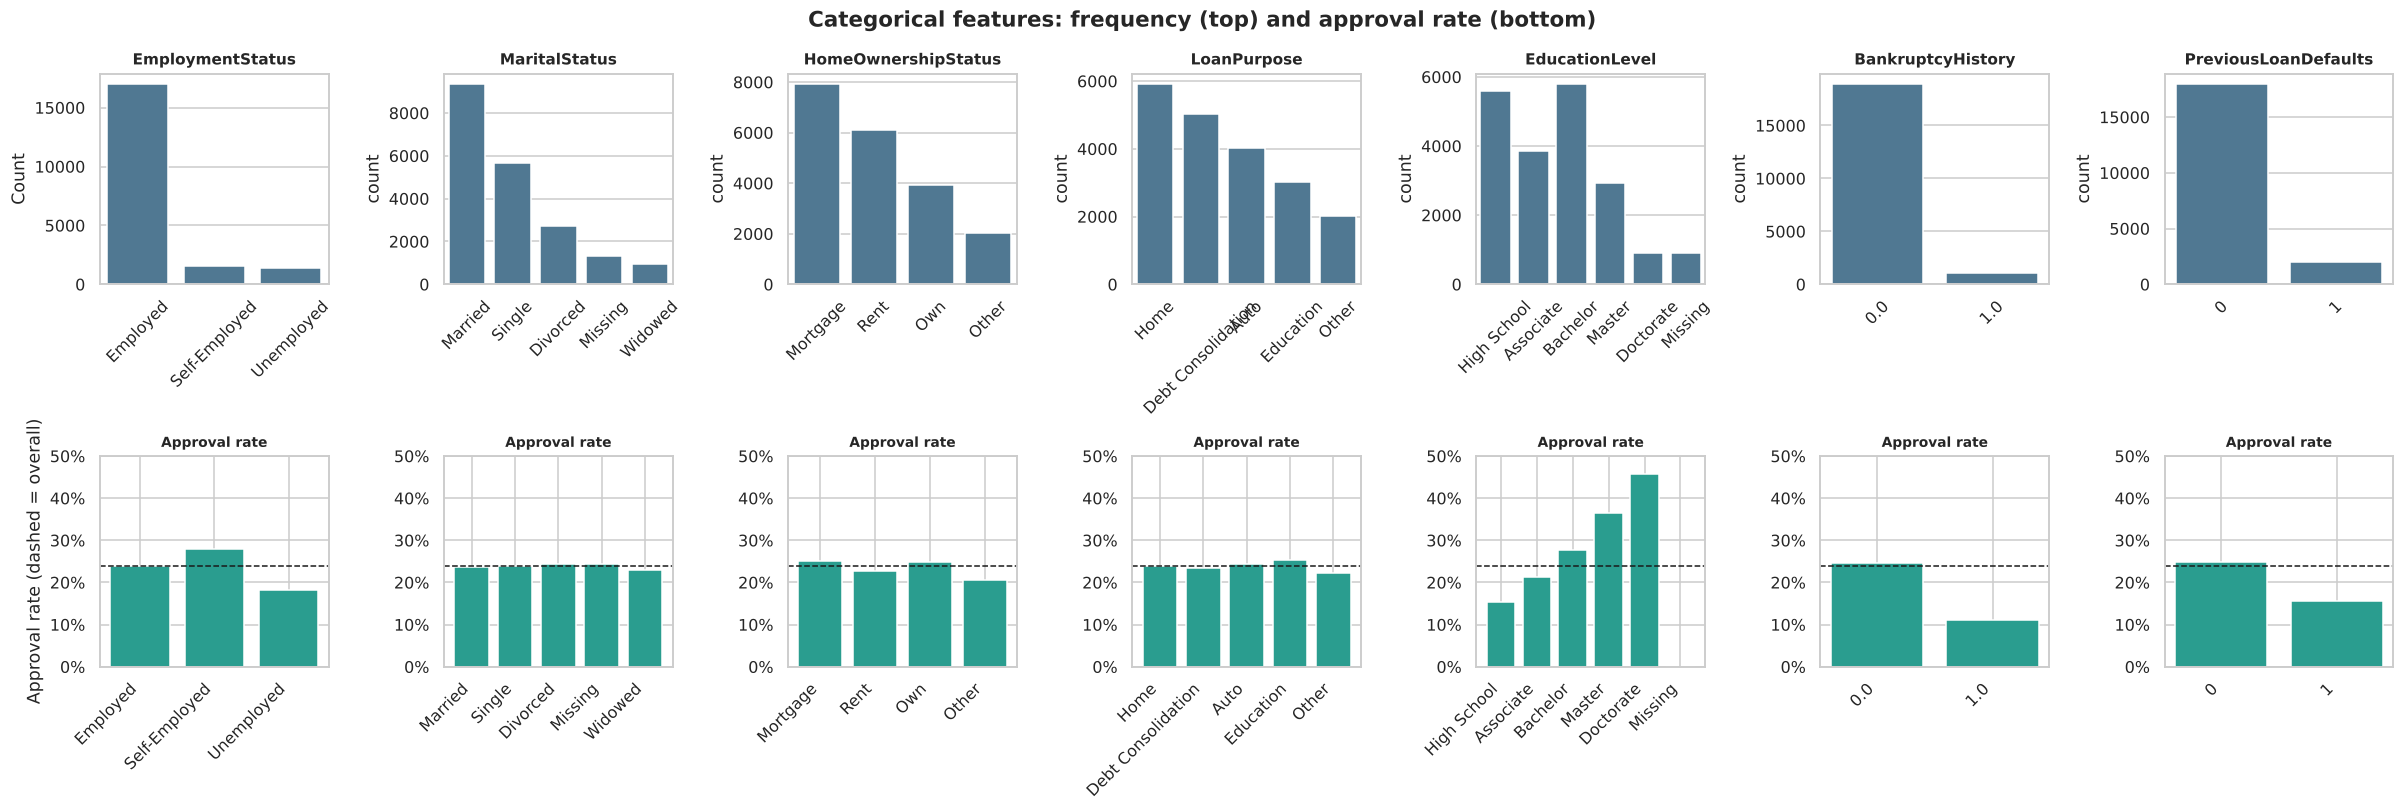

In [14]:
cat_features = NOMINAL + ORDINAL + BINARY
fig, axes = plt.subplots(2, len(cat_features), figsize=(22, 7.5))
for i, c in enumerate(cat_features):
    s = df[c].fillna('Missing').astype(str)
    order = EDU_ORDER + ['Missing'] if c == 'EducationLevel' else s.value_counts().index.tolist()
    order = [o for o in order if o in s.unique()]
    sns.countplot(x=s, order=order, ax=axes[0, i], color='#457b9d')
    axes[0, i].set_title(c, fontsize=10); axes[0, i].set_xlabel(''); axes[0, i].tick_params(axis='x', rotation=45)
    rate = df.assign(_c=s).groupby('_c')[TARGET].mean().reindex(order)
    axes[1, i].bar(range(len(rate)), rate.values, color=PALETTE[1])
    axes[1, i].axhline(df[TARGET].mean(), ls='--', color='k', lw=1)
    axes[1, i].set_xticks(range(len(rate))); axes[1, i].set_xticklabels(order, rotation=45, ha='right')
    axes[1, i].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1, i].set_ylim(0, .5)
    axes[1, i].set_title('Approval rate', fontsize=9)
axes[0, 0].set_ylabel('Count'); axes[1, 0].set_ylabel('Approval rate (dashed = overall)')
plt.suptitle('Categorical features: frequency (top) and approval rate (bottom)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**Univariate observations**
* **Money columns are strongly right-skewed** (TotalAssets, NetWorth, Liabilities, savings/checking, income, loan size; skew 2–8). `log1p` brings most close to symmetric → we log-transform them for linear and distance-based models.
* `CreditScore` is left-skewed and bounded (343–712), `Age` is roughly normal (18–80), counts follow Poisson-like shapes.
* **Categoricals:** most applicants are Employed (85%), Married (47%), Mortgage holders (40%), borrowing for Home or Debt Consolidation.
* **Approval rate varies strongly with education** (rising monotonically from High School to Doctorate – supports ordinal encoding) and **employment** (Unemployed much lower), and with **bankruptcy / previous defaults**. Marital status and loan purpose show only small differences.

### 2.6 Bivariate analysis – how features relate to the decision

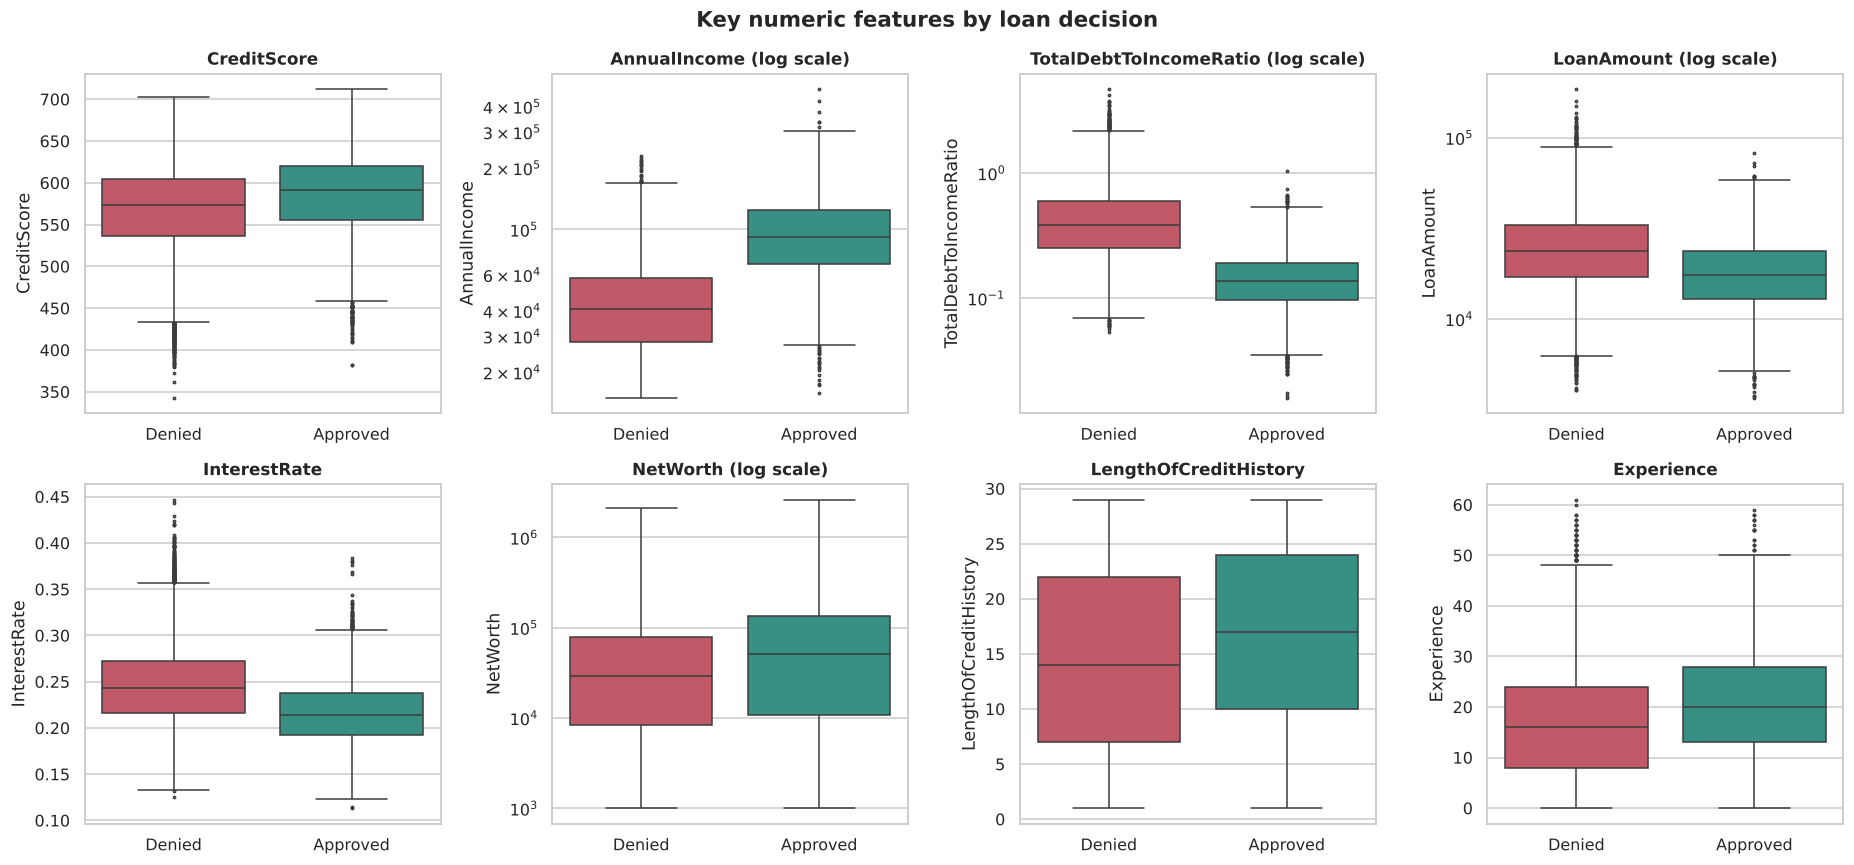

In [15]:
key_num = ['CreditScore', 'AnnualIncome', 'TotalDebtToIncomeRatio', 'LoanAmount', 'InterestRate',
           'NetWorth', 'LengthOfCreditHistory', 'Experience']
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, c in zip(axes.flat, key_num):
    data = df[[c, TARGET]].copy()
    log_scale = c in SKEWED
    sns.boxplot(data=data, x=TARGET, y=c, hue=TARGET, palette=PALETTE, ax=ax, legend=False,
                log_scale=log_scale, fliersize=1.5)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Denied', 'Approved'])
    ax.set_title(f'{c}' + (' (log scale)' if log_scale else '')); ax.set_xlabel('')
plt.suptitle('Key numeric features by loan decision', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

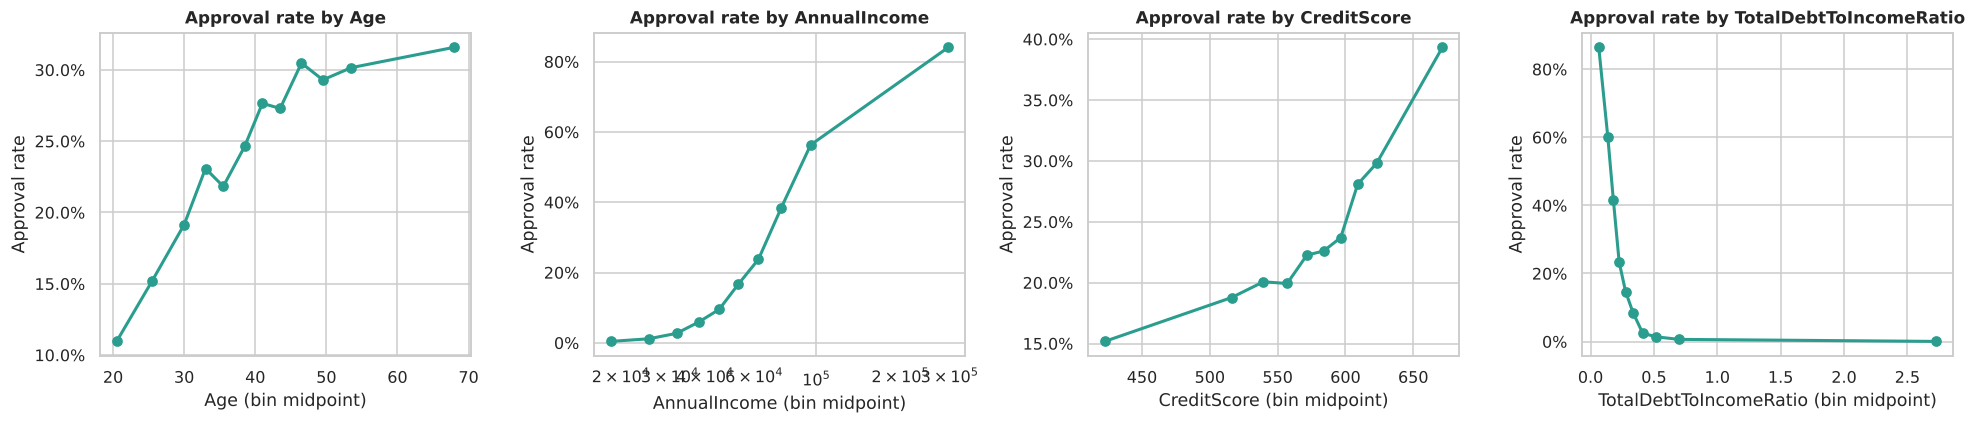

In [16]:
# Non-linear relationships: approval rate across quantile bins (motivates binning / tree models)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (c, q) in zip(axes, [('Age', 12), ('AnnualIncome', 10), ('CreditScore', 10), ('TotalDebtToIncomeRatio', 10)]):
    b = pd.qcut(df[c], q, duplicates='drop')
    rate = df.groupby(b, observed=True)[TARGET].agg(['mean', 'size'])
    mids = [iv.mid for iv in rate.index]
    ax.plot(mids, rate['mean'], marker='o', color=PALETTE[1], lw=2)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set(title=f'Approval rate by {c}', xlabel=c + ' (bin midpoint)', ylabel='Approval rate')
    if c == 'AnnualIncome': ax.set_xscale('log')
plt.tight_layout(); plt.show()

**Bivariate observations**
* **Credit score, income, net worth, credit history length and experience are higher for approved applicants; total DTI, interest rate and loan amount are lower.** The separations are large – this is a highly learnable problem.
* **Income is the dominant driver**: approval rises from 0.4% in the bottom income decile to 84% in the top decile – a strongly non-linear (convex) curve on the raw scale, much more linear on the log scale.
* **Age has a non-linear relationship**: approval climbs steeply from 11% (age ≤ 23) to ~30% by the mid-40s and then **plateaus**. A single linear coefficient cannot capture a curve that rises and then flattens → we add **quantile bins of Age via `FeatureUnion`** so the logistic model can learn the shape; tree models capture it natively. (Tuning in §4.4 confirms the bins help.)
* `TotalDebtToIncomeRatio` falls steeply: of applicants above 0.6, only 0.2% were approved – effectively a hard ceiling.

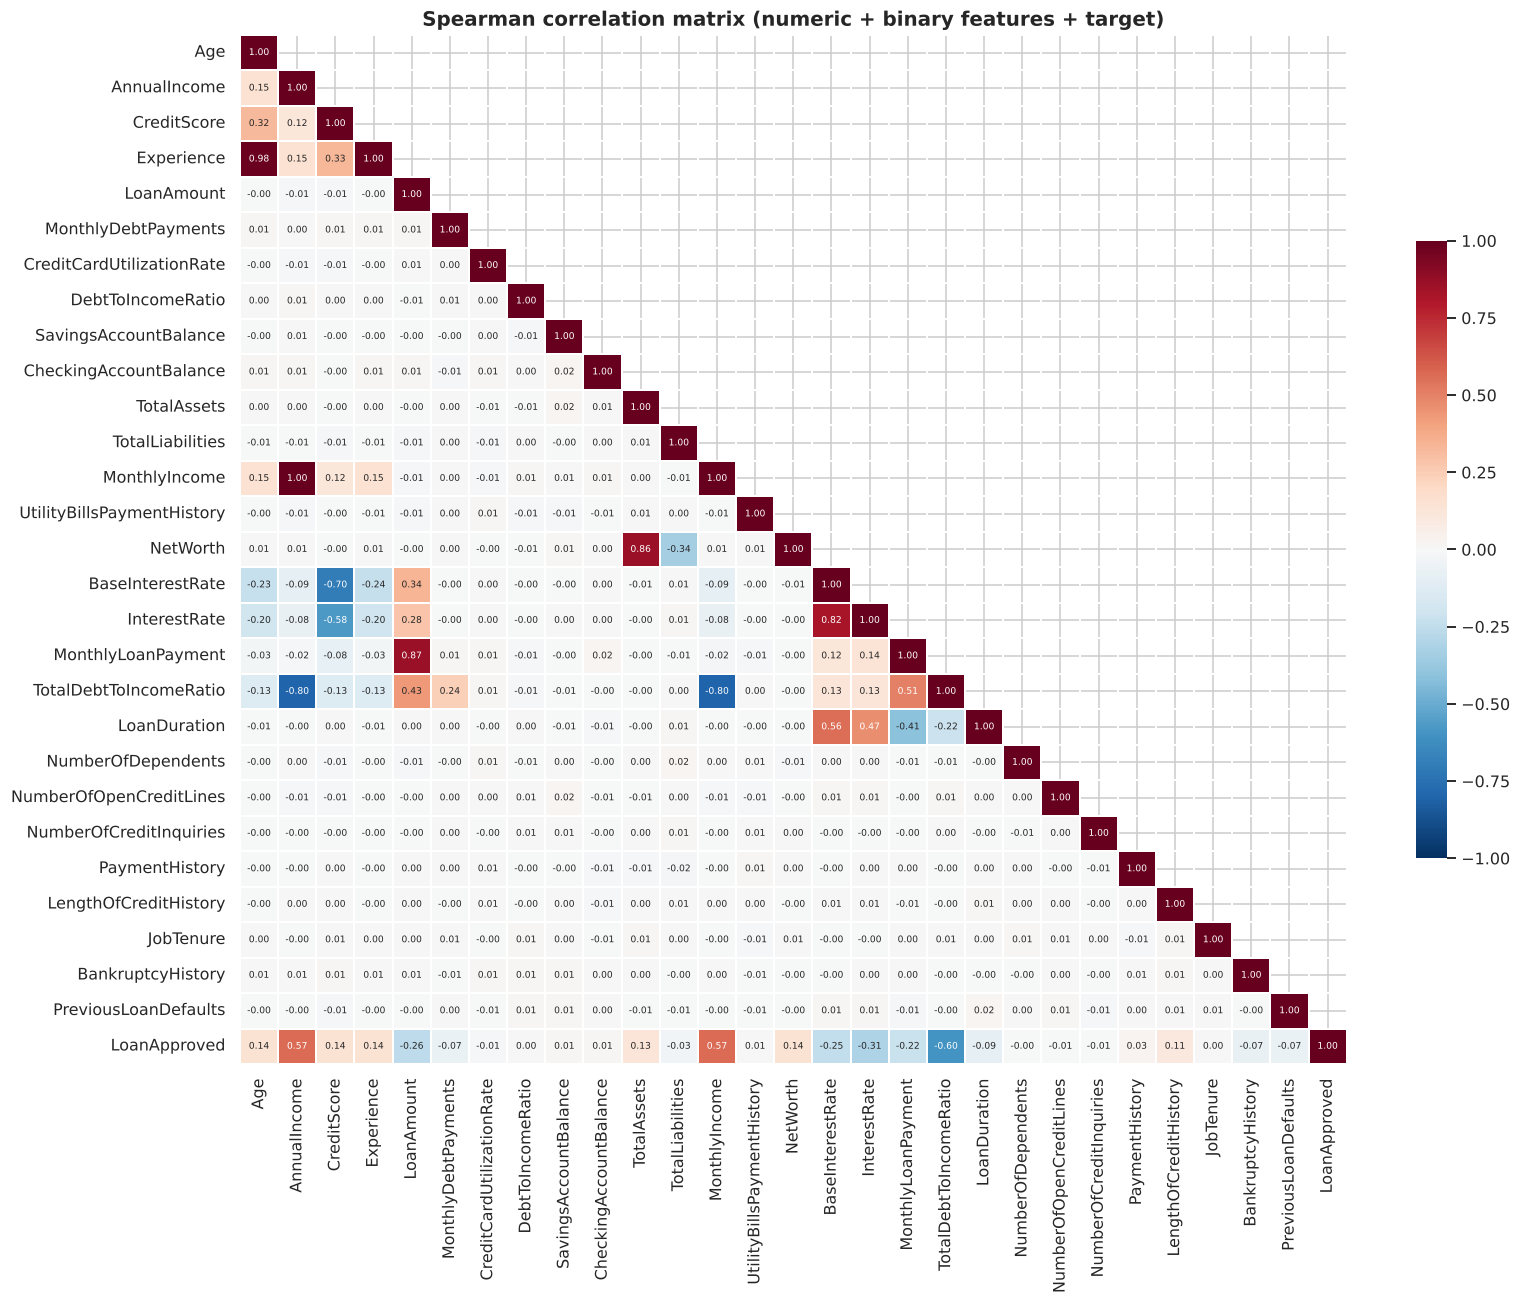

In [17]:
# Correlation matrix (Spearman: robust to skew & outliers) including the target
corr = df[num_features + BINARY + [TARGET]].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 6}, linewidths=.3, cbar_kws={'shrink': .6})
plt.title('Spearman correlation matrix (numeric + binary features + target)', fontsize=13)
plt.tight_layout(); plt.show()

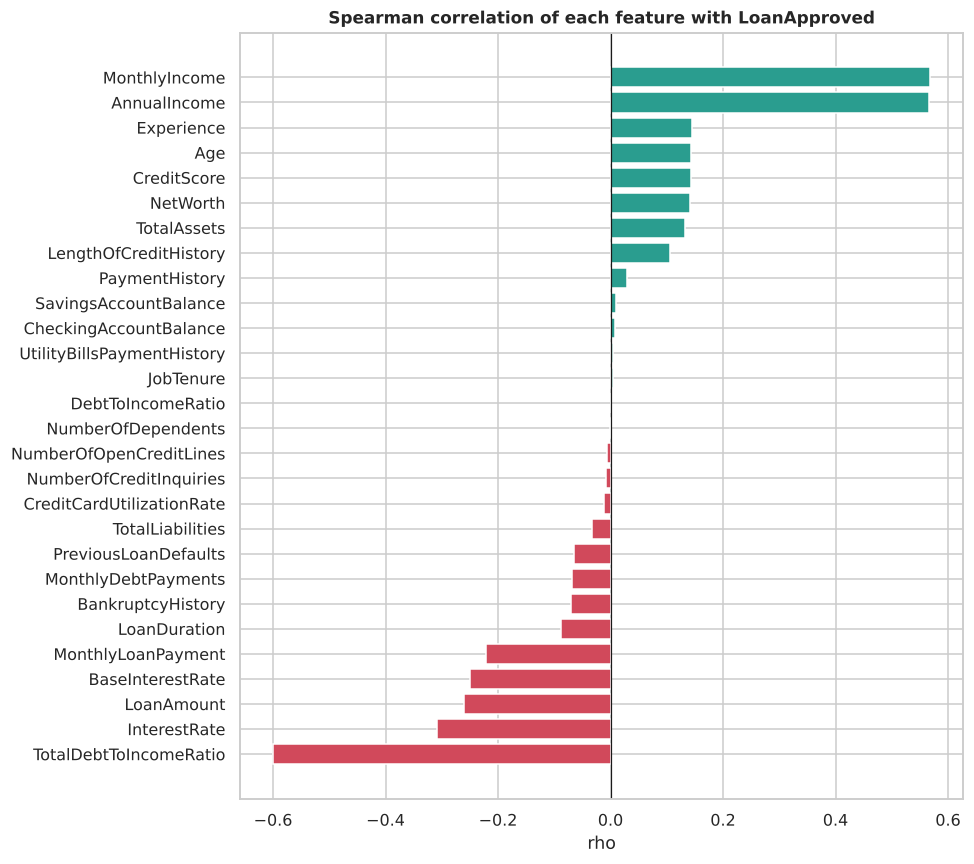

Most strongly correlated feature pairs (|rho| > 0.7):


,level_0,level_1,rho
40,AnnualIncome,MonthlyIncome,0.9962
3,Age,Experience,0.9847
129,LoanAmount,MonthlyLoanPayment,0.8667
294,TotalAssets,NetWorth,0.8602
436,BaseInterestRate,InterestRate,0.8206
354,MonthlyIncome,TotalDebtToIncomeRatio,-0.8031
46,AnnualIncome,TotalDebtToIncomeRatio,-0.8001
71,CreditScore,BaseInterestRate,-0.7026


In [18]:
# Correlation with target & strongly correlated feature pairs
tgt_corr = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(tgt_corr.index, tgt_corr.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in tgt_corr.values])
ax.axvline(0, color='k', lw=.8)
ax.set(title='Spearman correlation of each feature with LoanApproved', xlabel='rho')
plt.tight_layout(); plt.show()

pairs = (corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones(corr.shape[0]-1, dtype=bool), 1))
         .stack().rename('rho').reset_index())
pairs = pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index)
print('Most strongly correlated feature pairs (|rho| > 0.7):')
pairs[pairs.rho.abs() > 0.7]

In [19]:
# Multicollinearity: Variance Inflation Factor (VIF_j = 1 / (1 - R^2_j)) computed with sklearn
from sklearn.linear_model import LinearRegression
Xv = df[num_features + BINARY].copy()
Xv['SavingsAccountBalance'] = Xv['SavingsAccountBalance'].fillna(Xv['SavingsAccountBalance'].median())
Xv[SKEWED] = np.log1p(Xv[SKEWED])
vif = {}
for c in Xv.columns:
    others = Xv.drop(columns=c)
    r2 = LinearRegression().fit(others, Xv[c]).score(others, Xv[c])
    vif[c] = 1 / (1 - r2) if r2 < 1 else np.inf
vif = pd.Series(vif, name='VIF').sort_values(ascending=False)
vif.head(10).to_frame()

,VIF
MonthlyIncome,122.7992
AnnualIncome,117.8551
BaseInterestRate,66.5321
CreditScore,34.2956
Experience,29.7614
Age,29.6538
LoanDuration,24.6292
LoanAmount,18.4033
MonthlyLoanPayment,16.3618
TotalDebtToIncomeRatio,8.9617


**Multivariate / multicollinearity observations**
* Several features are **near-duplicates by construction**: `AnnualIncome`≈`MonthlyIncome`×12 (ρ≈1.0), `BaseInterestRate`≈`InterestRate`, `Age`≈`Experience`, `TotalAssets`↔`NetWorth`, `MonthlyLoanPayment`↔`LoanAmount`. `BaseInterestRate` is itself a formula of CreditScore, LoanAmount and LoanDuration.
* VIF confirms severe multicollinearity (VIF ≫ 10 for the income pair, interest rates, age/experience). **Implications:** logistic-regression *coefficients* become unstable and hard to interpret → we use **regularisation** (tuned `C` and L1/L2 mix), test **univariate feature selection** (`SelectKBest`) inside the pipeline, and rely on **permutation importance** (which is robust to the model type) for interpretation. Tree ensembles are unaffected for prediction.

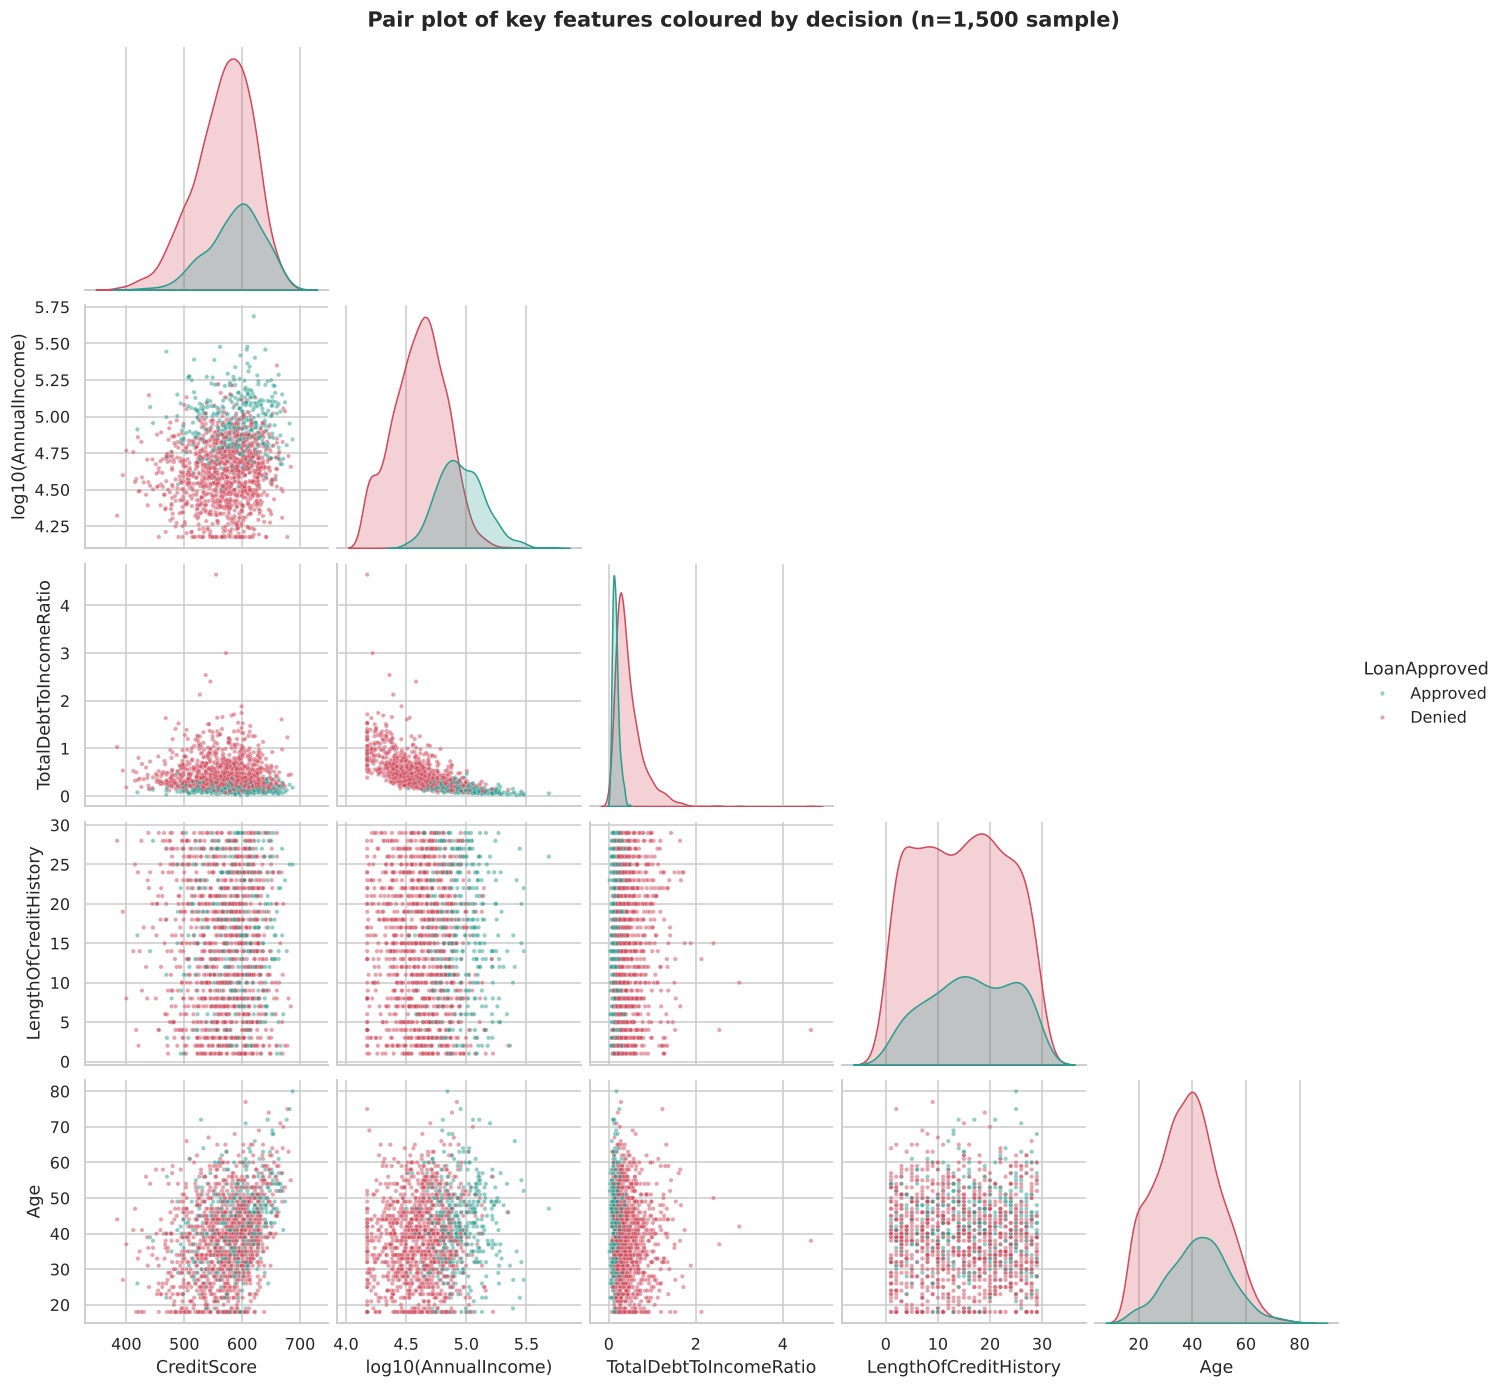

In [20]:
# Pair plot of the most informative, weakly-overlapping features (sample for readability)
pp_cols = ['CreditScore', 'AnnualIncome', 'TotalDebtToIncomeRatio', 'LengthOfCreditHistory', 'Age']
pp = df[pp_cols + [TARGET]].sample(1500, random_state=RANDOM_STATE).copy()
pp['AnnualIncome'] = np.log10(pp['AnnualIncome']); pp = pp.rename(columns={'AnnualIncome': 'log10(AnnualIncome)'})
pp[TARGET] = pp[TARGET].map(LABELS)
g = sns.pairplot(pp, hue=TARGET, palette={'Denied': PALETTE[0], 'Approved': PALETTE[1]},
                 plot_kws={'s': 8, 'alpha': .5}, diag_kind='kde', corner=True)
g.figure.suptitle('Pair plot of key features coloured by decision (n=1,500 sample)', y=1.01, fontweight='bold')
plt.show()

The pair plot shows that **income and credit score jointly** separate approvals well (approvals concentrate in the high-income/high-score corner), while total DTI adds a clear "ceiling". The class boundary looks smooth and largely additive in log-income – a good sign for a well-specified logistic model.

### 2.7 Statistical tests

* **Numeric features:** distributions are non-normal (see skew; Shapiro–Wilk below), so we use the non-parametric **Mann–Whitney U test** and report the **rank-biserial correlation** as effect size.
* **Categorical features:** **Chi-square test of independence** with **Cramér's V** as effect size.
* With n = 20,000 almost everything is "significant", so we focus on **effect sizes**.

In [21]:
# Normality check (Shapiro-Wilk on a 5,000-row sample -> the test's maximum reliable size)
sw = {c: stats.shapiro(df[c].dropna().sample(5000, random_state=RANDOM_STATE)).pvalue for c in key_num}
print('Shapiro-Wilk p-values (all << 0.05 -> non-normal):', {k: f'{v:.1e}' for k, v in sw.items()})

rows = []
for c in num_features + BINARY:
    a = df.loc[df[TARGET] == 1, c].dropna(); b = df.loc[df[TARGET] == 0, c].dropna()
    u, pval = stats.mannwhitneyu(a, b, alternative='two-sided')
    rbc = 2 * u / (len(a) * len(b)) - 1                         # rank-biserial correlation
    rows.append({'feature': c, 'test': 'Mann-Whitney U', 'p_value': pval, 'effect': rbc,
                 'median approved': a.median(), 'median denied': b.median()})
num_tests = pd.DataFrame(rows).sort_values('effect', key=abs, ascending=False)

rows = []
for c in NOMINAL + ORDINAL:
    ct = pd.crosstab(df[c].fillna('Missing'), df[TARGET])
    chi2, pval, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({'feature': c, 'test': 'Chi-square', 'chi2': chi2, 'dof': dof, 'p_value': pval, "Cramer's V": v})
cat_tests = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)

display(num_tests.style.format({'p_value': '{:.1e}', 'effect': '{:+.3f}',
                                          'median approved': '{:,.2f}', 'median denied': '{:,.2f}'})
        .bar(subset=['effect'], align='zero', color=[PALETTE[0], PALETTE[1]]))
display(cat_tests.style.format({'chi2': '{:,.1f}', 'p_value': '{:.1e}', "Cramer's V": '{:.3f}'}))

Shapiro-Wilk p-values (all << 0.05 -> non-normal): {'CreditScore': '1.6e-26', 'AnnualIncome': '9.0e-61', 'TotalDebtToIncomeRatio': '6.1e-63', 'LoanAmount': '1.6e-51', 'InterestRate': '8.8e-22', 'NetWorth': '4.9e-80', 'LengthOfCreditHistory': '1.9e-37', 'Experience': '2.5e-29'}


,feature,test,p_value,effect,median approved,median denied
18,TotalDebtToIncomeRatio,Mann-Whitney U,0.0e+00,-0.813,0.14,0.38
12,MonthlyIncome,Mann-Whitney U,0.0e+00,+0.770,"7,572.29","3,365.67"
1,AnnualIncome,Mann-Whitney U,0.0e+00,+0.767,"91,269.50","40,557.50"
16,InterestRate,Mann-Whitney U,0.0e+00,-0.417,0.21,0.24
4,LoanAmount,Mann-Whitney U,2.7e-296,-0.352,"17,336.50","23,566.00"
15,BaseInterestRate,Mann-Whitney U,7.3e-272,-0.337,0.22,0.24
17,MonthlyLoanPayment,Mann-Whitney U,1.1e-216,-0.301,576.03,791.22
3,Experience,Mann-Whitney U,5.9e-93,+0.196,20.00,16.00
0,Age,Mann-Whitney U,1.9e-91,+0.194,42.00,39.00
2,CreditScore,Mann-Whitney U,1.0e-90,+0.193,591.00,574.00


,feature,test,chi2,dof,p_value,Cramer's V
4,EducationLevel,Chi-square,"1,068.9",5,7.2e-229,0.231
0,EmploymentStatus,Chi-square,38.5,2,4.3e-09,0.044
2,HomeOwnershipStatus,Chi-square,26.3,3,8.1e-06,0.036
3,LoanPurpose,Chi-square,6.7,4,1.5e-01,0.018
1,MaritalStatus,Chi-square,1.4,4,8.5e-01,0.008


**Statistical test conclusions**
* The largest effects are for **total debt-to-income** (r ≈ −0.81) and **income** (monthly/annual, r ≈ +0.77), followed by **interest rate** (−0.42), **loan amount** (−0.35) and **monthly loan payment** (−0.30). Experience, age, credit score, net worth and total assets have moderate effects (r ≈ 0.18–0.20) – confirming the visual EDA.
* Many features show **negligible, non-significant effects** (|r| < 0.02, p > 0.1): `NumberOfDependents`, `NumberOfOpenCreditLines`, `CreditCardUtilizationRate`, `UtilityBillsPaymentHistory`, `JobTenure`, `NumberOfCreditInquiries`, savings/checking balances – and, notably, the *simple* `DebtToIncomeRatio` (r ≈ 0.00), even though the *total* DTI is the strongest feature. These are candidates for removal by feature selection (`SelectKBest`, tuned in §4.4).
* Among categoricals, **EducationLevel** has a clear association (Cramér's V = 0.23); employment and home ownership are weak but significant (V ≈ 0.04); **LoanPurpose** (V = 0.02, p = 0.15) and **MaritalStatus** (V = 0.008, p = 0.85) are **not associated** with the decision. That matters for fairness: marital status is a *protected characteristic* under fair-lending laws in many jurisdictions and contributes no predictive value (tested formally in §5.4).

### 2.8 Missing-value patterns
Is data **Missing Completely At Random (MCAR)**, or does missingness carry information about the outcome?

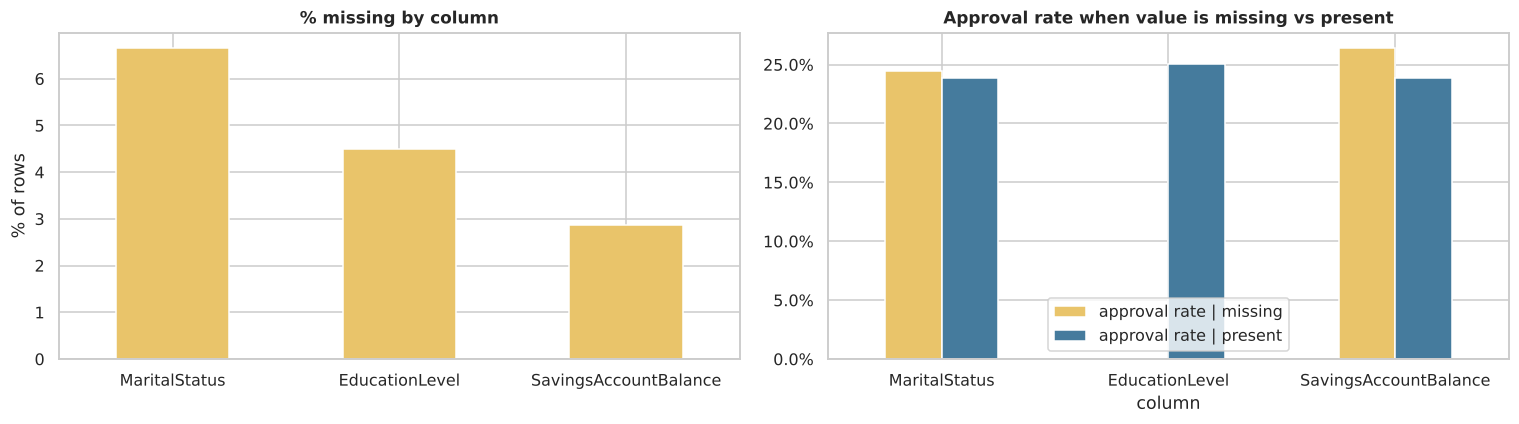

Rows with >1 missing value: 126
Correlation between missingness indicators:
                        MaritalStatus  EducationLevel  SavingsAccountBalance
MaritalStatus                 1.0000          0.0020                 0.0130
EducationLevel                0.0020          1.0000                -0.0040
SavingsAccountBalance         0.0130         -0.0040                 1.0000


,approval rate | missing,approval rate | present,chi2 p-value
column,,,
MaritalStatus,24.5%,23.9%,0.623
EducationLevel,0.0%,25.0%,0.000
SavingsAccountBalance,26.4%,23.8%,0.170


,AnnualIncome,CreditScore,Age,TotalAssets
Savings present,"48,543.5000",578.0000,40.0000,"60,452.5000"
Savings missing,"49,402.0000",582.0000,39.0000,"66,619.5000"


In [22]:
miss_cols = ['MaritalStatus', 'EducationLevel', 'SavingsAccountBalance']
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
miss = df[miss_cols].isna()
(miss.mean() * 100).plot.bar(ax=axes[0], color='#e9c46a')
axes[0].set(title='% missing by column', ylabel='% of rows'); axes[0].tick_params(axis='x', rotation=0)

rows = []
for c in miss_cols:
    m = df[c].isna()
    ct = pd.crosstab(m, df[TARGET]); chi2, pval, *_ = stats.chi2_contingency(ct)
    rows.append({'column': c, 'approval rate | missing': df.loc[m, TARGET].mean(),
                 'approval rate | present': df.loc[~m, TARGET].mean(), 'chi2 p-value': pval})
miss_tbl = pd.DataFrame(rows).set_index('column')
miss_tbl[['approval rate | missing', 'approval rate | present']].plot.bar(ax=axes[1], color=['#e9c46a', '#457b9d'])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].tick_params(axis='x', rotation=0)
axes[1].set_title('Approval rate when value is missing vs present')
plt.tight_layout(); plt.show()

# Do missing values co-occur, and are they related to other features?
print('Rows with >1 missing value:', (miss.sum(axis=1) > 1).sum())
print('Correlation between missingness indicators:\n', miss.astype(int).corr().round(3))
display(miss_tbl.style.format({'approval rate | missing': '{:.1%}', 'approval rate | present': '{:.1%}', 'chi2 p-value': '{:.3f}'}))

# Compare a few key features for rows with vs without missing savings (MAR check)
cmp = df.groupby(df['SavingsAccountBalance'].isna())[['AnnualIncome', 'CreditScore', 'Age', 'TotalAssets']].median()
cmp.index = ['Savings present', 'Savings missing']; cmp

**Missing-value interpretation**
* Missingness is low (2.9–6.7%) and **does not co-occur** across columns (indicator correlations ≈ 0).
* **`MaritalStatus` and `SavingsAccountBalance` look MCAR:** the approval rate is statistically indistinguishable between missing and non-missing rows (chi-square p = 0.62 and 0.17), and other features have similar medians whether savings is missing or not – most likely data-entry gaps.
* **`EducationLevel` is *not* missing at random – a critical finding.** *All 901 applications with a missing education level were denied* (0% vs 25% approval, p ≈ 0). Their income and other characteristics are otherwise typical of denied applicants, so the missingness is tied to the **outcome**, not to the applicant's profile. The most plausible explanation is a **process artefact** (e.g. education is only completed for applications that progress, or the field was cleared on rejection). A rule "missing education ⇒ deny" would look perfect on historical data but **would not hold at application time** – it is a form of **target leakage**.
* **Treatment:** we (a) impute **numeric** values with the median *and* add a **missing-indicator** column, (b) give **nominal** features an explicit `"Missing"` category, and (c) impute the **ordinal** education level with the mode **without** a missing flag, deliberately *not* letting the model exploit the leaky education-missingness pattern. A sensitivity analysis in §5.6 quantifies what the flag would add. All imputers are fit **inside the pipeline on training folds only**. In §3.3 we compare four imputation strategies empirically.

### 2.9 Outlier detection

,IQR outliers (raw),IQR outliers (after log1p),max / median,% rows (raw)
NetWorth,1564,0,79.2,7.8%
SavingsAccountBalance,1547,168,67.0,7.7%
TotalLiabilities,1533,131,63.8,7.7%
CheckingAccountBalance,1522,130,47.1,7.6%
TotalAssets,1442,96,43.2,7.2%
TotalDebtToIncomeRatio,1152,705,15.4,5.8%
MonthlyLoanPayment,1089,206,15.0,5.4%
AnnualIncome,947,61,10.0,4.7%
MonthlyIncome,925,55,6.2,4.6%
LoanAmount,746,126,8.4,3.7%


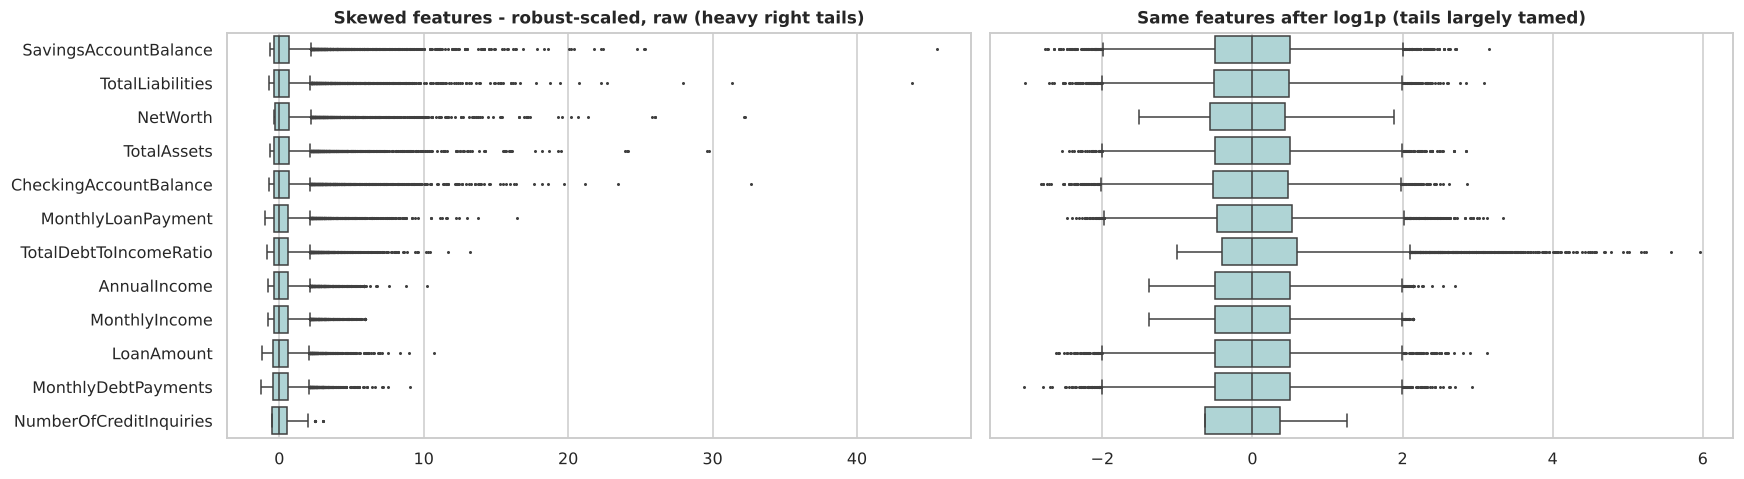

In [23]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    'IQR outliers (raw)': {c: iqr_outliers(df[c].dropna()) for c in num_features},
    'IQR outliers (after log1p)': {c: iqr_outliers(np.log1p(df[c].dropna())) for c in num_features},
    'max / median': {c: df[c].max() / max(df[c].median(), 1e-9) for c in num_features},
})
out['% rows (raw)'] = out['IQR outliers (raw)'] / len(df) * 100
out = out.sort_values('IQR outliers (raw)', ascending=False)
display(out.head(12).style.format({'% rows (raw)': '{:.1f}%', 'max / median': '{:,.1f}'}))

z = df[SKEWED].dropna()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=(z - z.median()) / (z.quantile(.75) - z.quantile(.25)), ax=axes[0], orient='h', fliersize=1, color='#a8dadc')
axes[0].set_title('Skewed features - robust-scaled, raw (heavy right tails)')
lz = np.log1p(z)
sns.boxplot(data=(lz - lz.median()) / (lz.quantile(.75) - lz.quantile(.25)), ax=axes[1], orient='h', fliersize=1, color='#a8dadc')
axes[1].set_title('Same features after log1p (tails largely tamed)'); axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Outlier decision:** the outliers are **plausible extreme values** (wealthy applicants, large loans), not errors – removing them would bias the model against exactly the high-net-worth customers a bank wants. We therefore **keep all rows** and neutralise the leverage of extreme values with a `log1p` transform (which cuts IQR outliers dramatically) for linear models, while tree models are naturally robust to them.

### 2.10 Feature-engineering opportunities identified in EDA

| Engineered feature | Rationale |
|---|---|
| `LoanToIncome` = LoanAmount / AnnualIncome | Affordability – the same loan is riskier for a lower earner |
| `PaymentToIncome` = MonthlyLoanPayment / MonthlyIncome | Monthly burden of *this* loan alone |
| `AssetsToLiabilities` = TotalAssets / TotalLiabilities | Solvency ratio, more stable than floored `NetWorth` |
| `LiquidAssets` = Savings + Checking | Buffer to absorb shocks |
| `CreditHistoryToAge` = LengthOfCreditHistory / Age | Credit maturity relative to age |
| `IncomeAtFloor` flag | Flags the censored \$15,000 income group |
| Quantile bins of `Age` (FeatureUnion) | Captures the rise-then-plateau age effect for linear models |
| Log transforms | Tame skew / outliers in money columns |

These are implemented as a **custom scikit-learn transformer** in the pipeline so they are applied identically in training, cross-validation and production. Their value is tested with an ablation study (§3.4).

## 3. Data Preparation

### 3.1 Train/test split
We hold out a **stratified 20% test set** (4,000 applications) that is **never touched** until final evaluation. All imputation, scaling, encoding, feature selection, model selection, tuning and threshold choice happen on the 80% training set using **5-fold stratified cross-validation**.

In [24]:
X = df.drop(columns=[TARGET] + EXCLUDED)
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape}, approval rate {y_train.mean():.3%}')
print(f'Test : {X_test.shape}, approval rate {y_test.mean():.3%}')

Train: (16000, 33), approval rate 23.900%
Test : (4000, 33), approval rate 23.900%


### 3.2 Preprocessing pipeline design

```
Raw features
   │
   ▼
FeatureEngineer (custom transformer: ratios, flags)
   │
   ▼
ColumnTransformer ──┬── skewed numeric : log1p → median impute (+ missing indicator) → StandardScaler
                    ├── other numeric  : median impute → StandardScaler
                    ├── age            : FeatureUnion[ StandardScaler  ‖  quantile KBinsDiscretizer (one-hot) ]
                    ├── binary         : most-frequent impute (pass-through)
                    ├── ordinal        : most-frequent impute → OrdinalEncoder(HS<Assoc<Bach<Master<PhD) → StandardScaler
                    └── nominal        : constant "Missing" impute → OneHotEncoder(handle_unknown='ignore')
   │
   ▼
SelectKBest(ANOVA F) – feature selection (k tuned)
   │
   ▼
Model
```

**Reasoning for each decision**
* **Custom `FeatureEngineer` first**, so engineered ratios flow through the same imputation/scaling logic as raw features.
* **log1p before imputation** for skewed money columns: medians are then computed on the log scale, and outliers lose their leverage.
* **Missing indicators** preserve the information "this value was missing" in case missingness is informative in future data.
* **`FeatureUnion` for Age** combines a linear term with quantile bins so linear models can learn the rise-then-plateau shape seen in EDA.
* **OrdinalEncoder with explicit order** for education (the approval rate is monotonic in education level), **one-hot** for nominal features (no natural order; `handle_unknown='ignore'` protects production from unseen categories).
* **Scaling** is required for logistic regression (regularisation penalises coefficients on a common scale) and KNN (distance-based); it is harmless for trees, so one shared preprocessor keeps model comparisons fair.
* **`SelectKBest` inside the pipeline** so feature selection is re-learned within every CV fold (selecting on the full data would leak).

In [25]:
# ============================================================
# Custom transformer: domain-driven feature engineering
# ============================================================
class FeatureEngineer(BaseEstimator, TransformerMixin):
    '''Adds affordability / solvency ratios and a censoring flag.

    Stateless (no parameters learned from data), so it is leakage-free and can sit first in the pipeline.
    Division by zero is guarded; NaNs propagate and are imputed downstream.
    '''
    def __init__(self, income_floor=15_000, flag_edu_missing=False):
        self.income_floor = income_floor
        self.flag_edu_missing = flag_edu_missing   # off by default: education-missingness is outcome-dependent (leaky)

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        safe = lambda s: s.replace(0, np.nan)
        X['LoanToIncome']        = X['LoanAmount'] / safe(X['AnnualIncome'])
        X['PaymentToIncome']     = X['MonthlyLoanPayment'] / safe(X['MonthlyIncome'])
        X['AssetsToLiabilities'] = X['TotalAssets'] / safe(X['TotalLiabilities'])
        X['LiquidAssets']        = X['SavingsAccountBalance'] + X['CheckingAccountBalance']
        X['CreditHistoryToAge']  = X['LengthOfCreditHistory'] / safe(X['Age'])
        X['IncomeAtFloor']       = (X['AnnualIncome'] <= self.income_floor).astype(int)
        if self.flag_edu_missing:
            X['EducationMissing'] = X['EducationLevel'].isna().astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        extra = ['LoanToIncome', 'PaymentToIncome', 'AssetsToLiabilities', 'LiquidAssets', 'CreditHistoryToAge', 'IncomeAtFloor']
        return np.append(self.feature_names_in_, extra + (['EducationMissing'] if self.flag_edu_missing else []))

ENGINEERED_SKEWED = ['LoanToIncome', 'PaymentToIncome', 'AssetsToLiabilities', 'LiquidAssets']
ENGINEERED_OTHER  = ['CreditHistoryToAge']
ENGINEERED_BINARY = ['IncomeAtFloor']

# sanity check
FeatureEngineer().fit_transform(X_train.head(3))[ENGINEERED_SKEWED + ENGINEERED_OTHER + ENGINEERED_BINARY]

,LoanToIncome,PaymentToIncome,AssetsToLiabilities,LiquidAssets,CreditHistoryToAge,IncomeAtFloor
15234,0.4758,0.2295,4.2256,"4,173.0000",0.3600,0
15766,0.4834,0.1498,1.4140,979.0000,0.3590,0
16912,0.2375,0.0828,11.8117,"5,935.0000",0.1304,0


In [26]:
# ============================================================
# ColumnTransformer + FeatureUnion factory
# ============================================================
def build_preprocessor(engineered=True, exclude=()):
    '''Returns (FeatureEngineer-or-passthrough, ColumnTransformer).
    engineered : include engineered features
    exclude    : raw features to leave out (used for the fairness experiment in Section 5)
    '''
    keep = lambda cols: [c for c in cols if c not in exclude]
    skewed = keep([c for c in SKEWED]) + (ENGINEERED_SKEWED if engineered else [])
    other  = keep([c for c in NUMERIC_CONT + NUMERIC_DISC if c not in SKEWED and c != 'Age']) + (ENGINEERED_OTHER if engineered else [])
    binary = keep(BINARY) + (ENGINEERED_BINARY if engineered else [])

    skewed_pipe = Pipeline([
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler())])
    other_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())])
    age_union = FeatureUnion([                                   # linear + non-linear view of Age
        ('linear', StandardScaler()),
        ('bins', KBinsDiscretizer(n_bins=6, encode='onehot-dense', strategy='quantile',
                                  quantile_method='averaged_inverted_cdf', subsample=None))])
    binary_pipe = SimpleImputer(strategy='most_frequent')
    ordinal_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OrdinalEncoder(categories=[EDU_ORDER], handle_unknown='use_encoded_value', unknown_value=-1)),
        ('scale', StandardScaler())])
    nominal_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

    transformers = [('skewed', skewed_pipe, skewed), ('numeric', other_pipe, other)]
    if 'Age' not in exclude:
        transformers.append(('age', age_union, ['Age']))
    transformers += [('binary', binary_pipe, binary)]
    if 'EducationLevel' not in exclude:
        transformers.append(('ordinal', ordinal_pipe, ORDINAL))
    if keep(NOMINAL):
        transformers.append(('nominal', nominal_pipe, keep(NOMINAL)))
    ct = ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=True)
    return (FeatureEngineer() if engineered else 'passthrough'), ct


def make_pipeline(model, engineered=True, exclude=(), k='all'):
    fe, ct = build_preprocessor(engineered, exclude)
    return Pipeline([('features', fe), ('prep', ct), ('select', SelectKBest(f_classif, k=k)), ('model', model)])

demo = make_pipeline(LogisticRegression(max_iter=2000))
demo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,income_floor,15000
,flag_edu_missing,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewed', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"spa

In [27]:
# Inspect the transformed design matrix
demo_prep = Pipeline(demo.steps[:2]).fit(X_train)
Xt = demo_prep.transform(X_train)
names = demo_prep.get_feature_names_out()
print(f'{X_train.shape[1]} raw features -> {Xt.shape[1]} model features')
print('Any NaN after preprocessing:', np.isnan(Xt).any())
pd.Series(names).str.split('__').str[0].value_counts().to_frame('n features per branch')

33 raw features -> 60 model features
Any NaN after preprocessing: False


,n features per branch
skewed,18
nominal,17
numeric,14
age,7
binary,3
ordinal,1


### 3.3 Comparing imputation strategies
`SavingsAccountBalance` (and the derived `LiquidAssets`) are the only numeric columns with missing values. We compare four strategies inside the full pipeline with a regularised logistic regression (fast and sensitive to input quality), using 5-fold CV on the training set.

In [28]:
imputers = {
    'Median + indicator': SimpleImputer(strategy='median', add_indicator=True),
    'Mean + indicator':   SimpleImputer(strategy='mean', add_indicator=True),
    'KNN (k=5)':          KNNImputer(n_neighbors=5, add_indicator=True),
    'Iterative (MICE-style)': IterativeImputer(max_iter=10, random_state=RANDOM_STATE, add_indicator=True),
}
imp_rows = []
for name, imp in imputers.items():
    pipe = make_pipeline(LogisticRegression(max_iter=3000))
    pipe.set_params(prep__skewed__impute=imp)
    t0 = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    imp_rows.append({'imputer': name, 'ROC-AUC': res['test_roc_auc'].mean(), 'PR-AUC': res['test_avg_precision'].mean(),
                     'cost / app ($)': -res['test_cost'].mean(), 'cost std': res['test_cost'].std(),
                     'fit time (s)': res['fit_time'].mean()})
imp_df = pd.DataFrame(imp_rows).set_index('imputer')
imp_df.style.format({'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'cost / app ($)': '${:,.0f}', 'cost std': '${:,.0f}',
                     'fit time (s)': '{:.2f}'}).highlight_min(subset=['cost / app ($)'], color='#cdeac0')

,ROC-AUC,PR-AUC,cost / app ($),cost std,fit time (s)
imputer,,,,,
Median + indicator,0.9888,0.9712,$646,$41,0.34
Mean + indicator,0.9888,0.9712,$646,$40,0.29
KNN (k=5),0.9888,0.9712,$643,$38,0.74
Iterative (MICE-style),0.9888,0.9712,$650,$42,2.29


**Imputation result:** all four strategies perform within noise of each other (differences are far smaller than the fold-to-fold standard deviation). This is expected given the MCAR finding and the low missing rate. **We keep median + indicator**: it is the simplest, fastest, most transparent and most robust to future data drift; the extra complexity of KNN/iterative imputation buys nothing here. (The strategy is re-checked as a tuned hyperparameter in §4.4.)

### 3.4 Ablation: do the engineered features help?

In [29]:
abl_rows = []
for label, eng in [('Raw features only', False), ('Raw + engineered features', True)]:
    for mname, m in [('LogisticRegression', LogisticRegression(max_iter=3000)),
                     ('HistGradientBoosting', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
        res = cross_validate(make_pipeline(m, engineered=eng), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        abl_rows.append({'features': label, 'model': mname, 'ROC-AUC': res['test_roc_auc'].mean(),
                         'PR-AUC': res['test_avg_precision'].mean(), 'cost / app ($)': -res['test_cost'].mean()})
abl = pd.DataFrame(abl_rows)
abl.pivot(index='model', columns='features', values=['ROC-AUC', 'cost / app ($)']).round(4)

ROC-AUC                              cost / app ($)                  
features             Raw + engineered features Raw features only Raw + engineered features Raw features only
model                                                                                                       
HistGradientBoosting                    0.9896            0.9902                  729.6250          704.3750
LogisticRegression                      0.9888            0.9877                  646.5000          667.1250

**Ablation result:** the engineered ratios **improve the logistic regression** (cost \$667 → \$647 per application, AUC 0.9877 → 0.9888). They make no meaningful difference to HistGradientBoosting (\$704 vs \$730, which is inside the ±\$40 fold-to-fold noise), because trees can already learn ratio-like interactions from the raw columns. We keep them: they help the interpretable model and they turn into business-readable reason codes (e.g. "loan too large relative to income").

## 4. Modeling

### 4.1 Validation strategy
* **Hold-out:** stratified 80/20 train/test split (done above).
* **Cross-validation:** 5-fold `StratifiedKFold` (shuffled, fixed seed) on the training set for every comparison and every tuning step; stratification preserves the 24% approval rate in each fold.
* **Metrics tracked in every CV run:** custom business cost (primary, at the cost-optimal threshold), ROC-AUC, PR-AUC, precision and recall of approvals.
* **Every candidate is a full `Pipeline`** (feature engineering → preprocessing → selection → model) so no information leaks from validation folds.

### 4.2 Candidate algorithms

| Model | Why it is a candidate | Interpretability |
|---|---|---|
| `DummyClassifier` (prior) | No-skill baseline | – |
| **Logistic Regression** | Industry standard for credit scoring, outputs calibrated probabilities, coefficients → reason codes | **High** |
| Gaussian Naive Bayes | Very fast probabilistic baseline; tests whether independence assumption is good enough | Medium |
| K-Nearest Neighbours | Non-parametric, local decision boundaries | Low |
| Decision Tree | Rule-based, mirrors officer heuristics | High (if shallow) |
| Random Forest | Bagging ensemble, robust to outliers & collinearity | Low–medium |
| **HistGradientBoosting** | State-of-the-art for tabular data, natively handles non-linearity & interactions | Low–medium (needs post-hoc explanation) |
| Soft-Voting ensemble (LR + RF + HGB) | Averages diverse models' probabilities | Low |
| Stacking ensemble (LR + RF + HGB → LR) | Learns how to weight base models | Low |

In [30]:
models = {
    'Dummy (prior)':        DummyClassifier(strategy='prior'),
    'Logistic Regression':  LogisticRegression(max_iter=3000),
    'Gaussian NB':          GaussianNB(),
    'KNN (k=25)':           KNeighborsClassifier(n_neighbors=25, weights='distance'),
    'Decision Tree':        DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
    'Random Forest':        RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
models['Voting (LR+RF+HGB)'] = VotingClassifier(
    [('lr', models['Logistic Regression']), ('rf', models['Random Forest']), ('hgb', models['HistGradientBoosting'])],
    voting='soft', n_jobs=1)
models['Stacking (LR+RF+HGB)'] = StackingClassifier(
    [('lr', models['Logistic Regression']), ('rf', models['Random Forest']), ('hgb', models['HistGradientBoosting'])],
    final_estimator=LogisticRegression(max_iter=2000), cv=3, n_jobs=1)

cv_results, oof_store = [], {}
for name, model in models.items():
    pipe = make_pipeline(clone(model))
    t0 = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1 if 'Forest' not in name else 1,
                         return_train_score=True)
    cv_results.append({
        'model': name,
        'cost / app ($)': -res['test_cost'].mean(), 'cost std': res['test_cost'].std(),
        'ROC-AUC': res['test_roc_auc'].mean(), 'PR-AUC': res['test_avg_precision'].mean(),
        'precision@t': res['test_precision'].mean(), 'recall@t': res['test_recall'].mean(),
        'train ROC-AUC': res['train_roc_auc'].mean(),
        'fit time (s)': res['fit_time'].mean(), 'total time (s)': time.time() - t0,
        '_fold_cost': -res['test_cost'], '_fold_auc': res['test_roc_auc']})
    print(f'{name:<24} cost/app=${-res["test_cost"].mean():>7,.0f}  AUC={res["test_roc_auc"].mean():.4f}  ({time.time()-t0:.0f}s)')

cmp_df = pd.DataFrame(cv_results).set_index('model')
cmp_df['overfit gap (AUC)'] = cmp_df['train ROC-AUC'] - cmp_df['ROC-AUC']
cmp_df['saving vs deny-all'] = 1 - cmp_df['cost / app ($)'] / BEST_NAIVE_COST
show_cols = ['cost / app ($)', 'cost std', 'saving vs deny-all', 'ROC-AUC', 'PR-AUC', 'precision@t', 'recall@t',
             'overfit gap (AUC)', 'fit time (s)']
cmp_df.sort_values('cost / app ($)')[show_cols].style.format({
    'cost / app ($)': '${:,.0f}', 'cost std': '${:,.0f}', 'saving vs deny-all': '{:.1%}', 'ROC-AUC': '{:.4f}',
    'PR-AUC': '{:.4f}', 'precision@t': '{:.3f}', 'recall@t': '{:.3f}', 'overfit gap (AUC)': '{:+.4f}',
    'fit time (s)': '{:.1f}'}).background_gradient(subset=['cost / app ($)'], cmap='RdYlGn_r')

Dummy (prior)            cost/app=$  1,912  AUC=0.5000  (1s)


Logistic Regression      cost/app=$    646  AUC=0.9888  (2s)


Gaussian NB              cost/app=$ 13,544  AUC=0.9464  (1s)


KNN (k=25)               cost/app=$  1,759  AUC=0.9620  (6s)


Decision Tree            cost/app=$  1,567  AUC=0.9432  (2s)


Random Forest            cost/app=$  1,290  AUC=0.9755  (32s)


HistGradientBoosting     cost/app=$    730  AUC=0.9896  (7s)


Voting (LR+RF+HGB)       cost/app=$    860  AUC=0.9912  (37s)


Stacking (LR+RF+HGB)     cost/app=$    677  AUC=0.9922  (112s)


,cost / app ($),cost std,saving vs deny-all,ROC-AUC,PR-AUC,precision@t,recall@t,overfit gap (AUC),fit time (s)
model,,,,,,,,,
Logistic Regression,$646,$41,66.2%,0.9888,0.9712,0.988,0.714,+0.0008,0.3
Stacking (LR+RF+HGB),$677,$98,64.6%,0.9922,0.9772,0.969,0.806,+0.0065,37.1
HistGradientBoosting,$730,$43,61.8%,0.9896,0.9698,0.983,0.692,+0.0098,1.9
Voting (LR+RF+HGB),$860,$41,55.0%,0.9912,0.9745,0.999,0.555,+0.0085,12.1
Random Forest,"$1,290",$25,32.6%,0.9755,0.9314,0.993,0.340,+0.0245,5.7
Decision Tree,"$1,567",$155,18.0%,0.9432,0.8539,0.903,0.560,+0.0354,0.5
KNN (k=25),"$1,759",$14,8.0%,0.9620,0.8961,0.997,0.082,+0.0380,0.1
Dummy (prior),"$1,912",$1,0.0%,0.5000,0.2390,0.000,0.000,+0.0000,0.2
Gaussian NB,"$13,544",$221,-608.3%,0.9464,0.8677,0.464,0.979,+0.0012,0.2


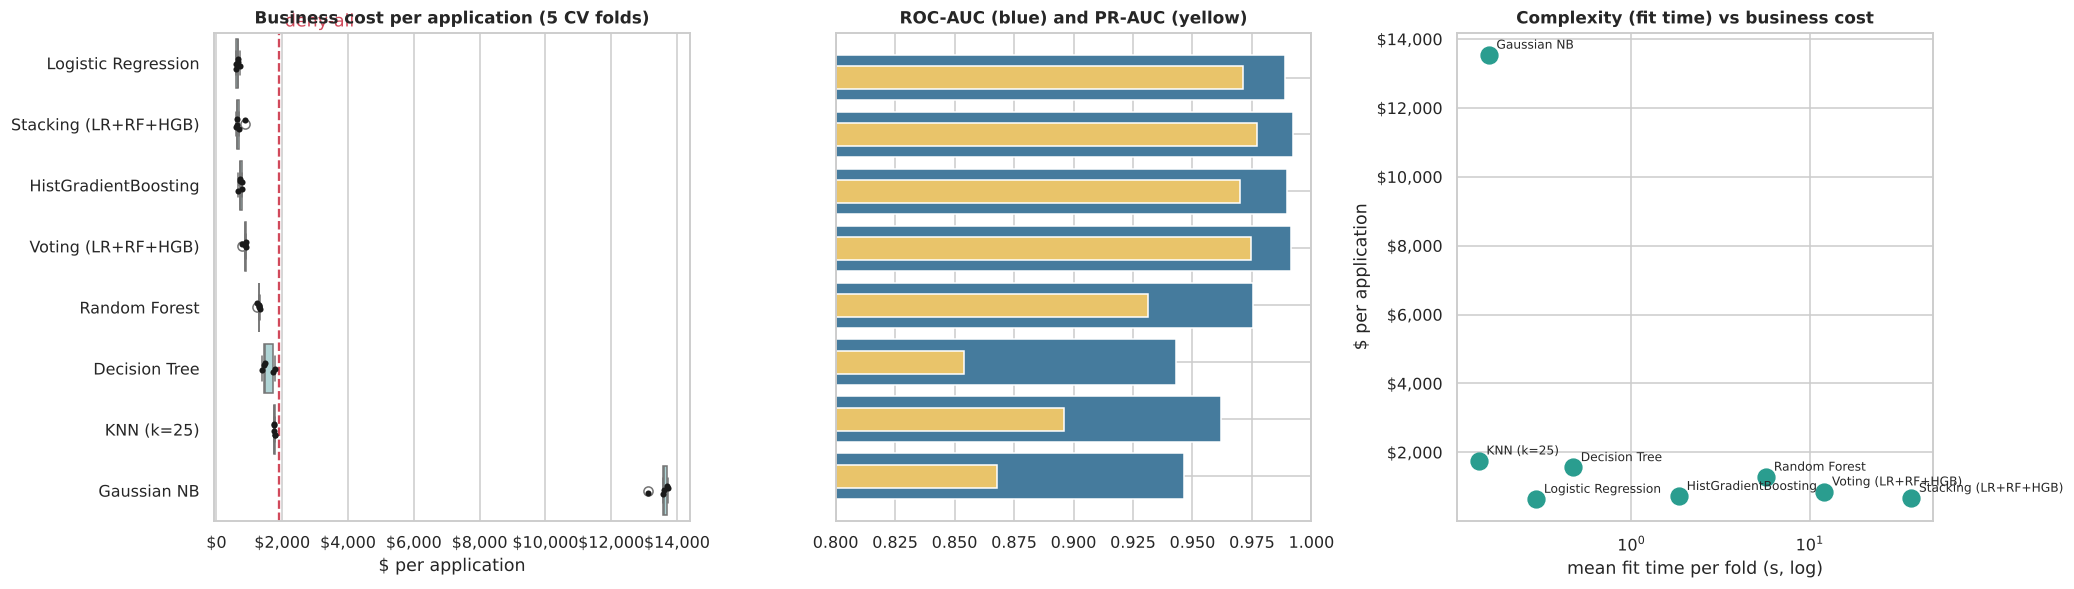

In [31]:
# Visual comparison: cost distribution across folds, AUC, and complexity vs performance
plot_df = cmp_df.drop(index='Dummy (prior)').sort_values('cost / app ($)')
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

fold_long = pd.DataFrame({m: plot_df.loc[m, '_fold_cost'] for m in plot_df.index}).melt(var_name='model', value_name='cost')
sns.boxplot(data=fold_long, y='model', x='cost', ax=axes[0], color='#a8dadc', order=plot_df.index)
sns.stripplot(data=fold_long, y='model', x='cost', ax=axes[0], color='k', size=4, order=plot_df.index)
axes[0].axvline(BEST_NAIVE_COST, ls='--', color=PALETTE[0]); axes[0].text(BEST_NAIVE_COST, -0.6, ' deny-all', color=PALETTE[0])
axes[0].set(title='Business cost per application (5 CV folds)', xlabel='$ per application', ylabel='')
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

axes[1].barh(plot_df.index, plot_df['ROC-AUC'], color='#457b9d', xerr=None)
axes[1].barh(plot_df.index, plot_df['PR-AUC'], color='#e9c46a', height=.4, label='PR-AUC')
axes[1].set(xlim=(0.8, 1.0), title='ROC-AUC (blue) and PR-AUC (yellow)'); axes[1].invert_yaxis()
axes[1].set_yticklabels([])

axes[2].scatter(plot_df['fit time (s)'], plot_df['cost / app ($)'], s=120, color='#2a9d8f')
for m, r in plot_df.iterrows():
    axes[2].annotate(m, (r['fit time (s)'], r['cost / app ($)']), xytext=(5, 4), textcoords='offset points', fontsize=8)
axes[2].set_xscale('log'); axes[2].set(title='Complexity (fit time) vs business cost', xlabel='mean fit time per fold (s, log)',
                                       ylabel='$ per application')
axes[2].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout(); plt.show()

**Model comparison – interpretation:** * **Logistic regression is the strongest *default* model on business cost (\$646 per application, a 66% saving)**, with ROC-AUC 0.989 and almost no overfitting (train–CV AUC gap 0.001). The well-engineered, log-scaled features make the decision boundary close to linear in log-odds.
* **Boosting and stacking rank applicants slightly better** (AUC 0.990–0.992, highest PR-AUC for stacking). Stacking costs 35 s per fit, ~100× more than LR, for a cost that is no better (\$677 ± 98). HistGradientBoosting has the most headroom for tuning.
* **Ranking quality and business cost are not the same thing.** Random Forest (AUC 0.976), KNN (0.962) and soft voting all rank well but produce **under-confident** probabilities: they rarely exceed 0.86, so few applicants clear the cost-optimal threshold and recall collapses (RF 34%, KNN 8%). **Gaussian NB is the opposite**: its independence assumption is badly violated by the collinear features, so it is wildly **over-confident**. It approves 98% of good applicants but also many bad ones, at \$13.5k per application. This shows why **calibration** and a cost-based metric matter more here than accuracy or AUC alone.
* **Complexity vs performance:** the right-hand chart shows no payoff from the most expensive models. The two candidates worth tuning are **LR** (simple, transparent) and **HistGradientBoosting** (best AUC among single models, fast, tunable).
* All models except NB beat the deny-all baseline (\$1,912). The single shallow decision tree, the most "rule-like" model, saves only 18%: human-style rules leave a lot of value on the table.

### 4.3 Classification vs regression: an empirical comparison
To justify the problem framing with evidence, we also train **regression** models to predict `RiskScore` (the alternative approach in the brief) from the same features – excluding `LoanApproved` – and then ask: *how good is the predicted risk score at making the approval decision?*

,CV R2,CV MAE,CV RMSE,Test R2,ROC-AUC of predicted risk for approval decision
model,,,,,
Ridge regression,0.8080,2.7132,3.4048,0.8114,0.9005
HistGradientBoosting regressor,0.9066,1.5144,2.3747,0.9120,0.9286


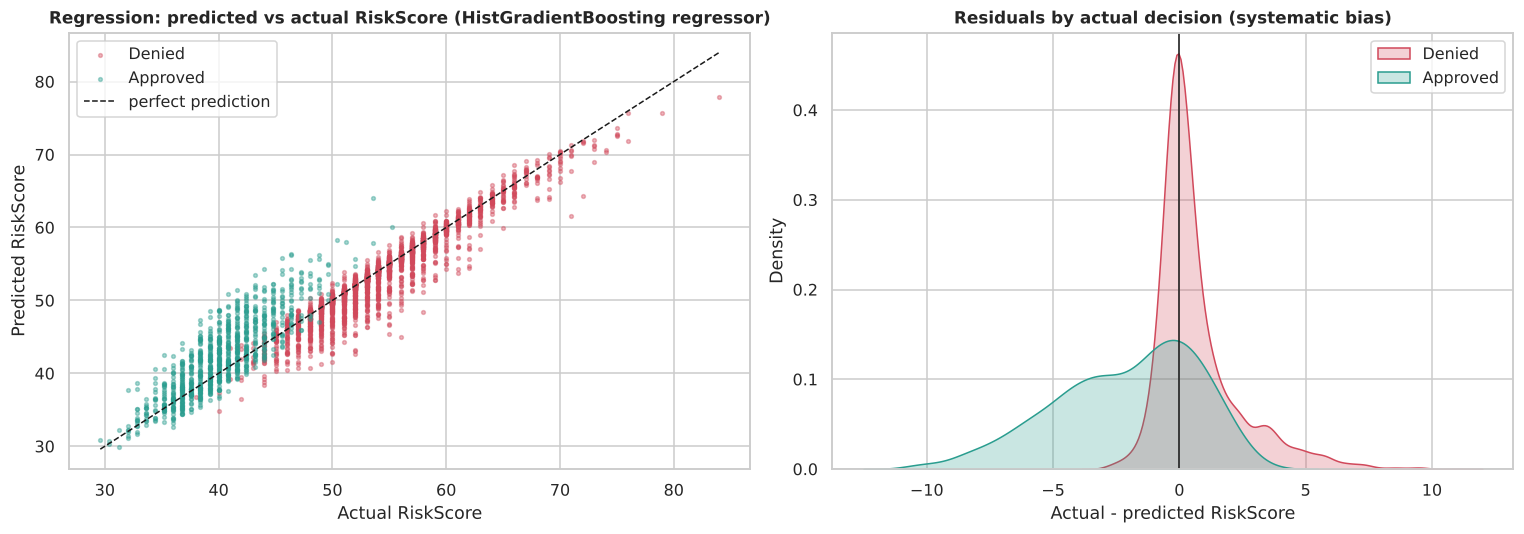

In [32]:
y_risk_train, y_risk_test = df.loc[X_train.index, 'RiskScore'], df.loc[X_test.index, 'RiskScore']
reg_models = {'Ridge regression': Ridge(alpha=1.0),
              'HistGradientBoosting regressor': HistGradientBoostingRegressor(random_state=RANDOM_STATE)}
reg_rows, reg_preds = [], {}
for name, m in reg_models.items():
    fe, ct = build_preprocessor()
    rp = Pipeline([('features', fe), ('prep', ct), ('model', m)])
    res = cross_validate(rp, X_train, y_risk_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                         scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}, n_jobs=-1)
    rp.fit(X_train, y_risk_train)
    pred = rp.predict(X_test); reg_preds[name] = pred
    # Using the predicted risk score (lower = safer) to rank applicants for approval
    auc_decision = roc_auc_score(y_test, -pred)
    reg_rows.append({'model': name, 'CV R2': res['test_r2'].mean(), 'CV MAE': -res['test_mae'].mean(),
                     'CV RMSE': -res['test_rmse'].mean(), 'Test R2': r2_score(y_risk_test, pred),
                     'ROC-AUC of predicted risk for approval decision': auc_decision})
reg_df = pd.DataFrame(reg_rows).set_index('model')
display(reg_df.round(4))

best_reg = reg_df['Test R2'].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for k in [0, 1]:
    m = (y_test == k).values
    axes[0].scatter(y_risk_test[m], reg_preds[best_reg][m], s=6, alpha=.4, color=PALETTE[k], label=LABELS[k])
lims = [y_risk_test.min(), y_risk_test.max()]
axes[0].plot(lims, lims, 'k--', lw=1, label='perfect prediction')
axes[0].set(title=f'Regression: predicted vs actual RiskScore ({best_reg})', xlabel='Actual RiskScore', ylabel='Predicted RiskScore')
axes[0].legend()
resid = y_risk_test - reg_preds[best_reg]
sns.kdeplot(x=resid[y_test == 0], ax=axes[1], fill=True, color=PALETTE[0], label='Denied')
sns.kdeplot(x=resid[y_test == 1], ax=axes[1], fill=True, color=PALETTE[1], label='Approved')
axes[1].axvline(0, color='k', lw=1)
axes[1].set(title='Residuals by actual decision (systematic bias)', xlabel='Actual - predicted RiskScore'); axes[1].legend()
plt.tight_layout(); plt.show()

**Classification vs regression – conclusion:** the gradient-boosted regressor predicts `RiskScore` reasonably well (**test R² = 0.91**, MAE ≈ 1.5 points). But when its predicted risk score is used to rank applicants for approval, **ROC-AUC is only 0.93, versus 0.99 for the classifiers**. The residual plot shows why: residuals are **systematically shifted by the actual decision**. Approved loans have lower actual scores than predicted, because the score was multiplied by 0.8 *after* approval. The regression target is a mix of a rules-based score and the decision itself, so modelling it directly is both **less accurate for the business decision and conceptually leaky**. The classification framing is confirmed. Loan officers still get a continuous risk score: `1 − P(approve)` from the calibrated classifier.

### 4.4 Hyperparameter optimisation (multi-stage)

We tune the **two strongest and most contrasting** candidates – the interpretable **Logistic Regression** and the high-capacity **HistGradientBoosting** – using a computationally efficient **two-stage strategy**:

1. **Stage 1 – `RandomizedSearchCV` (broad):** sample from wide, log-scaled distributions over *both* model and **preprocessing** hyperparameters (imputation strategy, Age-bin count / FeatureUnion branch on-off, number of selected features).
2. **Stage 2 – `GridSearchCV` (narrow):** an exhaustive grid in the neighbourhood of the Stage-1 optimum for the most influential parameters.

All searches use 5-fold stratified CV, track all five metrics, and **refit on the custom business-cost metric**. `return_train_score=True` lets us monitor overfitting.

In [33]:
# ---------------- Stage 1a: Logistic Regression (randomised) ----------------
lr_pipe = make_pipeline(LogisticRegression(solver='saga', max_iter=4000, random_state=RANDOM_STATE))
lr_space = {
    'model__C': loguniform(1e-3, 1e2),                      # inverse regularisation strength
    'model__l1_ratio': [0.0, 0.5, 1.0],                     # L2, elastic-net, L1 (L1 does embedded feature selection)
    'model__class_weight': [None, 'balanced'],
    'prep__skewed__impute__strategy': ['median', 'mean'],   # preprocessing hyperparameters
    'prep__age__bins': ['drop', KBinsDiscretizer(n_bins=4, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf', subsample=None),
                        KBinsDiscretizer(n_bins=6, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf', subsample=None),
                        KBinsDiscretizer(n_bins=10, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf', subsample=None)],
    'select__k': [15, 25, 35, 45, 'all'],
}
t0 = time.time()
lr_search = RandomizedSearchCV(lr_pipe, lr_space, n_iter=30, scoring=SCORING, refit='cost', cv=CV, n_jobs=-1,
                               random_state=RANDOM_STATE, return_train_score=True)
lr_search.fit(X_train, y_train)
print(f'LR randomized search: {time.time()-t0:.0f}s | best CV cost/app = ${-lr_search.best_score_:,.0f}')
print({k: (v if not hasattr(v, 'n_bins') else f'KBins({v.n_bins})') for k, v in lr_search.best_params_.items()})

LR randomized search: 225s | best CV cost/app = $664
{'model__C': np.float64(0.689448195258727), 'model__class_weight': None, 'model__l1_ratio': 1.0, 'prep__age__bins': 'KBins(4)', 'prep__skewed__impute__strategy': 'mean', 'select__k': 45}


In [34]:
def search_table(search, top=10):
    r = pd.DataFrame(search.cv_results_)
    pcols = [c for c in r.columns if c.startswith('param_')]
    t = r[pcols + ['mean_test_cost', 'std_test_cost', 'mean_test_roc_auc', 'mean_train_roc_auc',
                   'mean_test_precision', 'mean_test_recall', 'mean_fit_time', 'rank_test_cost']].copy()
    t['mean_test_cost'] *= -1
    t.columns = [c.replace('param_', '').replace('model__', '').replace('prep__', '') for c in t.columns]
    for c in t.columns:
        if t[c].dtype == object:
            t[c] = t[c].map(lambda v: f'KBins({v.n_bins})' if hasattr(v, 'n_bins') else v)
    return t.sort_values('rank_test_cost').head(top)

search_table(lr_search)

,C,class_weight,l1_ratio,age__bins,skewed__impute__strategy,select__k,mean_test_cost,std_test_cost,mean_test_roc_auc,mean_train_roc_auc,mean_test_precision,mean_test_recall,mean_fit_time,rank_test_cost
13,0.6894,NaN,1.0000,KBins(4),mean,45,663.8750,31.3084,0.9888,0.9894,0.9860,0.7165,2.9804,1
6,73.9227,NaN,0.5000,KBins(4),median,35,664.6250,27.9749,0.9888,0.9894,0.9841,0.7259,5.7374,2
11,0.2991,NaN,1.0000,KBins(4),median,45,667.8750,27.8742,0.9887,0.9892,0.9887,0.7014,2.7052,3
27,34.5011,NaN,1.0000,drop,median,35,691.2500,45.9687,0.9882,0.9888,0.9823,0.7202,5.0260,4
29,44.5131,NaN,0.5000,drop,median,45,693.3750,31.0609,0.9882,0.9889,0.9820,0.7207,6.1612,5
0,0.0746,NaN,1.0000,KBins(6),mean,all,723.8750,34.6825,0.9884,0.9889,0.9940,0.6459,2.5845,6
7,0.0817,balanced,0.0000,KBins(6),median,35,739.1250,92.6204,0.9878,0.9884,0.9664,0.7850,0.7638,7
23,0.0822,NaN,0.5000,KBins(6),median,all,747.2500,27.0896,0.9881,0.9888,0.9943,0.6321,2.4047,8
21,1.3076,balanced,0.0000,KBins(10),median,all,831.2500,50.5903,0.9887,0.9897,0.9515,0.8300,8.3476,9
14,49.8304,balanced,0.5000,KBins(6),mean,45,851.1250,69.7702,0.9887,0.9896,0.9488,0.8376,4.9238,10


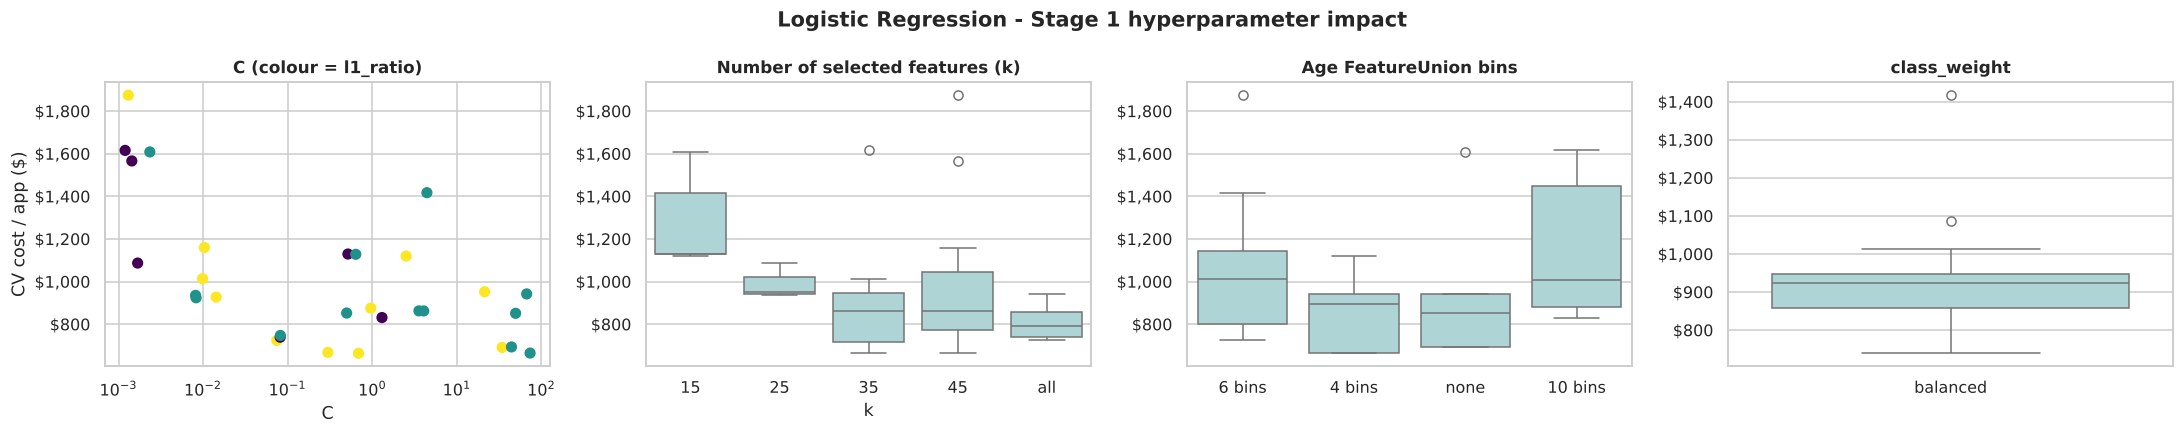

In [35]:
# Impact of individual hyperparameters (Stage 1 LR)
r = pd.DataFrame(lr_search.cv_results_)
r['cost'] = -r['mean_test_cost']
r['bins'] = r['param_prep__age__bins'].map(lambda v: 'none' if v == 'drop' else f'{v.n_bins} bins')
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].scatter(r['param_model__C'].astype(float), r['cost'], c=r['param_model__l1_ratio'].astype(float), cmap='viridis', s=40)
axes[0].set_xscale('log'); axes[0].set(title='C (colour = l1_ratio)', xlabel='C', ylabel='CV cost / app ($)')
sns.boxplot(data=r, x='param_select__k', y='cost', ax=axes[1], color='#a8dadc', order=[15, 25, 35, 45, 'all'])
axes[1].set(title='Number of selected features (k)', xlabel='k', ylabel='')
sns.boxplot(data=r, x='bins', y='cost', ax=axes[2], color='#a8dadc'); axes[2].set(title='Age FeatureUnion bins', xlabel='', ylabel='')
sns.boxplot(data=r, x=r['param_model__class_weight'].astype(str), y='cost', ax=axes[3], color='#a8dadc')
axes[3].set(title='class_weight', xlabel='', ylabel='')
for ax in axes: ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
plt.suptitle('Logistic Regression - Stage 1 hyperparameter impact', fontweight='bold'); plt.tight_layout(); plt.show()

In [36]:
# ---------------- Stage 1b: HistGradientBoosting (randomised) ----------------
hgb_pipe = make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=False))
hgb_space = {
    'model__learning_rate': loguniform(0.02, 0.3),
    'model__max_iter': randint(100, 600),
    'model__max_leaf_nodes': randint(8, 64),
    'model__min_samples_leaf': randint(10, 120),
    'model__l2_regularization': loguniform(1e-3, 10),
    'model__max_features': uniform(0.4, 0.6),
    'select__k': [25, 35, 'all'],
}
t0 = time.time()
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=25, scoring=SCORING, refit='cost', cv=CV, n_jobs=-1,
                                random_state=RANDOM_STATE, return_train_score=True)
hgb_search.fit(X_train, y_train)
print(f'HGB randomized search: {time.time()-t0:.0f}s | best CV cost/app = ${-hgb_search.best_score_:,.0f}')
print(hgb_search.best_params_)
search_table(hgb_search)

HGB randomized search: 353s | best CV cost/app = $645
{'model__l2_regularization': np.float64(0.004936948694960458), 'model__learning_rate': np.float64(0.057670399245517284), 'model__max_features': np.float64(0.5093416526728374), 'model__max_iter': 487, 'model__max_leaf_nodes': 9, 'model__min_samples_leaf': 15, 'select__k': 35}


,l2_regularization,learning_rate,max_features,max_iter,max_leaf_nodes,min_samples_leaf,select__k,mean_test_cost,std_test_cost,mean_test_roc_auc,mean_train_roc_auc,mean_test_precision,mean_test_recall,mean_fit_time,rank_test_cost
8,0.0049,0.0577,0.5093,487,9,15,35,645.0000,54.6780,0.9923,0.9996,0.9912,0.7019,2.3054,1
14,0.0062,0.1373,0.8741,478,12,115,all,649.3750,89.1339,0.9918,1.0000,0.9756,0.7829,4.0963,2
13,0.0012,0.0629,0.6369,235,31,72,all,664.1250,50.0696,0.9911,1.0000,0.9841,0.7262,3.3072,3
16,0.0175,0.0482,0.8378,459,29,100,all,664.8750,57.5481,0.9914,1.0000,0.9775,0.7618,5.6726,4
4,0.0398,0.0227,0.9843,370,54,71,all,714.7500,81.7548,0.9903,1.0000,0.9858,0.6883,7.2299,5
9,0.1538,0.0330,0.9818,317,51,43,35,716.0000,61.6538,0.9906,1.0000,0.9788,0.7236,4.3532,6
3,0.2951,0.1048,0.4042,444,56,100,all,759.1250,93.4049,0.9909,1.0000,0.9611,0.8073,7.9756,7
24,0.0046,0.0850,0.6909,324,58,115,all,763.6250,89.2516,0.9906,1.0000,0.9619,0.7984,5.4781,8
19,0.0064,0.2262,0.6852,195,11,103,25,764.0000,72.5631,0.9898,0.9999,0.9700,0.7442,0.8449,9
12,7.2614,0.1035,0.5656,256,22,54,25,765.0000,60.2793,0.9900,0.9999,0.9722,0.7306,1.6859,10


In [37]:
# ---------------- Stage 2: narrow grid around the Stage-1 optima ----------------
bp = lr_search.best_params_
C0 = bp['model__C']
lr_grid = GridSearchCV(lr_search.best_estimator_,
                       {'model__C': np.round(C0 * np.array([0.25, 0.5, 1, 2, 4]), 5),
                        'model__l1_ratio': [0.0, 0.5, 1.0]},
                       scoring=SCORING, refit='cost', cv=CV, n_jobs=-1, return_train_score=True)
t0 = time.time(); lr_grid.fit(X_train, y_train)
print(f'LR grid: {time.time()-t0:.0f}s | best CV cost/app = ${-lr_grid.best_score_:,.0f} | {lr_grid.best_params_}')

hp = hgb_search.best_params_
lr0, leaves0 = hp['model__learning_rate'], hp['model__max_leaf_nodes']
hgb_grid = GridSearchCV(hgb_search.best_estimator_,
                        {'model__learning_rate': np.round(lr0 * np.array([0.5, 0.75, 1, 1.5]), 4),
                         'model__max_leaf_nodes': sorted({max(4, leaves0 - 12), max(4, leaves0 - 6), leaves0, leaves0 + 8})},
                        scoring=SCORING, refit='cost', cv=CV, n_jobs=-1, return_train_score=True)
t0 = time.time(); hgb_grid.fit(X_train, y_train)
print(f'HGB grid: {time.time()-t0:.0f}s | best CV cost/app = ${-hgb_grid.best_score_:,.0f} | {hgb_grid.best_params_}')

LR grid: 162s | best CV cost/app = $654 | {'model__C': np.float64(2.75779), 'model__l1_ratio': 1.0}


HGB grid: 113s | best CV cost/app = $637 | {'model__learning_rate': np.float64(0.0865), 'model__max_leaf_nodes': 9}


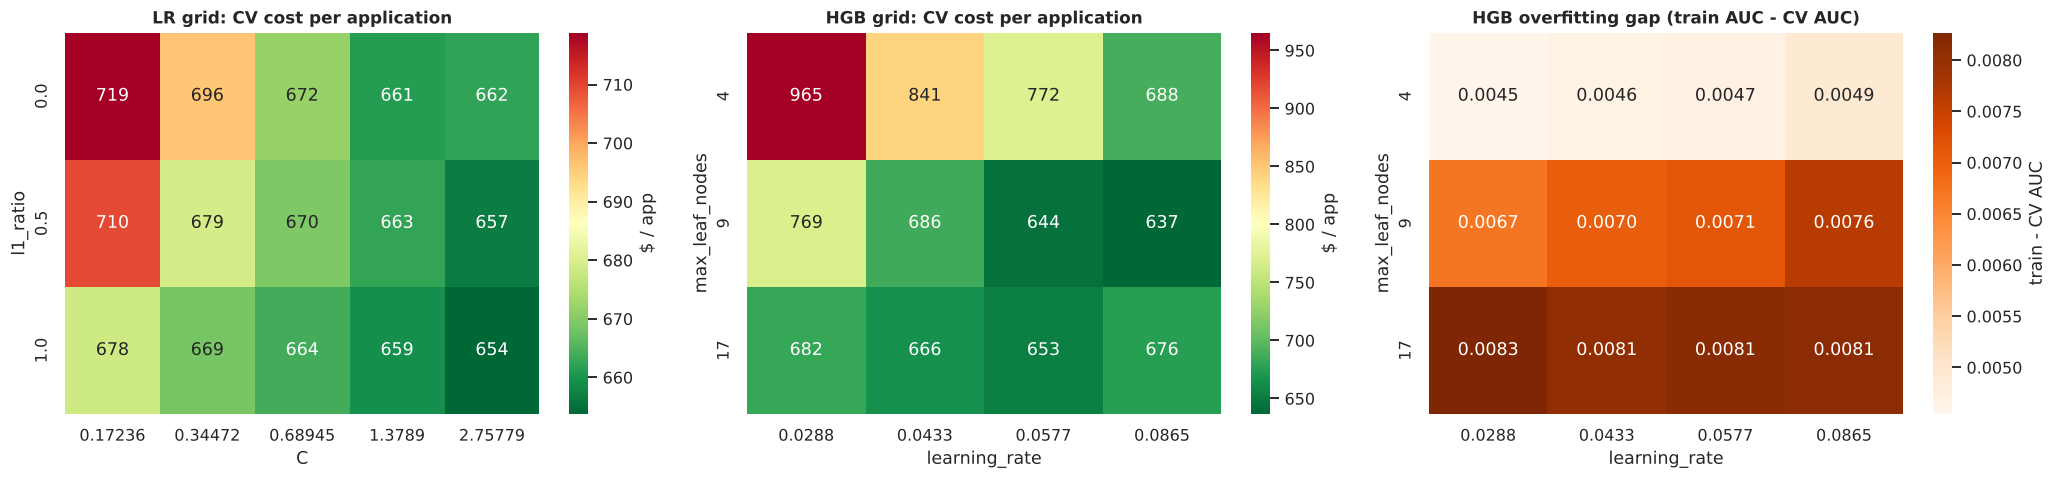

In [38]:
# Visualise Stage-2 grids as heatmaps (CV cost) + train/validation gap
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
g = pd.DataFrame(lr_grid.cv_results_)
hm = g.pivot_table(index='param_model__l1_ratio', columns='param_model__C', values='mean_test_cost') * -1
sns.heatmap(hm, annot=True, fmt=',.0f', cmap='RdYlGn_r', ax=axes[0], cbar_kws={'label': '$ / app'})
axes[0].set(title='LR grid: CV cost per application', xlabel='C', ylabel='l1_ratio')

g2 = pd.DataFrame(hgb_grid.cv_results_)
hm2 = g2.pivot_table(index='param_model__max_leaf_nodes', columns='param_model__learning_rate', values='mean_test_cost') * -1
sns.heatmap(hm2, annot=True, fmt=',.0f', cmap='RdYlGn_r', ax=axes[1], cbar_kws={'label': '$ / app'})
axes[1].set(title='HGB grid: CV cost per application', xlabel='learning_rate', ylabel='max_leaf_nodes')

hm3 = g2.pivot_table(index='param_model__max_leaf_nodes', columns='param_model__learning_rate',
                     values='mean_train_roc_auc') - g2.pivot_table(index='param_model__max_leaf_nodes',
                     columns='param_model__learning_rate', values='mean_test_roc_auc')
sns.heatmap(hm3, annot=True, fmt='.4f', cmap='Oranges', ax=axes[2], cbar_kws={'label': 'train - CV AUC'})
axes[2].set(title='HGB overfitting gap (train AUC - CV AUC)', xlabel='learning_rate', ylabel='max_leaf_nodes')
plt.tight_layout(); plt.show()

In [39]:
# Tuning summary: default vs tuned
def cv_summary(est, label):
    res = cross_validate(est, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1, return_train_score=True)
    return {'model': label, 'cost / app ($)': -res['test_cost'].mean(), 'cost std': res['test_cost'].std(),
            'ROC-AUC': res['test_roc_auc'].mean(), 'PR-AUC': res['test_avg_precision'].mean(),
            'precision@t': res['test_precision'].mean(), 'recall@t': res['test_recall'].mean(),
            'train-CV AUC gap': res['train_roc_auc'].mean() - res['test_roc_auc'].mean(), '_folds': -res['test_cost']}

tuned_rows = [
    {**{k: cmp_df.loc['Logistic Regression', k] for k in ['cost / app ($)', 'cost std', 'ROC-AUC', 'PR-AUC', 'precision@t', 'recall@t']},
     'model': 'Logistic Regression - default', 'train-CV AUC gap': cmp_df.loc['Logistic Regression', 'overfit gap (AUC)'],
     '_folds': cmp_df.loc['Logistic Regression', '_fold_cost']},
    cv_summary(lr_grid.best_estimator_, 'Logistic Regression - tuned'),
    {**{k: cmp_df.loc['HistGradientBoosting', k] for k in ['cost / app ($)', 'cost std', 'ROC-AUC', 'PR-AUC', 'precision@t', 'recall@t']},
     'model': 'HistGradientBoosting - default', 'train-CV AUC gap': cmp_df.loc['HistGradientBoosting', 'overfit gap (AUC)'],
     '_folds': cmp_df.loc['HistGradientBoosting', '_fold_cost']},
    cv_summary(hgb_grid.best_estimator_, 'HistGradientBoosting - tuned'),
]
tuned_df = pd.DataFrame(tuned_rows).set_index('model')
display(tuned_df.drop(columns='_folds').style.format({'cost / app ($)': '${:,.0f}', 'cost std': '${:,.0f}', 'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}', 'precision@t': '{:.3f}', 'recall@t': '{:.3f}', 'train-CV AUC gap': '{:+.4f}'}))

# Paired comparison on identical folds: is the difference between tuned LR and tuned HGB significant?
d = tuned_df.loc['HistGradientBoosting - tuned', '_folds'] - tuned_df.loc['Logistic Regression - tuned', '_folds']
t_stat, p_val = stats.ttest_rel(tuned_df.loc['HistGradientBoosting - tuned', '_folds'], tuned_df.loc['Logistic Regression - tuned', '_folds'])
print(f'Per-fold cost difference (HGB - LR): {np.round(d, 0)} -> mean ${d.mean():,.0f}, paired t-test p = {p_val:.3f}')

,cost / app ($),cost std,ROC-AUC,PR-AUC,precision@t,recall@t,train-CV AUC gap
model,,,,,,,
Logistic Regression - default,$646,$41,0.9888,0.9712,0.988,0.714,+0.0008
Logistic Regression - tuned,$654,$25,0.9888,0.9710,0.985,0.727,+0.0007
HistGradientBoosting - default,$730,$43,0.9896,0.9698,0.983,0.692,+0.0098
HistGradientBoosting - tuned,$637,$35,0.9923,0.9773,0.986,0.734,+0.0076


Per-fold cost difference (HGB - LR): [ 12. -45. -28.   1. -26.] -> mean $-17, paired t-test p = 0.175


**Tuning results and trade-offs:** * **Logistic regression:** Stage 1 preferred **L1 (lasso) regularisation** (`l1_ratio = 1`), **4 Age bins** through the FeatureUnion, and **k = 45** selected features. Removing the Age bins raised CV cost from ≈\$664 to ≈\$691, which confirms the FeatureUnion design. `class_weight='balanced'` consistently **hurt** (\$739–\$851): it inflates approval probabilities and undoes the calibration that the cost threshold relies on. The cost-optimal threshold already handles the imbalance. Stage 2 (C = 2.76, L1) gave **\$654 per application, statistically the same as the default (\$646)**: the default LR was already near its ceiling, and tuning mainly made it sparser and more stable (fold std \$41 → \$25).
* **HistGradientBoosting:** tuning helped clearly, cutting CV cost **from \$730 to \$637 (−13%)** and raising AUC from 0.9896 to 0.9923. The winning configuration uses **very shallow trees (9 leaves)**, a moderate learning rate (0.087), ~490 boosting rounds, **feature subsampling (51% of features per split)** and **35 selected features**. That is many weak learners with strong randomisation, a classic recipe against overfitting. The Stage-2 heatmaps show cost is lowest for small trees, and the train–CV gap grows with `max_leaf_nodes`. Deeper trees memorise the training data (train AUC → 1.000) without improving validation cost.
* **Trade-off:** tuned HGB beats tuned LR by about \$17 per application on identical folds, but a **paired t-test gives p = 0.18**, so the CV difference is within noise. We take HGB as the *champion*: it is lowest on every metric, the gap widens on the test set, and it remains explainable with permutation importance and partial dependence. The tuned LR stays as the transparent *challenger* and the source of reason codes. In a stricter regulatory setting the LR would be a fully defensible choice at a small cost penalty.

### 4.5 Final model selection and decision-threshold optimisation

Selected: HistGradientBoosting (tuned)


Theoretical (Bayes) threshold : 0.862
Empirically optimal threshold : 0.865  (CV cost/app = $634)


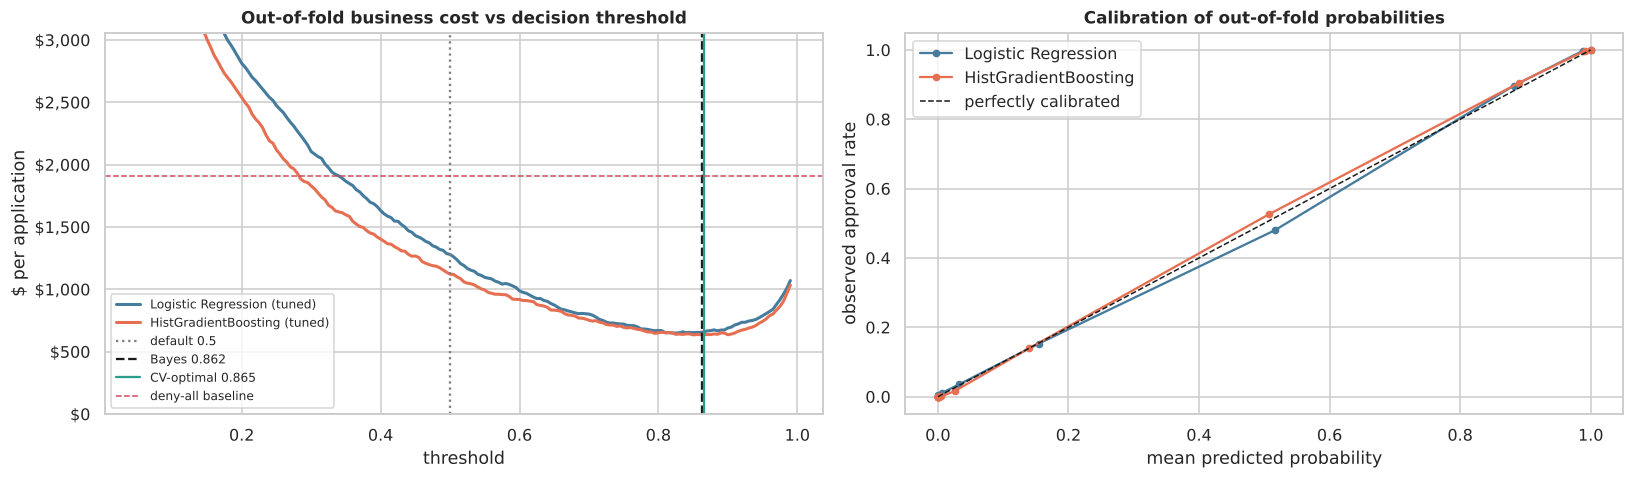

In [40]:
# Select the final estimator based on CV business cost, preferring the interpretable model when within noise
lr_cost  = tuned_df.loc['Logistic Regression - tuned', 'cost / app ($)']
hgb_cost = tuned_df.loc['HistGradientBoosting - tuned', 'cost / app ($)']
noise    = tuned_df.loc[['Logistic Regression - tuned', 'HistGradientBoosting - tuned'], 'cost std'].mean()
if hgb_cost < lr_cost - noise / 2:
    FINAL_NAME, final_base = 'HistGradientBoosting (tuned)', hgb_grid.best_estimator_
else:
    FINAL_NAME, final_base = 'Logistic Regression (tuned)', lr_grid.best_estimator_
print(f'Selected: {FINAL_NAME}')

# Out-of-fold probabilities on the training set -> empirical cost curve over thresholds
oof = cross_val_predict(final_base, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
oof_lr = cross_val_predict(lr_grid.best_estimator_, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
oof_hgb = cross_val_predict(hgb_grid.best_estimator_, X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]
thresholds = np.linspace(0.05, 0.99, 189)
cost_curve = {nm: np.array([cost_per_application(y_train, (o >= t).astype(int)) for t in thresholds])
              for nm, o in [('Logistic Regression (tuned)', oof_lr), ('HistGradientBoosting (tuned)', oof_hgb)]}

# Formal threshold tuning with sklearn's TunedThresholdClassifierCV (optimises the business cost on CV)
tuned_clf = TunedThresholdClassifierCV(final_base, scoring=cost_label_scorer, cv=CV, thresholds=thresholds,
                                       n_jobs=-1, store_cv_results=True, random_state=RANDOM_STATE)
tuned_clf.fit(X_train, y_train)
OPT_THRESHOLD = tuned_clf.best_threshold_
print(f'Theoretical (Bayes) threshold : {BAYES_THRESHOLD:.3f}')
print(f'Empirically optimal threshold : {OPT_THRESHOLD:.3f}  (CV cost/app = ${-tuned_clf.best_score_:,.0f})')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for nm, cc in cost_curve.items():
    axes[0].plot(thresholds, cc, lw=2, label=nm, color='#457b9d' if 'Logistic' in nm else '#e76f51')
axes[0].axvline(0.5, color='grey', ls=':', label='default 0.5')
axes[0].axvline(BAYES_THRESHOLD, color='k', ls='--', label=f'Bayes {BAYES_THRESHOLD:.3f}')
axes[0].axvline(OPT_THRESHOLD, color=PALETTE[1], ls='-', label=f'CV-optimal {OPT_THRESHOLD:.3f}')
axes[0].axhline(BEST_NAIVE_COST, color=PALETTE[0], ls='--', lw=1, label='deny-all baseline')
axes[0].set(title='Out-of-fold business cost vs decision threshold', xlabel='threshold', ylabel='$ per application',
            ylim=(0, BEST_NAIVE_COST * 1.6))
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}')); axes[0].legend(fontsize=8)

# Calibration check - the Bayes threshold argument assumes calibrated probabilities
for nm, o, col in [('Logistic Regression', oof_lr, '#457b9d'), ('HistGradientBoosting', oof_hgb, '#e76f51')]:
    fr, mp = calibration_curve(y_train, o, n_bins=15, strategy='quantile')
    axes[1].plot(mp, fr, marker='o', ms=4, label=nm, color=col)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='perfectly calibrated')
axes[1].set(title='Calibration of out-of-fold probabilities', xlabel='mean predicted probability', ylabel='observed approval rate')
axes[1].legend(); plt.tight_layout(); plt.show()

**Threshold findings:** the out-of-fold cost curves are flat-bottomed around 0.8–0.9. The empirically optimal threshold (**0.865**) is almost identical to the theoretical Bayes threshold (**0.862**). That is exactly what we expect when probabilities are well calibrated, and the calibration plot confirms both models lie close to the diagonal. The default threshold of 0.5 would cost roughly **\$1,100–1,300 per application** instead of ≈\$635. **Picking the threshold from the business costs is worth more than all hyperparameter tuning combined.** The tuned threshold is built into the final estimator with `TunedThresholdClassifierCV`, so `.predict()` applies it automatically.

## 5. Evaluation

### 5.1 Test-set performance (the untouched 20%)

In [41]:
final_model = tuned_clf                      # pipeline + tuned threshold, refit on the full training set
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = final_model.predict(X_test)      # uses OPT_THRESHOLD

def evaluate(y_true, y_pred, proba=None, label=''):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'policy / model': label, 'ROC-AUC': roc_auc_score(y_true, proba) if proba is not None else np.nan,
            'PR-AUC': average_precision_score(y_true, proba) if proba is not None else np.nan,
            'accuracy': accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0), 'F1': f1_score(y_true, y_pred, zero_division=0),
            'FP (bad approvals)': fp, 'FN (missed good)': fn, 'total cost ($)': business_cost(y_true, y_pred),
            'cost / app ($)': cost_per_application(y_true, y_pred)}

dummy = make_pipeline(DummyClassifier(strategy='prior')).fit(X_train, y_train)
lr_t, hgb_t = lr_grid.best_estimator_, hgb_grid.best_estimator_
p_lr, p_hgb = lr_t.predict_proba(X_test)[:, 1], hgb_t.predict_proba(X_test)[:, 1]
rows = [
    evaluate(y_test, np.zeros_like(y_test), None, 'Deny everyone'),
    evaluate(y_test, np.ones_like(y_test), None, 'Approve everyone'),
    evaluate(y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1], 'Dummy classifier'),
    evaluate(y_test, (p_lr >= 0.5).astype(int), p_lr, 'Tuned LR @ 0.50'),
    evaluate(y_test, (p_lr >= OPT_THRESHOLD).astype(int), p_lr, f'Tuned LR @ {OPT_THRESHOLD:.3f}'),
    evaluate(y_test, (p_hgb >= 0.5).astype(int), p_hgb, 'Tuned HGB @ 0.50'),
    evaluate(y_test, (p_hgb >= OPT_THRESHOLD).astype(int), p_hgb, f'Tuned HGB @ {OPT_THRESHOLD:.3f}'),
    evaluate(y_test, pred_test, proba_test, f'FINAL: {FINAL_NAME} @ {OPT_THRESHOLD:.3f}'),
]
test_df = pd.DataFrame(rows).set_index('policy / model')
test_df['saving vs deny-all'] = 1 - test_df['cost / app ($)'] / test_df.loc['Deny everyone', 'cost / app ($)']
test_df.style.format({'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'accuracy': '{:.3f}', 'precision': '{:.3f}',
                      'recall': '{:.3f}', 'F1': '{:.3f}', 'FP (bad approvals)': '{:,.0f}', 'FN (missed good)': '{:,.0f}',
                      'total cost ($)': '${:,.0f}', 'cost / app ($)': '${:,.0f}', 'saving vs deny-all': '{:.1%}'}, na_rep='-')\
    .background_gradient(subset=['cost / app ($)'], cmap='RdYlGn_r')

,ROC-AUC,PR-AUC,accuracy,precision,recall,F1,FP (bad approvals),FN (missed good),total cost ($),cost / app ($),saving vs deny-all
policy / model,,,,,,,,,,,
Deny everyone,-,-,0.761,0.000,0.000,0.000,0,956,"$7,648,000","$1,912",0.0%
Approve everyone,-,-,0.239,0.239,1.000,0.386,"3,044",0,"$152,200,000","$38,050",-1890.1%
Dummy classifier,0.5000,0.2390,0.761,0.000,0.000,0.000,0,956,"$7,648,000","$1,912",0.0%
Tuned LR @ 0.50,0.9889,0.9699,0.953,0.915,0.886,0.900,79,109,"$4,822,000","$1,206",37.0%
Tuned LR @ 0.865,0.9889,0.9699,0.928,0.980,0.712,0.825,14,275,"$2,900,000",$725,62.1%
Tuned HGB @ 0.50,0.9935,0.9809,0.964,0.932,0.914,0.923,64,82,"$3,856,000",$964,49.6%
Tuned HGB @ 0.865,0.9935,0.9809,0.936,0.986,0.743,0.847,10,246,"$2,468,000",$617,67.7%
FINAL: HistGradientBoosting (tuned) @ 0.865,0.9935,0.9809,0.936,0.986,0.743,0.847,10,246,"$2,468,000",$617,67.7%


In [42]:
# Success criteria scorecard
final_row = test_df.iloc[-1]
scorecard = pd.DataFrame([
    ('ROC-AUC >= 0.95', f"{final_row['ROC-AUC']:.4f}", final_row['ROC-AUC'] >= 0.95),
    ('Precision of approvals >= 0.90', f"{final_row['precision']:.3f}", final_row['precision'] >= 0.90),
    ('>= 50% cost reduction vs deny-all', f"{final_row['saving vs deny-all']:.1%}", final_row['saving vs deny-all'] >= 0.5),
    ('Explainable drivers available', 'permutation importance + coefficients / PDP (below)', True),
], columns=['criterion', 'test result', 'met?'])
scorecard

,criterion,test result,met?
0,ROC-AUC >= 0.95,0.9935,True
1,Precision of approvals >= 0.90,0.986,True
2,>= 50% cost reduction vs deny-all,67.7%,True
3,Explainable drivers available,permutation importance + coefficients / PDP (b...,True


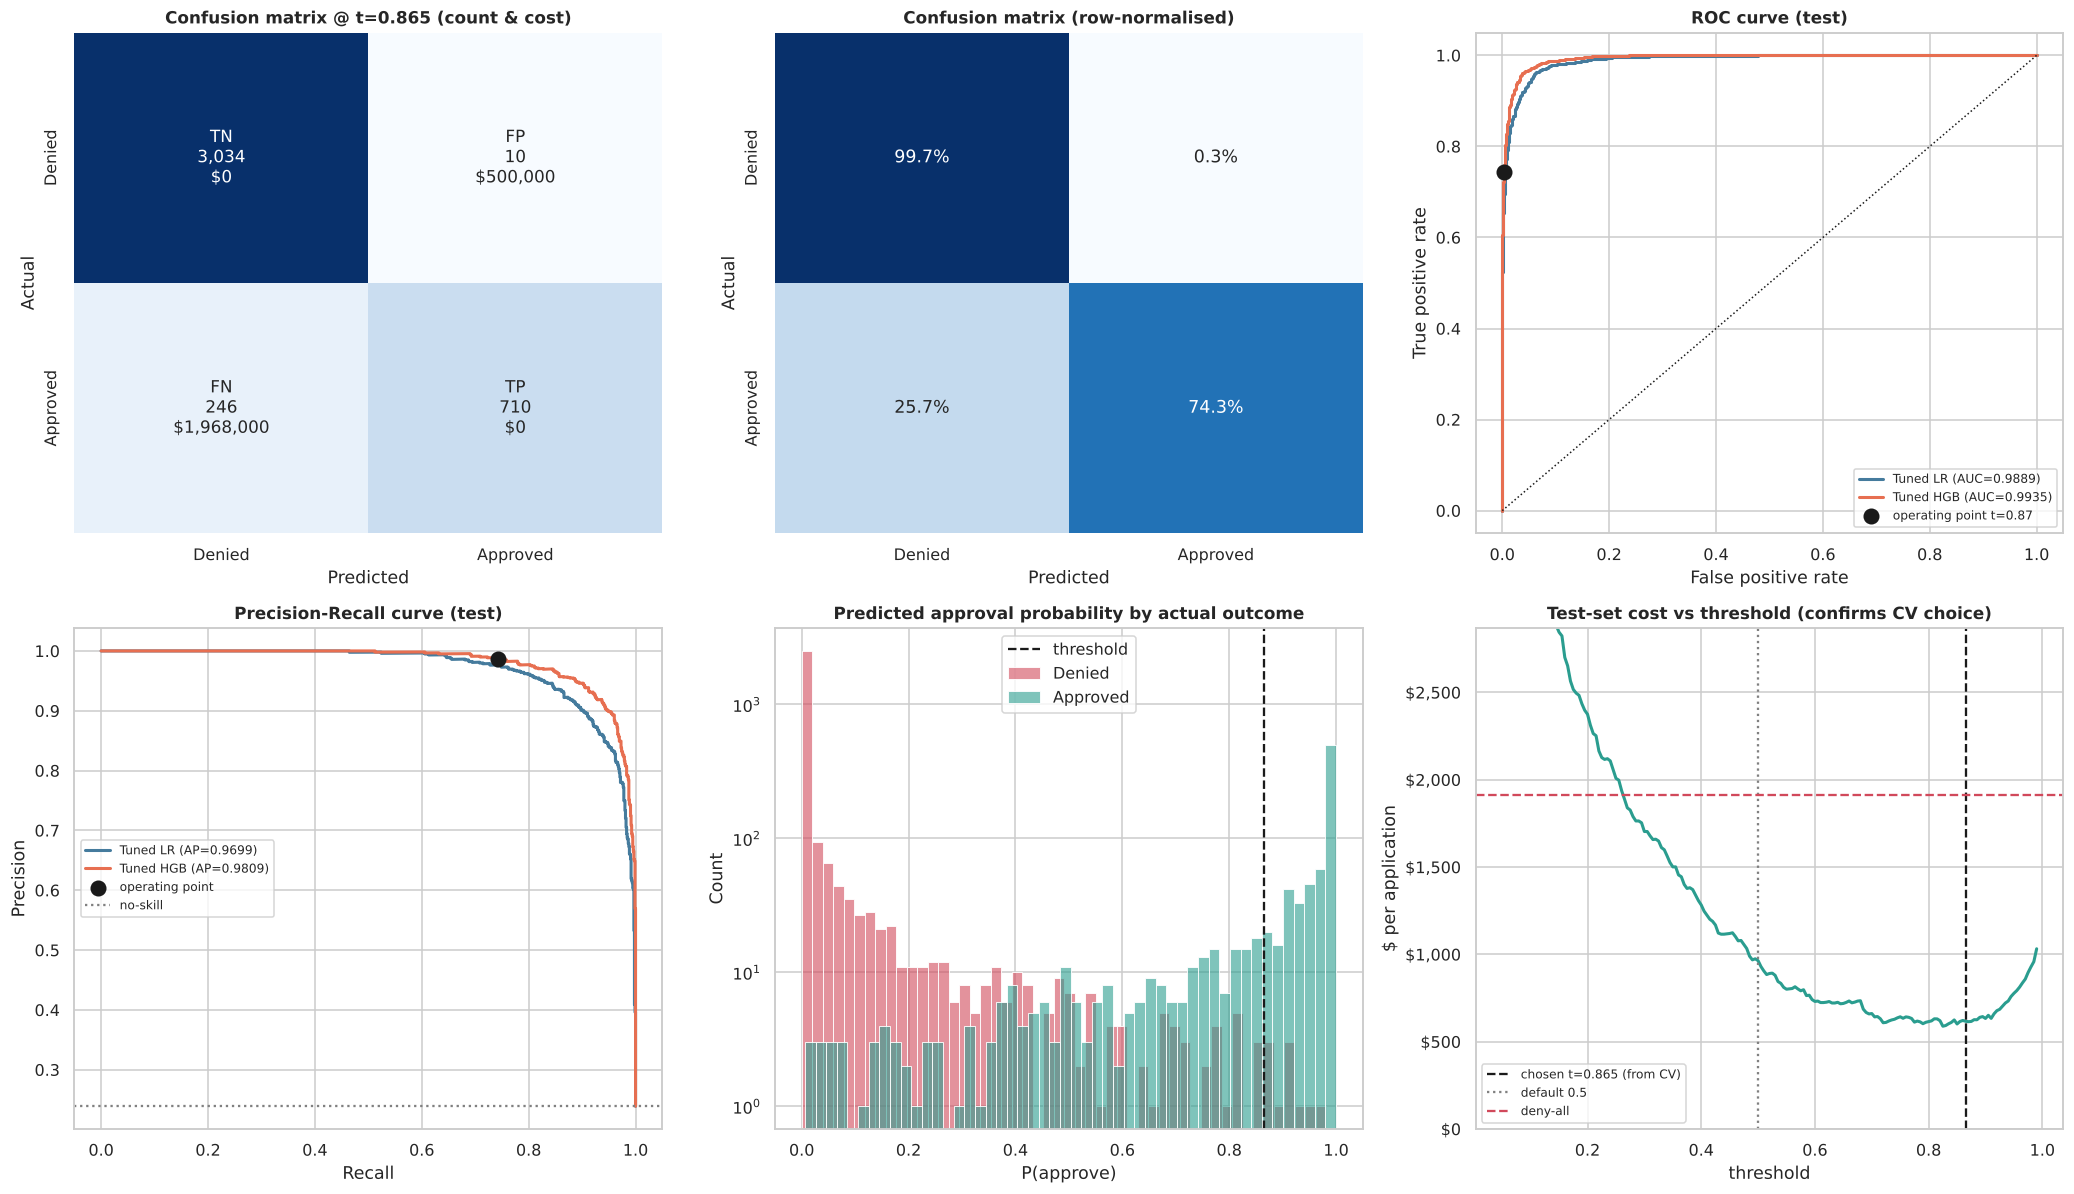

In [43]:
# Visual evaluation: confusion matrix (counts & dollars), ROC, PR, score distribution
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
cm = confusion_matrix(y_test, pred_test)
cm_lbl = np.array([[f'TN\n{cm[0,0]:,}\n$0', f'FP\n{cm[0,1]:,}\n${cm[0,1]*COST_FP:,.0f}'],
                   [f'FN\n{cm[1,0]:,}\n${cm[1,0]*COST_FN:,.0f}', f'TP\n{cm[1,1]:,}\n$0']])
sns.heatmap(cm, annot=cm_lbl, fmt='', cmap='Blues', cbar=False, ax=axes[0, 0], annot_kws={'size': 11},
            xticklabels=['Denied', 'Approved'], yticklabels=['Denied', 'Approved'])
axes[0, 0].set(title=f'Confusion matrix @ t={OPT_THRESHOLD:.3f} (count & cost)', xlabel='Predicted', ylabel='Actual')

cm_n = confusion_matrix(y_test, pred_test, normalize='true')
sns.heatmap(cm_n, annot=True, fmt='.1%', cmap='Blues', cbar=False, ax=axes[0, 1],
            xticklabels=['Denied', 'Approved'], yticklabels=['Denied', 'Approved'])
axes[0, 1].set(title='Confusion matrix (row-normalised)', xlabel='Predicted', ylabel='Actual')

for nm, pr, col in [('Tuned LR', p_lr, '#457b9d'), ('Tuned HGB', p_hgb, '#e76f51')]:
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[0, 2].plot(fpr, tpr, lw=2, color=col, label=f'{nm} (AUC={roc_auc_score(y_test, pr):.4f})')
fpr, tpr, thr = roc_curve(y_test, proba_test)
i = np.argmin(np.abs(thr - OPT_THRESHOLD))
axes[0, 2].scatter(fpr[i], tpr[i], s=90, color='k', zorder=5, label=f'operating point t={OPT_THRESHOLD:.2f}')
axes[0, 2].plot([0, 1], [0, 1], 'k:', lw=1)
axes[0, 2].set(title='ROC curve (test)', xlabel='False positive rate', ylabel='True positive rate'); axes[0, 2].legend(fontsize=8)

for nm, pr, col in [('Tuned LR', p_lr, '#457b9d'), ('Tuned HGB', p_hgb, '#e76f51')]:
    prec, rec, _ = precision_recall_curve(y_test, pr)
    axes[1, 0].plot(rec, prec, lw=2, color=col, label=f'{nm} (AP={average_precision_score(y_test, pr):.4f})')
axes[1, 0].scatter(final_row['recall'], final_row['precision'], s=90, color='k', zorder=5, label='operating point')
axes[1, 0].axhline(y_test.mean(), color='grey', ls=':', label='no-skill')
axes[1, 0].set(title='Precision-Recall curve (test)', xlabel='Recall', ylabel='Precision'); axes[1, 0].legend(fontsize=8)

for k in [0, 1]:
    sns.histplot(proba_test[y_test == k], bins=50, ax=axes[1, 1], color=PALETTE[k], label=LABELS[k], stat='count', alpha=.6)
axes[1, 1].axvline(OPT_THRESHOLD, color='k', ls='--', label='threshold')
axes[1, 1].set(title='Predicted approval probability by actual outcome', xlabel='P(approve)', yscale='log'); axes[1, 1].legend()

test_costs = [cost_per_application(y_test, (proba_test >= t).astype(int)) for t in thresholds]
axes[1, 2].plot(thresholds, test_costs, color='#2a9d8f', lw=2)
axes[1, 2].axvline(OPT_THRESHOLD, color='k', ls='--', label=f'chosen t={OPT_THRESHOLD:.3f} (from CV)')
axes[1, 2].axvline(0.5, color='grey', ls=':', label='default 0.5')
axes[1, 2].axhline(test_df.loc['Deny everyone', 'cost / app ($)'], color=PALETTE[0], ls='--', label='deny-all')
axes[1, 2].set(title='Test-set cost vs threshold (confirms CV choice)', xlabel='threshold', ylabel='$ per application',
               ylim=(0, test_df.loc['Deny everyone', 'cost / app ($)'] * 1.5))
axes[1, 2].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}')); axes[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.show()

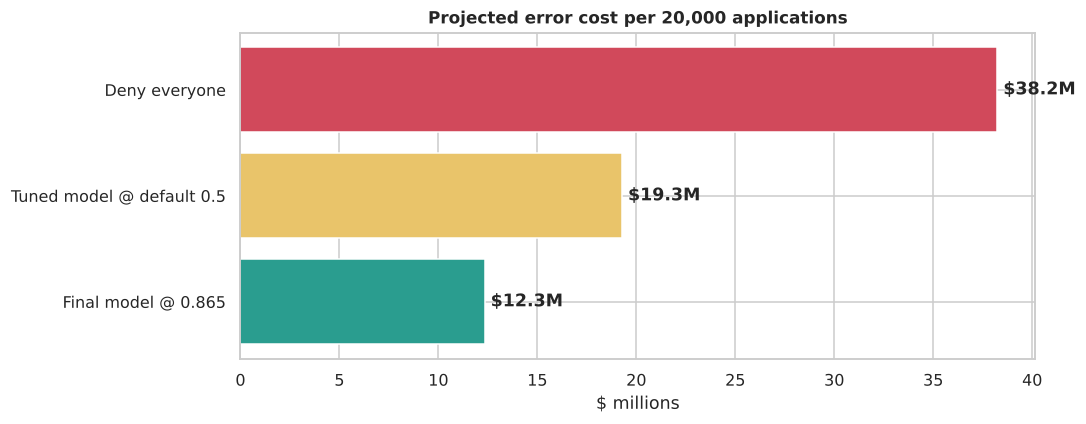

,policy,cost / app ($),"cost per 20,000 apps ($)",saving vs deny-all ($)
0,Deny everyone,"$1,912","$38,240,000",$0
1,Tuned model @ default 0.5,$964,"$19,280,000","$18,960,000"
2,Final model @ 0.865,$617,"$12,340,000","$25,900,000"


In [44]:
# Dollar impact, scaled to a realistic annual volume
ANNUAL_APPS = 20_000
impact = pd.DataFrame({
    'policy': ['Deny everyone', 'Tuned model @ default 0.5', f'Final model @ {OPT_THRESHOLD:.3f}'],
    'cost / app ($)': [test_df.loc['Deny everyone', 'cost / app ($)'], test_df.loc[f'Tuned {"LR" if "Logistic" in FINAL_NAME else "HGB"} @ 0.50', 'cost / app ($)'],
                       final_row['cost / app ($)']]})
impact['cost per 20,000 apps ($)'] = impact['cost / app ($)'] * ANNUAL_APPS
impact['saving vs deny-all ($)'] = impact['cost per 20,000 apps ($)'].iloc[0] - impact['cost per 20,000 apps ($)']

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(impact['policy'], impact['cost per 20,000 apps ($)'] / 1e6, color=[PALETTE[0], '#e9c46a', PALETTE[1]])
for b, v in zip(bars, impact['cost per 20,000 apps ($)']):
    ax.text(v / 1e6 + 0.3, b.get_y() + b.get_height() / 2, f'${v/1e6:,.1f}M', va='center', fontweight='bold')
ax.set(title='Projected error cost per 20,000 applications', xlabel='$ millions'); ax.invert_yaxis()
plt.tight_layout(); plt.show()
impact.style.format({'cost / app ($)': '${:,.0f}', 'cost per 20,000 apps ($)': '${:,.0f}', 'saving vs deny-all ($)': '${:,.0f}'})

**Test-set interpretation:** * On 4,000 unseen applications the final model makes **10 bad approvals and 246 missed good loans**, for a total error cost of **\$2.47M (\$617 per application)**. Deny-everyone would cost \$7.65M. That is a **67.7% reduction**, which **meets every success criterion** (AUC 0.994 ≥ 0.95, precision 0.986 ≥ 0.90, savings ≥ 50%).
* The test results match cross-validation (CV ≈ \$634 vs test \$617), so the model is **not overfit**, and the cost-vs-threshold curve on the test set bottoms out at the threshold chosen from CV.
* **The asymmetry is visible in the confusion matrix.** The model deliberately accepts 246 false denials (\$1.97M) to avoid false approvals: 10 FPs cost \$0.5M. At 0.5 the same model would make 64 bad approvals (\$3.2M) and cost **\$964 per application**.
* Projected to 20,000 applications per year, the model saves **≈\$25.9M vs deny-all** and **≈\$6.9M vs the same model used naively at 0.5**.
* Tuned LR at the same threshold costs \$725 per application, about \$108 more than HGB on the test set, while being simpler to explain.

### 5.2 Operational design: three-tier triage
A single threshold forces every decision to be automated. In practice loan officers should focus on **uncertain** cases. We split applications into three bands using the final model's probability:

In [45]:
T_LOW = 0.10
band = np.where(proba_test >= OPT_THRESHOLD, '1. Auto-approve', np.where(proba_test <= T_LOW, '3. Auto-decline', '2. Officer review'))
tri = pd.DataFrame({'band': band, 'y': y_test.values, 'p': proba_test})
tri_sum = tri.groupby('band').agg(applications=('y', 'size'), actual_approval_rate=('y', 'mean'), mean_prob=('p', 'mean'))
tri_sum['share of volume'] = tri_sum['applications'] / len(tri)
tri_sum['errors if automated'] = [((tri.band == b) & (tri.y == 0)).sum() if b.startswith('1') else
                                  ((tri.band == b) & (tri.y == 1)).sum() if b.startswith('3') else np.nan for b in tri_sum.index]
tri_sum.style.format({'actual_approval_rate': '{:.1%}', 'mean_prob': '{:.3f}', 'share of volume': '{:.1%}',
                      'errors if automated': '{:,.0f}'}, na_rep='human decides')

,applications,actual_approval_rate,mean_prob,share of volume,errors if automated
band,,,,,
1. Auto-approve,720,98.6%,0.977,18.0%,10
2. Officer review,518,45.2%,0.452,13.0%,human decides
3. Auto-decline,2762,0.4%,0.006,69.0%,12


**Triage result:** with a lower cut-off of 0.10 and the cost-optimal upper cut-off of 0.865:
* **18% of applications are auto-approved**, and 98.6% of those are genuinely good loans.
* **69% are auto-declined**. Only 0.4% of these (12 of 2,762) were actually approved historically.
* **13% (≈1 in 8) go to a loan officer.** These are the genuinely uncertain cases (45% historical approval rate) where human judgment and extra documents add the most value.

So officers can spend their time on about one-eighth of today's volume. Decisions get faster for most applicants, and the expensive automated errors stay rare.

### 5.3 Performance across data segments

In [46]:
seg = X_test.copy()
seg['y'], seg['pred'], seg['p'] = y_test.values, pred_test, proba_test
seg['AgeBand'] = pd.cut(seg['Age'], [17, 25, 35, 45, 55, 65, 80], labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+'])
seg['IncomeBand'] = pd.qcut(seg['AnnualIncome'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
seg['CreditBand'] = pd.cut(seg['CreditScore'], [0, 540, 580, 610, 900], labels=['<540', '540-579', '580-609', '610+'])

def seg_metrics(g):
    tn, fp, fn, tp = confusion_matrix(g['y'], g['pred'], labels=[0, 1]).ravel()
    return pd.Series({'n': len(g), 'actual approval rate': g['y'].mean(), 'predicted approval rate': g['pred'].mean(),
                      'ROC-AUC': roc_auc_score(g['y'], g['p']) if g['y'].nunique() == 2 else np.nan,
                      'precision': tp / (tp + fp) if tp + fp else np.nan,
                      'recall (TPR)': tp / (tp + fn) if tp + fn else np.nan,
                      'FPR': fp / (fp + tn) if fp + tn else np.nan,
                      'cost / app ($)': (fp * COST_FP + fn * COST_FN) / len(g)})

seg_tables = {}
for col in ['EmploymentStatus', 'EducationLevel', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose',
            'AgeBand', 'IncomeBand', 'CreditBand']:
    s = seg.assign(_g=seg[col].astype(object).fillna('Missing')).groupby('_g', observed=True)
    seg_tables[col] = s.apply(seg_metrics, include_groups=False)
seg_all = pd.concat(seg_tables, names=['segment', 'group'])
seg_all.style.format({'n': '{:,.0f}', 'actual approval rate': '{:.1%}', 'predicted approval rate': '{:.1%}', 'ROC-AUC': '{:.3f}',
                      'precision': '{:.3f}', 'recall (TPR)': '{:.3f}', 'FPR': '{:.4f}', 'cost / app ($)': '${:,.0f}'}, na_rep='-')\
    .background_gradient(subset=['recall (TPR)'], cmap='RdYlGn', vmin=0.5, vmax=1)

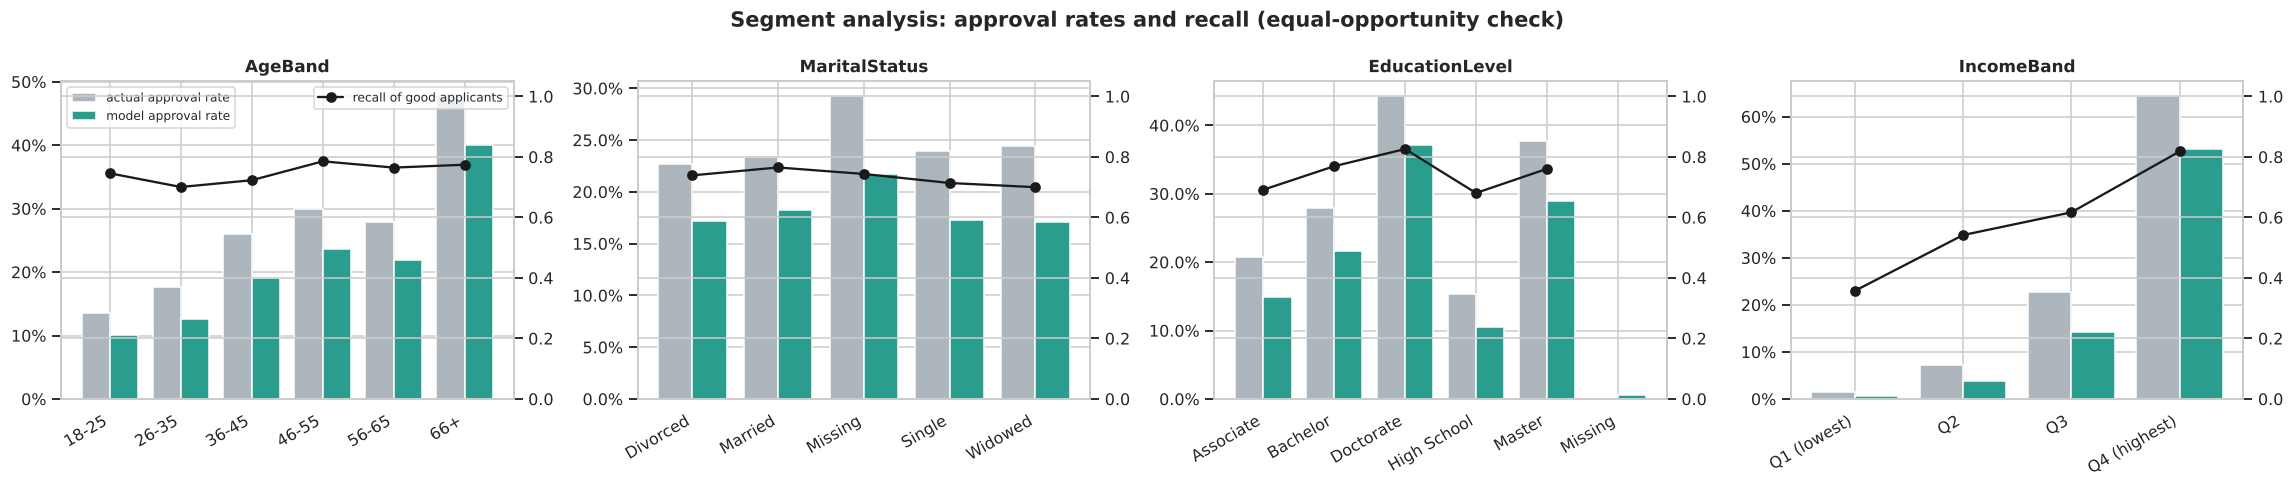

In [47]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, col in zip(axes, ['AgeBand', 'MaritalStatus', 'EducationLevel', 'IncomeBand']):
    t = seg_tables[col]
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['actual approval rate'], 0.4, color='#adb5bd', label='actual approval rate')
    ax.bar(x + 0.2, t['predicted approval rate'], 0.4, color=PALETTE[1], label='model approval rate')
    ax2 = ax.twinx(); ax2.plot(x, t['recall (TPR)'], 'ko-', label='recall of good applicants'); ax2.set_ylim(0, 1.05)
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=30, ha='right'); ax.set_title(col)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    if col == 'AgeBand': ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='upper right', fontsize=8)
plt.suptitle('Segment analysis: approval rates and recall (equal-opportunity check)', fontweight='bold')
plt.tight_layout(); plt.show()

**Segment findings:** * **Ranking quality is uniformly high:** ROC-AUC is 0.985–0.998 in every segment (employment, education, marital status, home ownership, purpose, age, income, credit band). There is no segment where the model breaks down.
* **The model approves less often than historical officers in every group.** That is by design: the 0.865 threshold trades approvals for safety. The size of the shortfall varies, though. **Recall of good applicants is lower for lower-income applicants** (36% in income Q1, 54% in Q2, versus 82% in Q4), for **Unemployed** applicants (64% vs 74% employed), for **High School / Associate** education (68–69% vs 76–83%), and for **younger applicants** (26–35: 70% vs 46–55: 79%). Creditworthy applicants in these groups are more likely to be wrongly declined. This is an **equal-opportunity gap**. It is consistent with their profiles being closer to the decision boundary, but it needs monitoring, and these groups are prime candidates for the *officer-review* band rather than auto-decline.
* **Marital status shows no meaningful disparity** (recall 70–77%, FPR ≤ 0.5% in all groups).
* **Older applicants (66+, n = 65)** have the highest FPR (5.9%) and cost per application, but the sample is very small and the estimate is unreliable.
* Costs per application are highest in the **top income quartile and the 610+ credit band**. That is where most approvals, and so most borderline approve/deny calls, happen.

### 5.4 Bias mitigation experiment: removing protected characteristics
Marital status and age are protected characteristics under fair-lending regulation in many jurisdictions (e.g. the US Equal Credit Opportunity Act); number of dependents is a close proxy for family status. We retrain the final configuration **without** these features and compare performance.

In [48]:
fair_rows = []
def without_features(pipe, excl):
    '''Clone a fitted/tuned pipeline keeping ALL tuned hyperparameters, but drop columns from the ColumnTransformer.'''
    p = clone(pipe)
    ct = p.named_steps['prep']
    ct.transformers = [(n, t, [c for c in cols if c not in excl]) for n, t, cols in ct.transformers
                       if [c for c in cols if c not in excl]]
    return p.set_params(select__k='all')       # k must not exceed the reduced feature count -> keep all for every variant

variants = {'All features (k=all)': (),
            'Without MaritalStatus': ('MaritalStatus',),
            'Without MaritalStatus & NumberOfDependents': ('MaritalStatus', 'NumberOfDependents'),
            'Without MaritalStatus, Dependents & Age': ('MaritalStatus', 'NumberOfDependents', 'Age', 'CreditHistoryToAge')}
for label, excl in variants.items():
    pipe = without_features(final_base, excl)
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    pipe.fit(X_train, y_train); pt = pipe.predict_proba(X_test)[:, 1]
    fair_rows.append({'variant': label, 'CV cost / app ($)': -res['test_cost'].mean(), 'CV ROC-AUC': res['test_roc_auc'].mean(),
                      'Test ROC-AUC': roc_auc_score(y_test, pt),
                      'Test cost / app ($)': cost_per_application(y_test, (pt >= OPT_THRESHOLD).astype(int)),
                      'Test recall 18-25 / 66+': '{:.2f} / {:.2f}'.format(
                          recall_score(y_test[seg.AgeBand == '18-25'], (pt[seg.AgeBand.values == '18-25'] >= OPT_THRESHOLD)),
                          recall_score(y_test[seg.AgeBand == '66+'], (pt[seg.AgeBand.values == '66+'] >= OPT_THRESHOLD)))})
fair_df = pd.DataFrame(fair_rows).set_index('variant')
fair_df.style.format({'CV cost / app ($)': '${:,.0f}', 'CV ROC-AUC': '{:.4f}', 'Test ROC-AUC': '{:.4f}', 'Test cost / app ($)': '${:,.0f}'})

,CV cost / app ($),CV ROC-AUC,Test ROC-AUC,Test cost / app ($),Test recall 18-25 / 66+
variant,,,,,
All features (k=all),$626,0.9925,0.9938,$584,0.68 / 0.84
Without MaritalStatus,$604,0.9924,0.9935,$586,0.69 / 0.81
Without MaritalStatus & NumberOfDependents,$636,0.9926,0.9938,$582,0.73 / 0.77
"Without MaritalStatus, Dependents & Age",$611,0.9924,0.9932,$598,0.75 / 0.84


**Fairness experiment result:** removing **MaritalStatus** leaves performance unchanged (CV AUC 0.9924 vs 0.9925; test cost \$586 vs \$584, well within noise). It also slightly *improves* CV cost, which confirms the EDA result that marital status carries no signal. Also removing **NumberOfDependents** changes nothing measurable. Removing **Age** (and the age-derived credit-maturity ratio) costs only about \$14 per application on the test set and slightly raises recall for the youngest applicants (0.68 → 0.75).
**Recommendation:** deploy without `MaritalStatus` and `NumberOfDependents` at **no measurable cost**. Treat `Age` as a compliance decision: in many jurisdictions it may only be used in empirically derived, demonstrably sound systems and must not disadvantage older applicants. If Legal prefers not to rely on it, removing it costs about 2% in performance. (These variants use `k='all'` so feature counts stay comparable, which explains why the baseline row differs slightly from the final model.)

### 5.5 Feature importance and interpretation
We use **permutation importance on the test set** at the level of the *original* input columns (shuffling a raw column and measuring the drop in ROC-AUC). This is model-agnostic, accounts for engineered features derived from that column, and is robust to the multicollinearity found in EDA.

Permutation importance computed in 23s


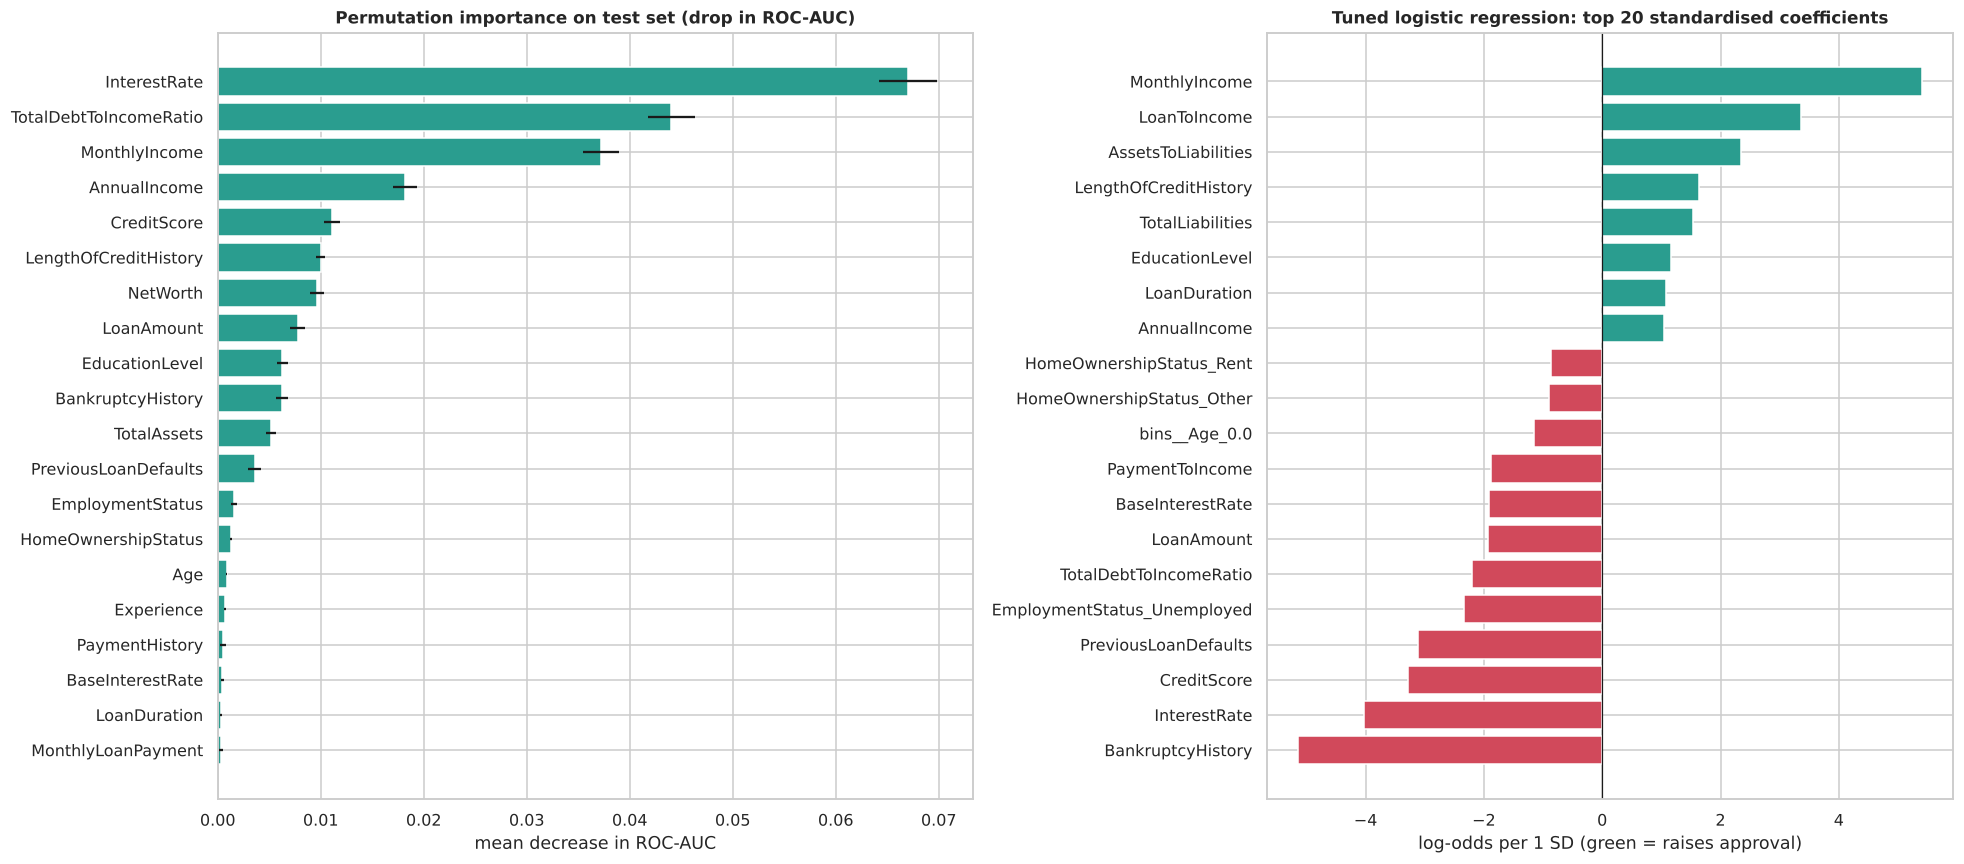

,mean,std,rank
InterestRate,0.0670,0.0028,1
TotalDebtToIncomeRatio,0.0441,0.0023,2
MonthlyIncome,0.0372,0.0018,3
AnnualIncome,0.0182,0.0012,4
CreditScore,0.0111,0.0008,5
LengthOfCreditHistory,0.0100,0.0004,6
NetWorth,0.0096,0.0007,7
LoanAmount,0.0077,0.0007,8
EducationLevel,0.0063,0.0005,9
BankruptcyHistory,0.0062,0.0006,10


In [49]:
t0 = time.time()
perm = permutation_importance(final_base, X_test, y_test, scoring='roc_auc', n_repeats=8,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std}, index=X_test.columns).sort_values('mean')
print(f'Permutation importance computed in {time.time()-t0:.0f}s')

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1.1, 1]})
top = imp.tail(20)
axes[0].barh(top.index, top['mean'], xerr=top['std'], color='#2a9d8f')
axes[0].set(title='Permutation importance on test set (drop in ROC-AUC)', xlabel='mean decrease in ROC-AUC')

# Model-specific view: standardised logistic-regression coefficients (tuned LR) -> odds ratios
lr_model = lr_grid.best_estimator_
feat_names = lr_model[:-1].get_feature_names_out()
coefs = pd.Series(lr_model.named_steps['model'].coef_[0], index=feat_names)
coefs.index = coefs.index.str.replace(r'^[a-z]+__', '', regex=True)
topc = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(20).sort_values()
axes[1].barh(topc.index, topc.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in topc.values])
axes[1].axvline(0, color='k', lw=.8)
axes[1].set(title='Tuned logistic regression: top 20 standardised coefficients', xlabel='log-odds per 1 SD (green = raises approval)')
plt.tight_layout(); plt.show()

imp.sort_values('mean', ascending=False).head(12).assign(rank=range(1, 13))

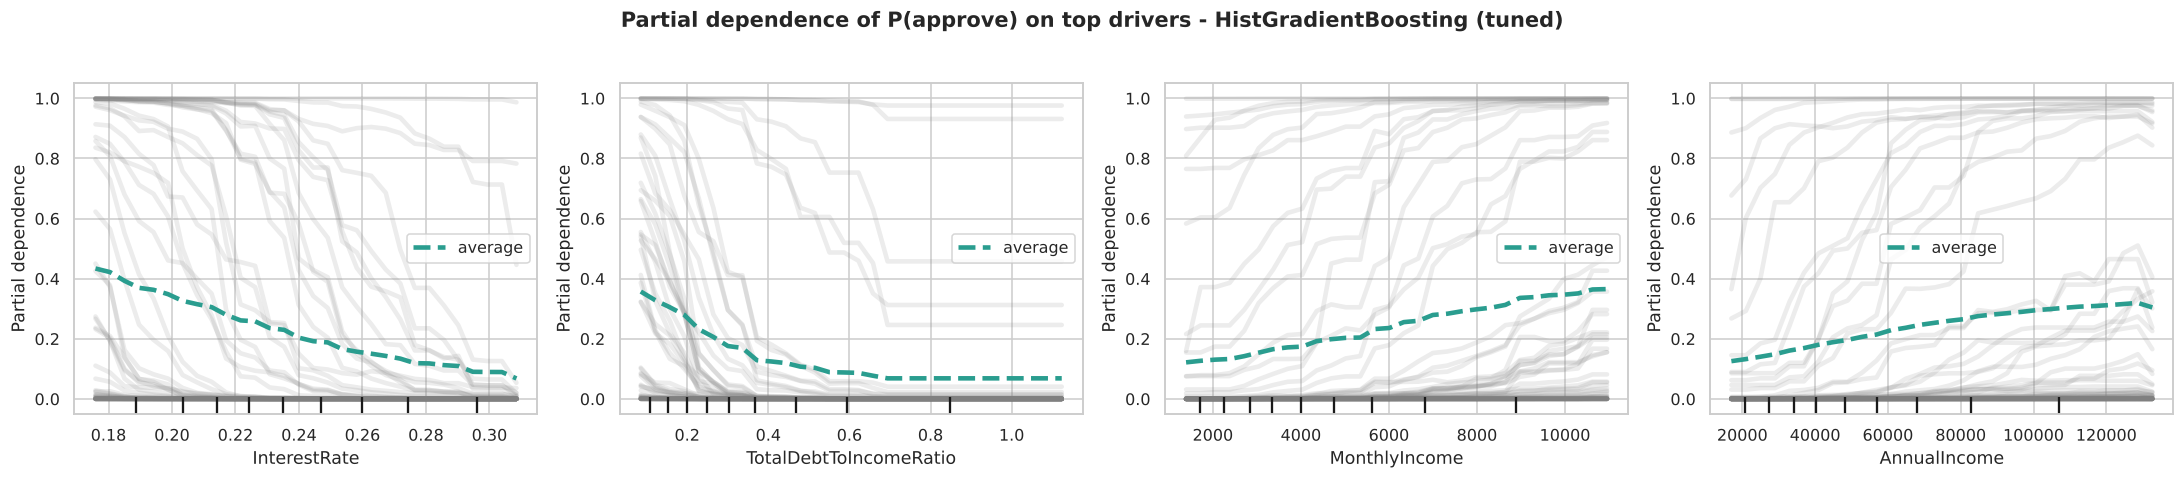

In [50]:
# How do the top drivers shape the prediction? Partial dependence (average) + ICE-style individual curves
top_num = [c for c in imp.sort_values('mean', ascending=False).index if c in NUMERIC_CONT + NUMERIC_DISC][:4]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
PartialDependenceDisplay.from_estimator(final_base, X_test.sample(800, random_state=RANDOM_STATE), top_num, kind='both',
                                        subsample=60, random_state=RANDOM_STATE, ax=axes, grid_resolution=30,
                                        line_kw={'color': '#2a9d8f', 'lw': 3}, ice_lines_kw={'alpha': .15, 'color': 'grey'})
plt.suptitle(f'Partial dependence of P(approve) on top drivers - {FINAL_NAME}', fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

**What drives the decisions, and what it means for the business:** * **Pricing and affordability dominate.** `InterestRate` is the most important input. Rates are themselves priced from credit score, loan size and term, so the rate acts as a compact summary of credit risk. Next come **total debt-to-income** and **income** (monthly and annual together), then **credit score, length of credit history, net worth and loan amount**. **Bankruptcy history, education and previous defaults** contribute smaller but clear effects. Age, experience, marital status, purpose and the behavioural variables (utility payments, card utilisation, inquiries) contribute almost nothing.
* The **partial-dependence plots** show economically sensible, monotonic effects. Approval probability falls steadily as the interest rate rises, falls sharply as total DTI rises to about 0.4 and then flattens near zero, and rises steadily with income. The model has learned the kind of rules a credit committee would endorse.
* The **logistic-regression coefficients** tell the same story: income, assets-to-liabilities and credit history raise approval odds; bankruptcy, interest rate, previous defaults, unemployment and high DTI lower them. Two cautions: (1) binary features such as `BankruptcyHistory` are not standardised, so their coefficient is the effect of 0 → 1, not of one standard deviation; (2) heavy collinearity (VIF > 100 for the income pair) means individual signs can be misleading. `LoanToIncome` appears with a positive sign only because loan amount and income are also in the model. This is why permutation importance is our primary interpretation tool.

**Business recommendations from the drivers**
1. **Affordability is the lever.** Applicants near the boundary because of DTI or loan size could be offered a **smaller loan or longer term** rather than an outright decline. That turns some \$8k false denials into profitable loans.
2. **Interest-rate pricing and approval are tightly linked.** Because the rate both reflects and drives risk, pricing and credit policy should be reviewed together.
3. **Make sure income data is reliable.** Income is the most influential *applicant-supplied* figure, and the data contains censored (\$15k floor) and inconsistent (monthly × 12 ≠ annual) values. Automated income verification would directly improve decision quality.
4. **Drop features with no value** (marital status, dependents) to simplify the application and reduce fair-lending exposure.

### 5.6 Sensitivity check: the leaky `EducationLevel` missingness flag
In §2.8 we found that every application with missing education was denied, and deliberately withheld that pattern from the model. Here we measure what the model *would* gain by exploiting it – i.e. how much apparent performance would be an artefact of the data-collection process.

In [51]:
p_flag = clone(final_base).set_params(features__flag_edu_missing=True)
p_flag.named_steps['prep'].transformers.append(('edu_missing', 'passthrough', ['EducationMissing']))
rows = []
for label, pipe in [('Final model (education missingness NOT used)', final_base),
                    ('With EducationMissing flag (leaky)', p_flag)]:
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    pt = clone(pipe).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    rows.append({'variant': label, 'CV cost / app ($)': -res['test_cost'].mean(), 'CV ROC-AUC': res['test_roc_auc'].mean(),
                 'Test ROC-AUC': roc_auc_score(y_test, pt),
                 'Test cost / app ($)': cost_per_application(y_test, (pt >= OPT_THRESHOLD).astype(int)),
                 'Test FP on missing-education rows': int(((pt >= OPT_THRESHOLD) & X_test['EducationLevel'].isna().values).sum())})
pd.DataFrame(rows).set_index('variant').style.format({'CV cost / app ($)': '${:,.0f}', 'CV ROC-AUC': '{:.4f}',
                                                      'Test ROC-AUC': '{:.4f}', 'Test cost / app ($)': '${:,.0f}'})

,CV cost / app ($),CV ROC-AUC,Test ROC-AUC,Test cost / app ($),Test FP on missing-education rows
variant,,,,,
Final model (education missingness NOT used),$637,0.9923,0.9935,$617,1
With EducationMissing flag (leaky),$646,0.9929,0.9942,$576,0


**Result:** adding the leaky flag improves the test numbers only slightly (ROC-AUC 0.9935 → 0.9942; test cost \$617 → \$576 per application), and CV cost does not improve at all (\$637 vs \$646, within noise). The final model approves just **1** of the missing-education applicants in the test set even without the flag, because their other characteristics already mark them as high-risk. So excluding the flag costs almost nothing, and the reported performance does **not** depend on a data-collection artefact that may not exist at application time. If the business later confirms that missing education is a genuine applicant-side signal (e.g. the applicant declined to answer), the flag can be switched on with `features__flag_edu_missing=True`.

### 5.7 Limitations and potential biases
| Limitation / bias | Why it matters | Mitigation |
|---|---|---|
| **Labels are historical approval decisions, not repayment outcomes.** The \$50k cost assumes a "should-be-denied" applicant defaults | The model learns to replicate past policy, including any past bias, rather than true default risk. It cannot find good applicants the old process always rejected (selective labels / reject inference problem) | Collect repayment outcomes for approved loans; run a small controlled "approve-and-observe" programme on borderline declines; retrain on default outcomes |
| **Synthetic / partially artificial data** (Kaggle generator + injected mess) | Relationships are cleaner than reality; AUC ≈ 0.99 will not carry over to real portfolios | Validate on real bank data before any rollout; expect lower performance |
| **Leakage risks:** `RiskScore` (post-decision) and outcome-dependent missing `EducationLevel` | Can make a model look perfect offline and fail in production | Both removed / neutralised; data-lineage review of every field before deployment |
| **Average costs** (\$8k / \$50k) applied to every loan | Real losses scale with loan size, term and recovery rate | Use loan-level expected loss (PD × LGD × EAD) when outcome data exist |
| **Equal-opportunity gaps** for low-income, unemployed, less-educated and younger applicants | Creditworthy applicants in these groups are declined more often | Route them to officer review; monitor recall by segment; consider fairness constraints or group-specific thresholds after legal review |
| **Protected / sensitive attributes** (marital status, age, dependents) | Fair-lending regulations | Marital status & dependents dropped at no cost; Age is a compliance decision (§5.4) |
| **No time dimension** (application date removed) | The generator used seasonality; drift over time cannot be assessed | Time-based validation and drift monitoring in production |
| **Censored income** (\$15k floor, \$300k cap) | Under-/over-states some incomes | `IncomeAtFloor` flag; income verification |
| **Multicollinearity** | Unstable individual LR coefficients | Regularisation, model-agnostic permutation importance |

In [52]:
# Persist the production artefact: full pipeline (feature engineering -> preprocessing -> model) + tuned threshold
joblib.dump(final_model, 'loan_approval_model.joblib')
reloaded = joblib.load('loan_approval_model.joblib')
assert (reloaded.predict(X_test) == pred_test).all()
print(f'Saved loan_approval_model.joblib | threshold = {reloaded.best_threshold_:.3f}')

# Example: scoring a new application end-to-end from raw (cleaned) fields
example = X_test.iloc[[0]]
print('P(approve) =', round(reloaded.predict_proba(example)[0, 1], 3), '| decision =', 'APPROVE' if reloaded.predict(example)[0] else 'DENY / REVIEW')

Saved loan_approval_model.joblib | threshold = 0.865
P(approve) = 0.0 | decision = DENY / REVIEW


## 6. Conclusion

### 6.1 Executive summary for business stakeholders
**The problem.** FinTech Innovations' partner banks approve loans by manual review. This is slow and inconsistent, and the cost of mistakes is not managed explicitly. Approving a loan that defaults costs about **\$50,000**; turning away a creditworthy applicant costs about **\$8,000** in lost profit.

**What we built.** We trained a model on 20,000 past applications to estimate the probability that an applicant is creditworthy. We cleaned the data (currency text, inconsistent codes, missing values) and found and removed two hidden "answer-key" fields that would have made the model look perfect on paper but fail in practice. We then compared nine modelling approaches and tuned the two best. Because a bad approval costs 6.25× more than a missed good loan, the model only recommends approval when it is **at least ~86.5% confident**.

**Results on 4,000 applications the model had never seen:**
* **98.6% of approved loans are good loans**: 10 bad approvals in 4,000 decisions.
* **Error costs fall by 68%**, from \$1,912 to **\$617 per application**. That is about **\$25.9M per 20,000 applications** compared with a "deny everyone" policy, and \$6.9M compared with using the same model at the standard 50% cut-off.
* **87% of applications can be decided automatically.** Officers focus on the **13%** that are genuinely borderline.
* **What drives decisions:** debt burden relative to income, income level, the interest rate offered (a summary of credit risk), credit score and credit-history length. **Marital status has no predictive value** and can be dropped.

**What to watch.** The model learned from *past approval decisions*, not from whether loans were actually repaid, so it mirrors past policy. Creditworthy applicants with lower incomes, younger ages or less education are declined somewhat more often. These groups should go to human review, and outcomes should be monitored.

### 6.2 Recommendations for implementation
1. **Pilot as decision support, then automate in tiers.** Run the model in *shadow mode* alongside loan officers for 2–3 months and compare decisions and early repayment. Then switch on **auto-approve (P ≥ 0.865)** and **auto-decline (P ≤ 0.10)**, keeping **officer review for the middle band**.
2. **Keep humans in the loop where the model is weakest.** Send declines for low-income, unemployed and younger applicants with P in the 0.10–0.865 range to review. Officers can offer **counter-offers** (smaller amount, longer term) instead of a flat decline.
3. **Give every decision reason codes.** Use the top contributing features (from the LR challenger and model-agnostic explanations) to produce adverse-action reasons such as "debt-to-income too high". These meet regulatory notice requirements and help officers.
4. **Remove `MaritalStatus` and `NumberOfDependents`** from the production model (no performance cost). Have Compliance decide on `Age`.
5. **Govern the threshold as a business parameter.** If the \$8k / \$50k assumptions change (rates, recovery costs), recompute the threshold as \$FP / (\$FP + \$FN). No retraining is needed.
6. **Monitor in production:** approval rate, precision of approvals, segment-level recall, data drift (PSI) on key inputs, and probability calibration, monthly. Retrain quarterly or when drift alarms fire.
7. **Fix the data pipeline:** store income as numbers, use consistent binary encodings, find out why education is missing only for declined applications, and verify income automatically.
8. **Deploy the saved artefact** `loan_approval_model.joblib`. It contains the full pipeline (cleaned raw fields in → decision out) with the tuned threshold, so training and production apply identical preprocessing.

### 6.3 Potential improvements
* **Train on repayment outcomes** (default / no default) instead of past decisions, and use **reject-inference** techniques to learn about applicants who were historically declined.
* **Loan-level expected-loss modelling:** combine a probability-of-default model with loss-given-default and exposure to replace the flat \$50k / \$8k costs, and optimise profit per loan.
* **Richer explainability:** SHAP values for per-applicant explanations of the boosting model, and monotonic constraints in HistGradientBoosting (e.g. approval may not decrease as income rises) for regulatory robustness.
* **Fairness-aware optimisation:** segment-specific thresholds or post-processing for equal opportunity, evaluated with Legal.
* **Probability calibration layer** (`CalibratedClassifierCV`) and conformal prediction intervals to size the review band more rigorously.
* **More features:** bureau trend data (utilisation history), verified income, bank-transaction behaviour, and application timing (seasonality).
* **Wider search:** Bayesian optimisation (e.g. Optuna) with nested cross-validation, and gradient-boosting libraries such as LightGBM/XGBoost/CatBoost, if the environment allows.
* **Temporal validation:** train on earlier applications and test on later ones to estimate real-world drift.